In [1]:
import sys
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import numpy as np
import seaborn as sns
import pandas as pd
from scipy import stats

## Plotting flower and fruit data

**DATA ANALYSIS**   
Read the clean data file that will be used for the analysis. I set indexing to datetime.  
(see README or/and raw-data-plot.ipynb for cleaning steps). 

In [5]:
# Read the final processed data
df = pd.read_csv('../data/processed/06_FINAL_merged_with_consensus_IntensiveSurvey2025.csv')

# Read the raw csv file containing the master sheet with all the unique plant_IDs
df_list = pd.read_csv("../data/raw/IntensiveSurvey_2025_list_v3.csv")

# Read the final coordinates CSV file for accessing the spatial distribution
df_coordinates = pd.read_csv('../data/processed/unique_coordinates_list.csv') 

Q1: **How does the flowering count and fruit yield change along the season?**

I start by doing the same intital analysis as I did in my raw data visualization where I collapse all individual plants into a single daily total. All flower counts are summed together and all fruit counts are summed together and plotted against the date the survey was performed.

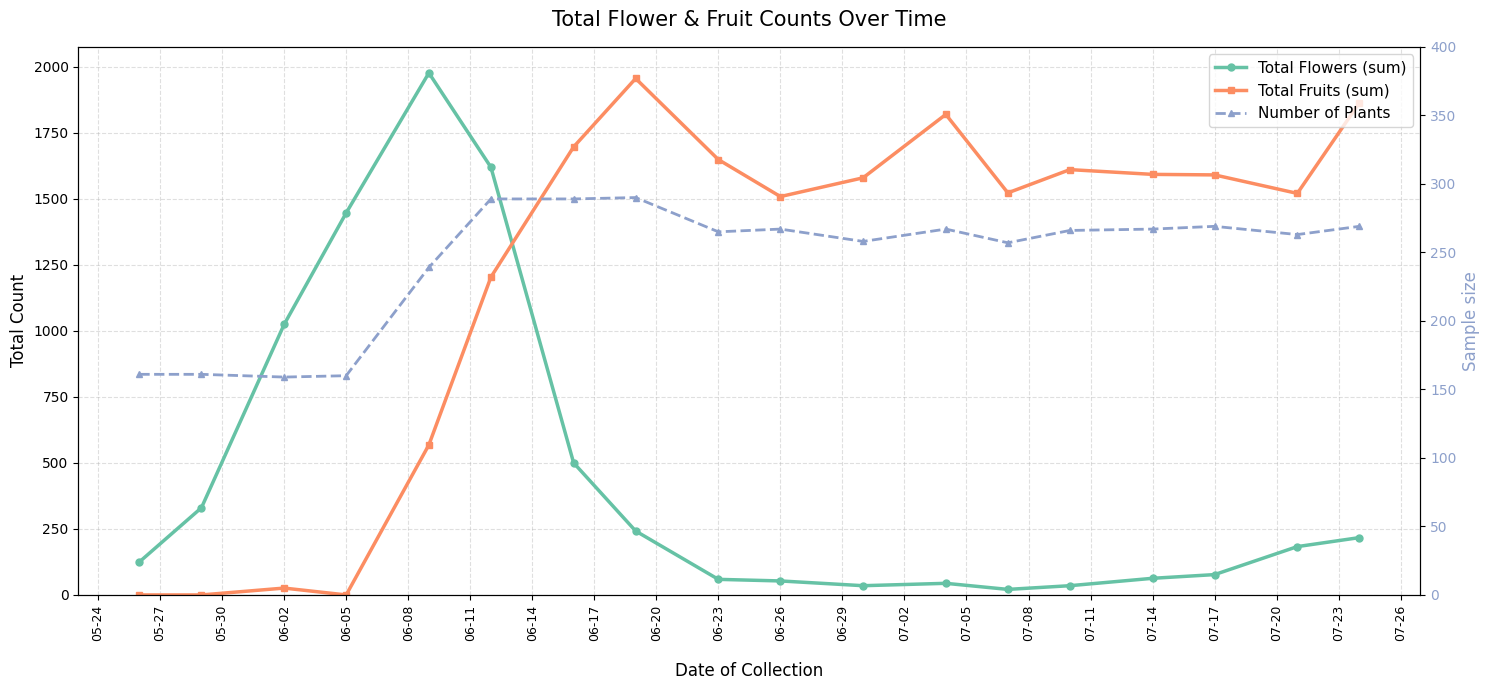

In [10]:
df['end'] = pd.to_datetime(df['end'])  # Ensure 'end' is in datetime format

# Group by date and sum flowers/fruits, then count unique PlantIDs by date
daily_totals = (
    df.groupby(df["end"].dt.floor("D"))
    .agg(
        {
            "Estim.Flowers.Nr": "sum",
            "Estim.Fruits.Nr": "sum",
            "PlantID": "nunique",  # Counts unique plants per date
        }
    )
    .sort_index()
)

# Set plotting size
fig, ax = plt.subplots(figsize=(15, 7))

# Plot Total Flowers against date
ax.plot(
    daily_totals.index,
    daily_totals["Estim.Flowers.Nr"],
    color="#66c2a5",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Total Flowers (sum)",
)

# Plot Total Fruits against date
ax.plot(
    daily_totals.index,
    daily_totals["Estim.Fruits.Nr"],
    color="#fc8d62",
    linewidth=2.5,
    marker="s",
    markersize=5,
    label="Total Fruits (sum)",
)

# Plot Frequency of samples on a secondary axis
ax2 = ax.twinx()
ax2.plot(
    daily_totals.index,
    daily_totals["PlantID"],
    color="#8da0cb",
    linestyle="--",
    linewidth=2,
    marker="^",
    markersize=5,
    label="Number of Plants",
)

# Since max plants = 296, setting bounds to (0, 400) so that the secondary axis is not too tight or so that the curve is covered by the primary axis.
ax2.set_ylim(0, 400)
ax.set_ylim(bottom=0)

# Date formatting
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

# Rotate x-axis labels cleanly
ax.tick_params(axis="x", rotation=90, labelsize=9)

# Labels & Design
ax.set_title(
    "Total Flower & Fruit Counts Over Time",
    fontsize=15,
    pad=15,
)
ax.set_xlabel("Date of Collection", fontsize=12, labelpad=15)
ax.set_ylabel("Total Count", fontsize=12)
ax2.set_ylabel("Sample size", fontsize=12, color="#8da0cb")
ax2.tick_params(axis="y", labelcolor="#8da0cb")

ax.grid(True, linestyle="--", alpha=0.4)

# Combined Legend
lines_1, labels_1 = ax.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper right",
    fontsize=11,
    frameon=True,
)

plt.tight_layout()
plt.savefig("../results/plot_01.png", dpi=300)
plt.show()

Here I am running diagnostic of the data file, this is to make sure the analysis is using the filtered data that only contain the plants from the survey. 

In [ ]:
# Calculate total unique plants across the entire survey period, this should be 298!!! The reason why it is 296 is because I removed two samples tha tonly occured twice and were not representative of the overall survey.
total_unique_plants = df["PlantID"].nunique()

print(
    f"Total unique plants involved in the entire survey: {total_unique_plants}"
)

Total unique plants involved in the entire survey: 297


I wanted to do a control check that my final PROCESSED DATA file doesn't have any duplicates left.

In [ ]:
# Ensure 'end' is a column (not the index)
if "end" not in df.columns:
    df = df.reset_index()

# 1. Standardize date format (extract YYYY-MM-DD string)
df["date_str"] = pd.to_datetime(df["end"]).dt.strftime("%Y-%m-%d")

# 2. Find all duplicate observations on the same date for the same plant
# keep=False flags ALL occurrences of a duplicate so you can inspect them
duplicate_mask = df.duplicated(subset=["date_str", "PlantID"], keep=False)
duplicates_df = df[duplicate_mask].copy()

# 3. Print summary of duplicates across all dates
total_dupes = len(duplicates_df)
print(f"=== DUPLICATE RECORDINGS REPORT ===")
print(
    f"Total duplicate rows across all dates: {total_dupes} (out of {len(df)} total rows)"
)

if total_dupes > 0:
    # Group by Date and PlantID to count how many times each plant was recorded per day
    dupe_summary = (
        duplicates_df.groupby(["date_str", "PlantID"])
        .size()
        .reset_index(name="record_count")
        .sort_values(by=["date_str", "record_count"], ascending=[True, False])
    )

    print("\nDates and PlantIDs with multiple entries:")
    print(dupe_summary.to_string(index=False))

    print("\nFull details of duplicated rows:")
    # Print the specific raw rows (useful for inspecting why they were duplicated)
    print(
        duplicates_df[
            ["date_str", "PlantID", "Estim.Flowers.Nr", "Estim.Fruits.Nr"]
        ]
        .sort_values(by=["date_str", "PlantID"])
        .to_string(index=False)
    )
else:
    print("No duplicate PlantIDs found on any single date!")

=== DUPLICATE RECORDINGS REPORT ===
Total duplicate rows across all dates: 0 (out of 4396 total rows)
No duplicate PlantIDs found on any single date!


Just as a diagnostic I am plotting the frequency of samples in the survey for each date.

In [ ]:
# Print plant counts
print("--- PLANT COUNTS PER SESSION ---")
for date, group in df.groupby("end"):
    print(
        f"Date: {date.strftime('%Y-%m-%d')} | Unique PlantIDs: {group['PlantID'].nunique()}"
    )

--- PLANT COUNTS PER SESSION ---
Date: 2025-05-26 | Unique PlantIDs: 161
Date: 2025-05-29 | Unique PlantIDs: 161
Date: 2025-06-02 | Unique PlantIDs: 159
Date: 2025-06-05 | Unique PlantIDs: 160
Date: 2025-06-09 | Unique PlantIDs: 239
Date: 2025-06-12 | Unique PlantIDs: 289
Date: 2025-06-16 | Unique PlantIDs: 289
Date: 2025-06-19 | Unique PlantIDs: 290
Date: 2025-06-23 | Unique PlantIDs: 265
Date: 2025-06-26 | Unique PlantIDs: 267
Date: 2025-06-30 | Unique PlantIDs: 258
Date: 2025-07-04 | Unique PlantIDs: 267
Date: 2025-07-07 | Unique PlantIDs: 257
Date: 2025-07-10 | Unique PlantIDs: 266
Date: 2025-07-14 | Unique PlantIDs: 267
Date: 2025-07-17 | Unique PlantIDs: 269
Date: 2025-07-21 | Unique PlantIDs: 263
Date: 2025-07-24 | Unique PlantIDs: 269


**DATA ANALYSIS**

Q2: **How is flowering and fruit production distrubuted mothly?**

 I start by plotting the data as box plots to see how the flower 
count vs fruit counts change over the season for different months. 
        
*Key Insights:*
* May: Dominated by heavy vegetative/flowering investment.
* June/July: Flower production tapers off as energy shifts entirely into fruit maturation.
* Outliers: Individual plants showing extremely high yields highlight high-performing variants.

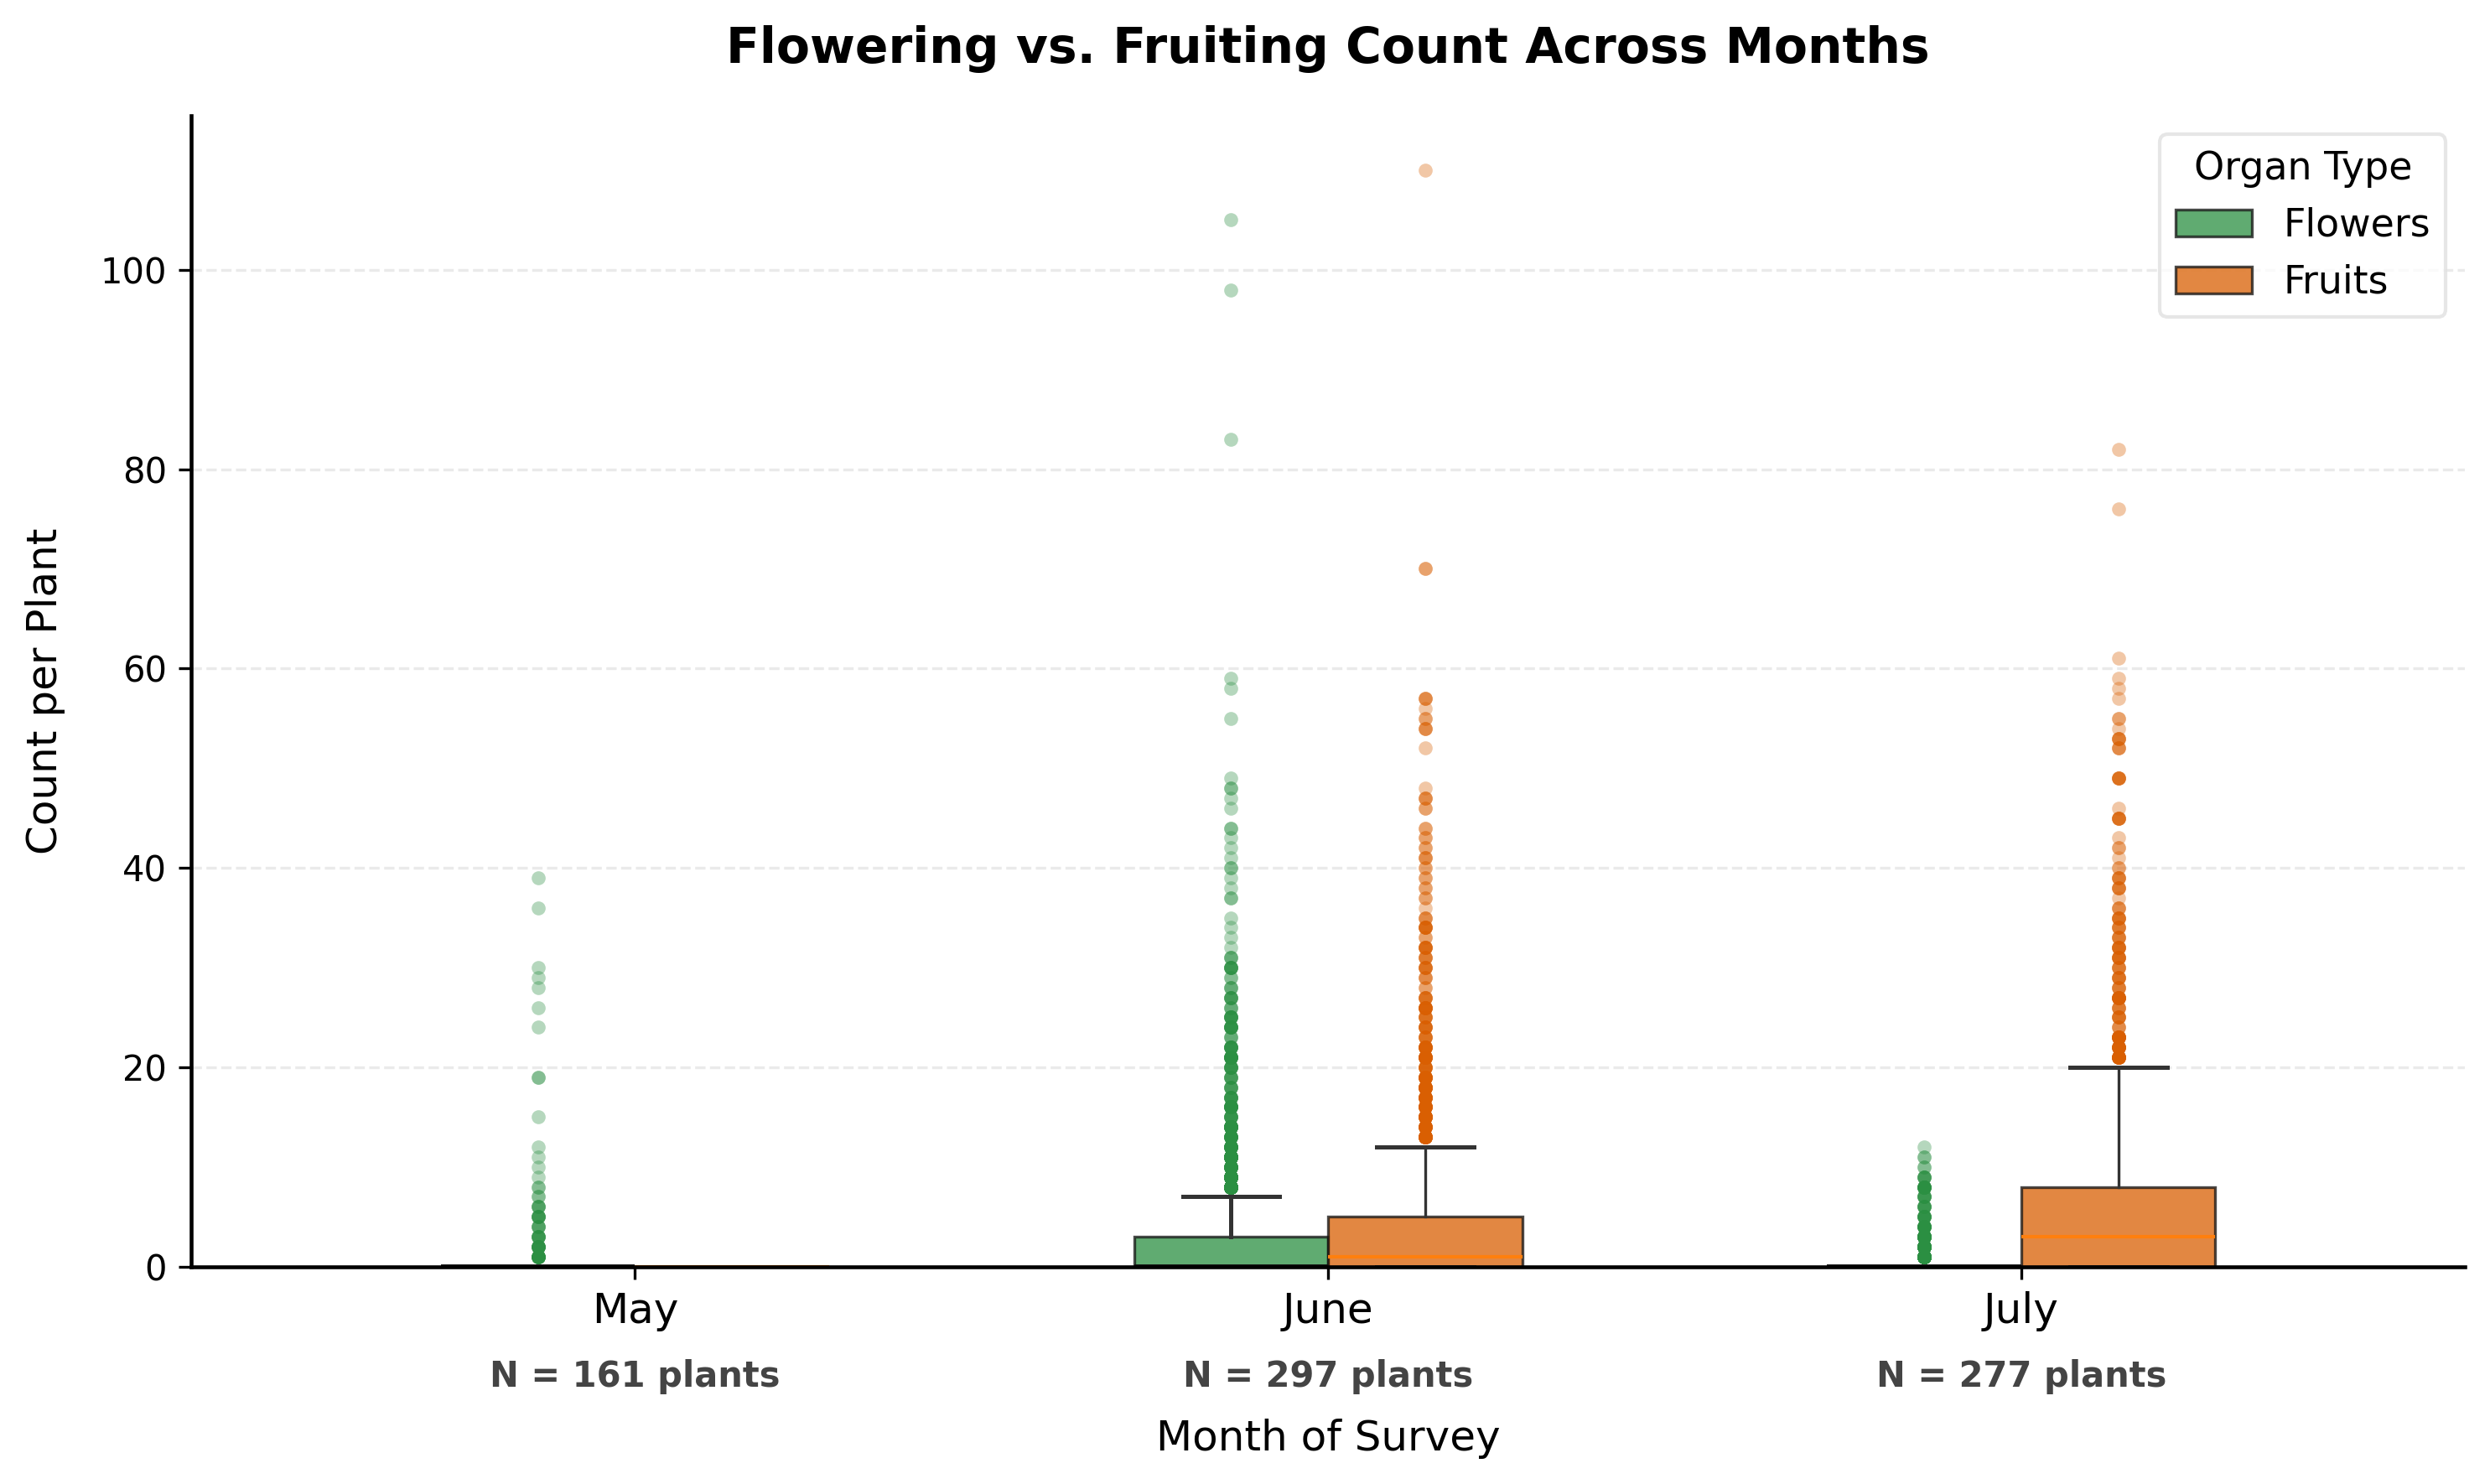

In [ ]:
# Ensure 'Month' column exists in your DataFrame
if "end" in df.columns:
    df["Month"] = pd.to_datetime(df["end"]).dt.month_name()
elif isinstance(df.index, pd.DatetimeIndex):
    df["Month"] = df.index.month_name()
else:
    raise KeyError("Could not find a date column or DatetimeIndex to create 'Month'.")

month_order = ["May", "June", "July"]

# Extract flower and fruit data per month
flower_data = [df[df["Month"] == m]["Estim.Flowers.Nr"].dropna() for m in month_order]
fruit_data = [df[df["Month"] == m]["Estim.Fruits.Nr"].dropna() for m in month_order]

# Sample sizes (unique plants surveyed per month)
sample_sizes = [df[df["Month"] == m]["PlantID"].nunique() for m in month_order]

# Setup Figure & Axes
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

x = np.arange(len(month_order))
width = 0.28  # Box width

# Color Palette (Botanical Teal/Green for Flowers, Warm Coral for Fruits)
color_flowers = "#2b8f42"
color_fruits = "#d95f02"

# Plot Flower Boxplots (Shifted left)
bp_flowers = ax.boxplot(
    flower_data,
    positions=x - width / 2,
    widths=width,
    patch_artist=True,
    boxprops=dict(facecolor=color_flowers, alpha=0.75, edgecolor="#111111", linewidth=0.8),
    medianprops=dict(color="#111111", linewidth=1.4),
    whiskerprops=dict(color="#333333", linewidth=1.2),
    capprops=dict(color="#333333", linewidth=1.2),
    flierprops=dict(
        marker="o",
        markersize=4,
        markerfacecolor=color_flowers,
        alpha=0.35,
        markeredgecolor="none",
    ),
)

# Plot Fruit Boxplots (Shifted right)
bp_fruits = ax.boxplot(
    fruit_data,
    positions=x + width / 2,
    widths=width,
    patch_artist=True,
    boxprops=dict(facecolor=color_fruits, alpha=0.75, edgecolor="#111111", linewidth=0.8),
    whiskerprops=dict(color="#333333", linewidth=0.8),
    capprops=dict(color="#333333", linewidth=1.2),
    flierprops=dict(
        marker="o",
        markersize=4,
        markerfacecolor=color_fruits,
        alpha=0.35,
        markeredgecolor="none",
    ),
)

# Add Sample Size (N = ...) annotations along the X-axis
for i, n in enumerate(sample_sizes):
    ax.text(
        i,
        -0.08,
        f"N = {n} plants",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color="#444444",
    )

# 7. Formatting & Layout Polish
ax.set_xticks(x)
ax.set_xticklabels(month_order, fontsize=12)
ax.set_ylabel("Count per Plant", fontsize=12, labelpad=10)
ax.set_xlabel("Month of Survey", fontsize=12, labelpad=25)
ax.set_title(
    "Flowering vs. Fruiting Count Across Months",
    fontsize=14,
    pad=15,
    fontweight="bold",
)

ax.set_ylim(bottom=0)

# Remove top and right box spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.1)
ax.spines["bottom"].set_linewidth(1.1)

# Subtle background grid lines for y-axis only
ax.grid(axis="y", linestyle="--", alpha=0.4, color="#cccccc")
ax.set_axisbelow(True)

# Clean Legend
ax.legend(
    [bp_flowers["boxes"][0], bp_fruits["boxes"][0]],
    ["Flowers", "Fruits"],
    title="Organ Type",
    title_fontsize=11,
    fontsize=11,
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#e0e0e0",
)

plt.tight_layout()

# Save publication-quality figure
plt.savefig("../results/flower_fruit_seasonal_boxplot.png", dpi=300)
plt.show()

Q3: **Does plants with flowers later in the season have a higher efficiency?**

 I isolate the subset of plants exhibiting late-season flowering 
(defined as plants with active flower counts in July) and plot them against the max yield of fruits divided by total flowers. 
We compare these late-season flowering plants to plants where no flowers were observed in July.
            

=== CATEGORY 1: ALL JULY VS. NO JULY ===
Sample Sizes: No July (N = 166), All July (N = 104)
Mann-Whitney U: U = 9331.5, p = 2.6160e-01
Welch's t-test: t = 1.242, p = 2.1536e-01

=== CATEGORY 2: LATE JULY (JULY 17-31) VS. NO JULY ===
Sample Sizes: No July (N = 186), Late July (N = 84)
Mann-Whitney U: U = 7840.0, p = 9.6297e-01
Welch's t-test: t = 0.186, p = 8.5237e-01

% Keynote LaTeX (All July vs No July):
\begin{aligned}
\text{Sample Sizes: } & N=166, \enspace N_{July}=104 \\
\textbf{Mann-Whitney } U \text{ Test: } & U = 9331.5, \enspace p = 0.2616 \\
\textbf{Welch's } t\text{-test: } & t = 1.242, \enspace p = 0.2154
\end{aligned}

% Keynote LaTeX (Late July (17-31) vs No July):
\begin{aligned}
\text{Sample Sizes: } & N=186, \enspace N_{July}=84 \\
\textbf{Mann-Whitney } U \text{ Test: } & U = 7840.0, \enspace p = 0.9630 \\
\textbf{Welch's } t\text{-test: } & t = 0.186, \enspace p = 0.8524
\end{aligned}


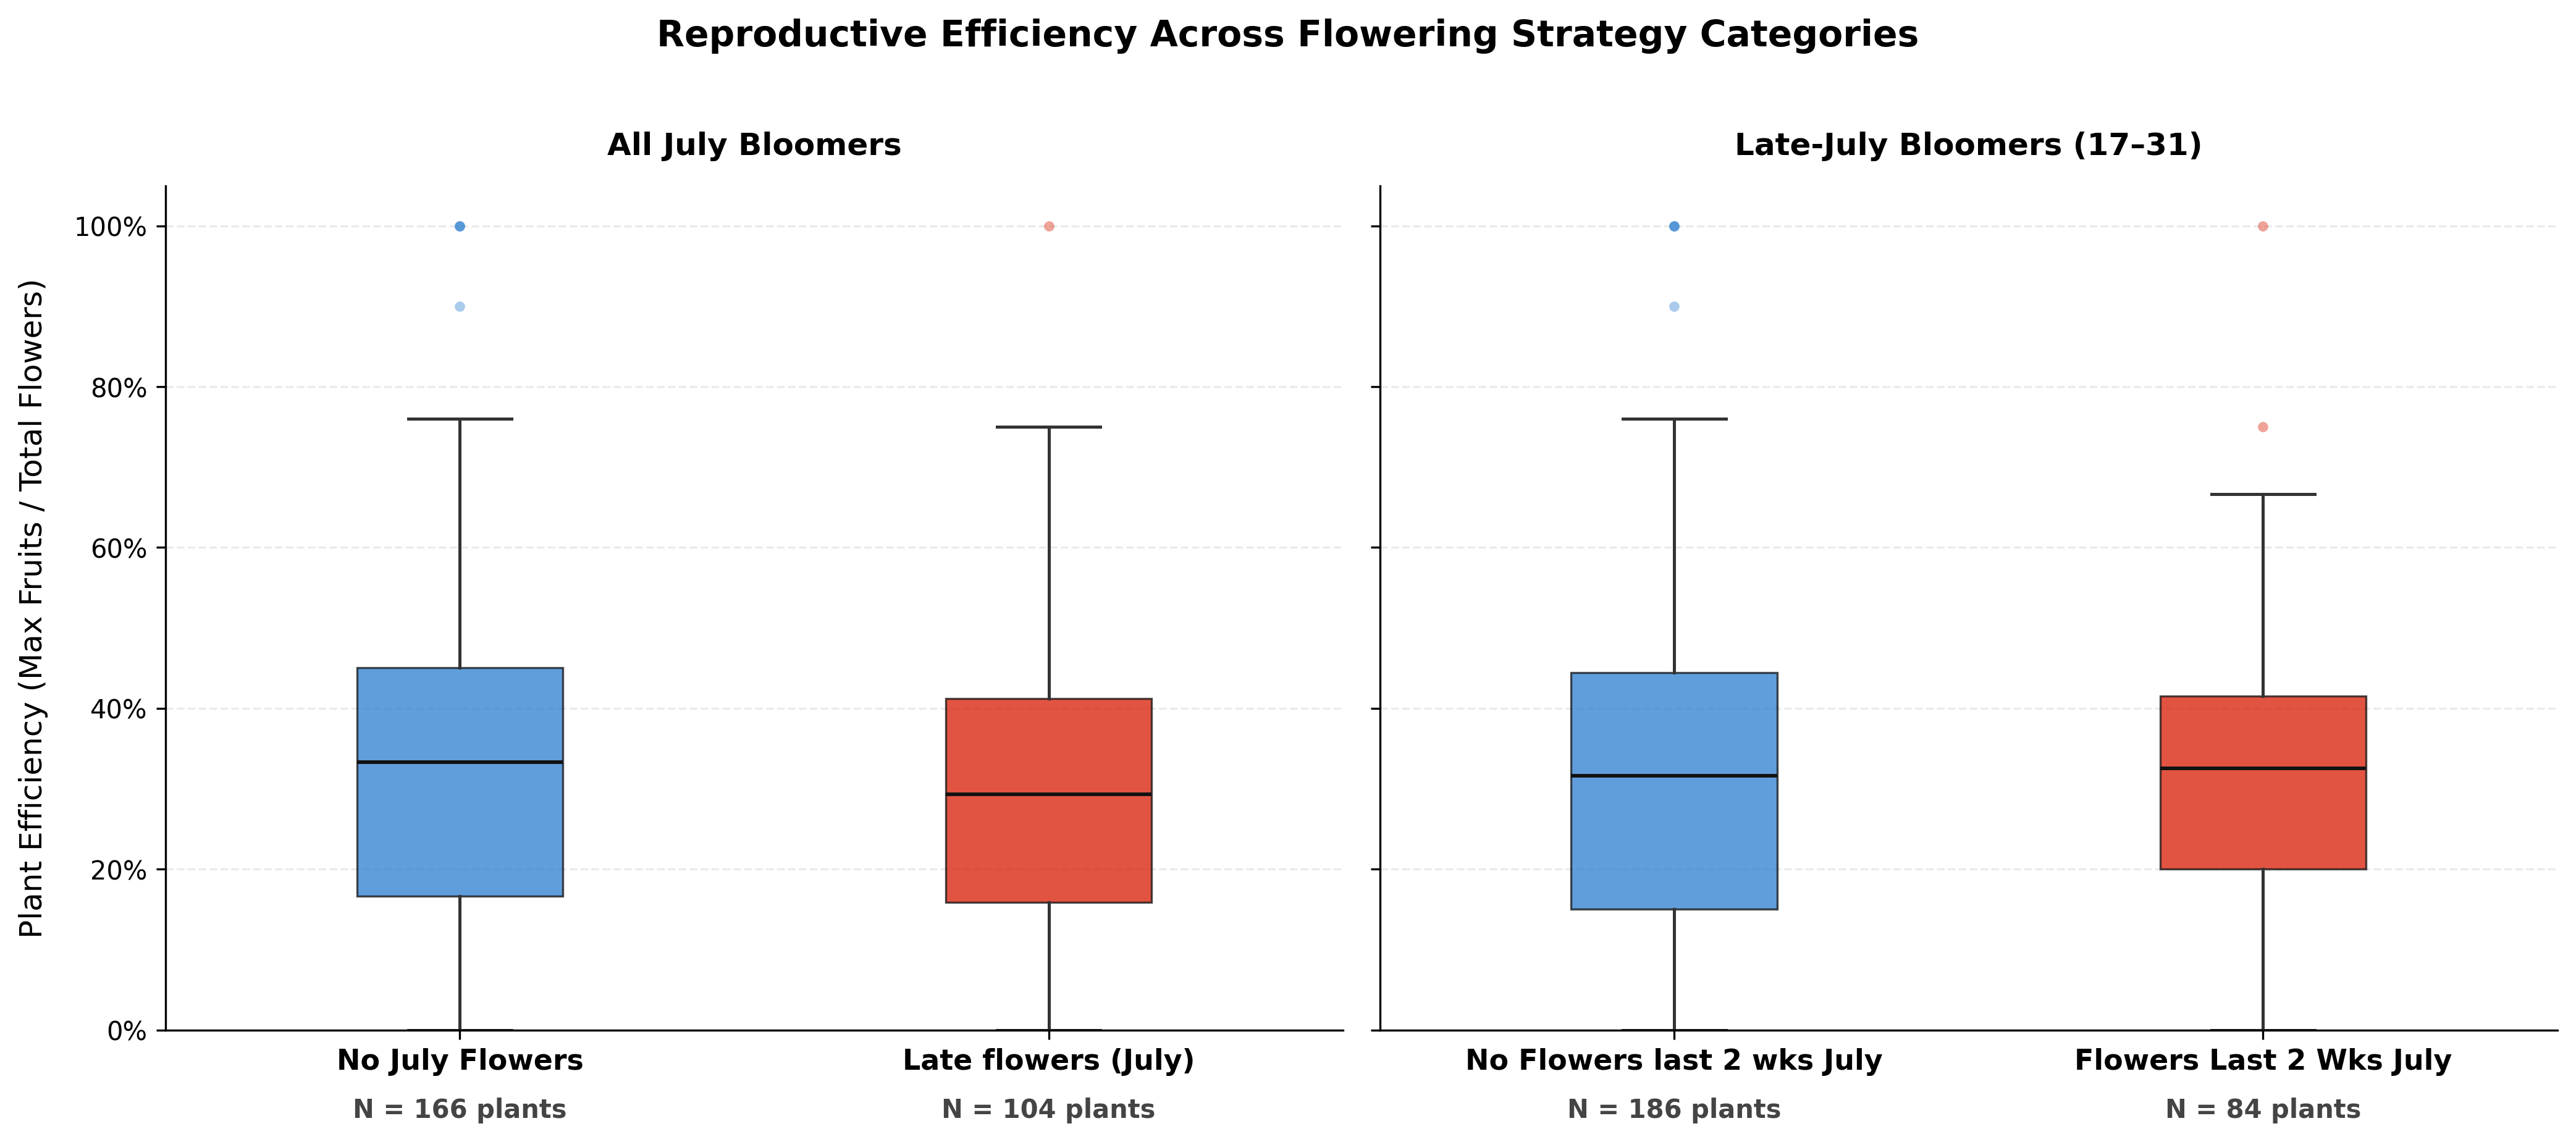

In [ ]:
# 1. PARSE DATES & PREPARE DATASET
if "end" in df.columns:
    df["Date_Parsed"] = pd.to_datetime(df["end"])
elif isinstance(df.index, pd.DatetimeIndex):
    df["Date_Parsed"] = df.index
else:
    raise KeyError("Could not find a date column or DatetimeIndex.")

df["Month"] = df["Date_Parsed"].dt.month_name()
df["Day"] = df["Date_Parsed"].dt.day
df["PlantID"] = df["PlantID"].astype(str).str.strip()

# 2. IDENTIFY FLOWERING COHORTS
# Cohort A: Any July blooming
july_bloomers = df[(df["Month"] == "July") & (df["Estim.Flowers.Nr"] > 0)]["PlantID"].unique()

# Cohort B: Late July blooming (July 17 to July 31)
late_july_bloomers = df[
    (df["Month"] == "July") & (df["Day"] >= 17) & (df["Estim.Flowers.Nr"] > 0)
]["PlantID"].unique()

# 3. CALCULATE EFFICIENCY PER PLANT & FILTER OUTLIERS (>100%)
efficiency_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

efficiency_df = efficiency_df[efficiency_df["flower_total"] > 0].copy()
efficiency_df["Efficiency_Pct"] = (efficiency_df["seed_max"] / efficiency_df["flower_total"]) * 100

# Biological range filter (0% - 100%)
efficiency_df = efficiency_df[efficiency_df["Efficiency_Pct"] <= 100].copy()

# 4. ASSIGN GROUPS FOR BOTH CATEGORIES
efficiency_df["Group_All_July"] = np.where(
    efficiency_df["PlantID"].isin(july_bloomers),
    "July Bloomers",
    "No July Flowers",
)

efficiency_df["Group_Late_July"] = np.where(
    efficiency_df["PlantID"].isin(late_july_bloomers),
    "Late July (17-31)",
    "No July Flowers",
)

# 5. STATISTICAL ANALYSIS FUNCTION
def run_stat_test(df_subset, group_col, group_names):
    g0 = df_subset[df_subset[group_col] == group_names[0]]["Efficiency_Pct"].dropna()
    g1 = df_subset[df_subset[group_col] == group_names[1]]["Efficiency_Pct"].dropna()
    
    u_stat, p_mwu = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    t_stat, p_welch = stats.ttest_ind(g0, g1, equal_var=False)
    
    return {
        "n0": len(g0), "n1": len(g1),
        "mean0": g0.mean(), "mean1": g1.mean(),
        "med0": g0.median(), "med1": g1.median(),
        "u_stat": u_stat, "p_mwu": p_mwu,
        "t_stat": t_stat, "p_welch": p_welch,
        "data0": g0, "data1": g1
    }

res_cat1 = run_stat_test(efficiency_df, "Group_All_July", ["No July Flowers", "July Bloomers"])
res_cat2 = run_stat_test(efficiency_df, "Group_Late_July", ["No July Flowers", "Late July (17-31)"])

# 6. TERMINAL & LATEX OUTPUTS
print("=== CATEGORY 1: ALL JULY VS. NO JULY ===")
print(f"Sample Sizes: No July (N = {res_cat1['n0']}), All July (N = {res_cat1['n1']})")
print(f"Mann-Whitney U: U = {res_cat1['u_stat']:.1f}, p = {res_cat1['p_mwu']:.4e}")
print(f"Welch's t-test: t = {res_cat1['t_stat']:.3f}, p = {res_cat1['p_welch']:.4e}\n")

print("=== CATEGORY 2: LATE JULY (JULY 17-31) VS. NO JULY ===")
print(f"Sample Sizes: No July (N = {res_cat2['n0']}), Late July (N = {res_cat2['n1']})")
print(f"Mann-Whitney U: U = {res_cat2['u_stat']:.1f}, p = {res_cat2['p_mwu']:.4e}")
print(f"Welch's t-test: t = {res_cat2['t_stat']:.3f}, p = {res_cat2['p_welch']:.4e}\n")

# Format Keynote LaTeX
def get_latex_string(title, res):
    p_mwu = "< 0.001" if res['p_mwu'] < 0.001 else f"= {res['p_mwu']:.4f}"
    p_welch = "< 0.001" if res['p_welch'] < 0.001 else f"= {res['p_welch']:.4f}"
    return f"""% Keynote LaTeX ({title}):
\\begin{{aligned}}
\\text{{Sample Sizes: }} & N={res['n0']}, \\enspace N_{{July}}={res['n1']} \\\\
\\textbf{{Mann-Whitney }} U \\text{{ Test: }} & U = {res['u_stat']:.1f}, \\enspace p {p_mwu} \\\\
\\textbf{{Welch's }} t\\text{{-test: }} & t = {res['t_stat']:.3f}, \\enspace p {p_welch}
\\end{{aligned}}"""

print(get_latex_string("All July vs No July", res_cat1))
print("\n" + get_latex_string("Late July (17-31) vs No July", res_cat2))

# 7. COMPARATIVE PLOTTING (SIDE-BY-SIDE)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300, sharey=True)

def plot_boxplot(ax, data_list, labels, sample_sizes, title, color_accent):
    x = np.arange(len(labels))
    bp = ax.boxplot(
        data_list, positions=x, widths=0.35, patch_artist=True,
        boxprops=dict(edgecolor="#111111", linewidth=0.8),
        medianprops=dict(color="#111111", linewidth=1.4),
        whiskerprops=dict(color="#333333", linewidth=1.2),
        capprops=dict(color="#333333", linewidth=1.2),
        flierprops=dict(marker="o", markersize=4, alpha=0.4, markeredgecolor="none")
    )
    
    colors = ["#2b7dcf", color_accent]
    for patch, flier, c in zip(bp["boxes"], bp["fliers"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.75)
        flier.set_markerfacecolor(c)
        
    for i, n in enumerate(sample_sizes):
        ax.text(i, -0.08, f"N = {n} plants", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, fontweight="bold", color="#444444")
        
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=11, fontweight="bold")
    ax.set_title(title, fontsize=12, pad=12, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4, color="#cccccc")
    ax.set_axisbelow(True)

plot_boxplot(ax1, [res_cat1['data0'], res_cat1['data1']], 
             ["No July Flowers", "Late flowers (July)"], [res_cat1['n0'], res_cat1['n1']], 
             "All July Bloomers", "#d91b02")

plot_boxplot(ax2, [res_cat2['data0'], res_cat2['data1']], 
             ["No Flowers last 2 wks July", "Flowers Last 2 Wks July"], [res_cat2['n0'], res_cat2['n1']], 
             "Late-July Bloomers (17–31)", "#d91b02")

ax1.set_ylabel("Plant Efficiency (Max Fruits / Total Flowers)", fontsize=12, labelpad=10)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())
ax1.set_ylim(bottom=0, top=105)

plt.suptitle("Reproductive Efficiency Across Flowering Strategy Categories", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../results/july_vs_late_july_efficiency_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Q3: **Does plants with high flower count on average have a higher yield of fruits?**


To visualize the efficiency of flower to fruit ratio, I extract the max count of number of fruits and the total number of flowers counted for each plant ID. I then score each plant as the percentage of max number of fruits divided by total number of flowers. 
$$\text{Efficiency Score} = \left( \frac{\text{Max Fruits}}{\text{Total Flowers}} \right) \times 100$$
This score is then what I use to range each plant.

--- IMPORTANT ---  
Some plants showed efficiency scores above 100%. This is likely due to undercounting total flowers during the survey such as, missing individual stems on larger plants, which resulted in a lower total count than the actual amount.

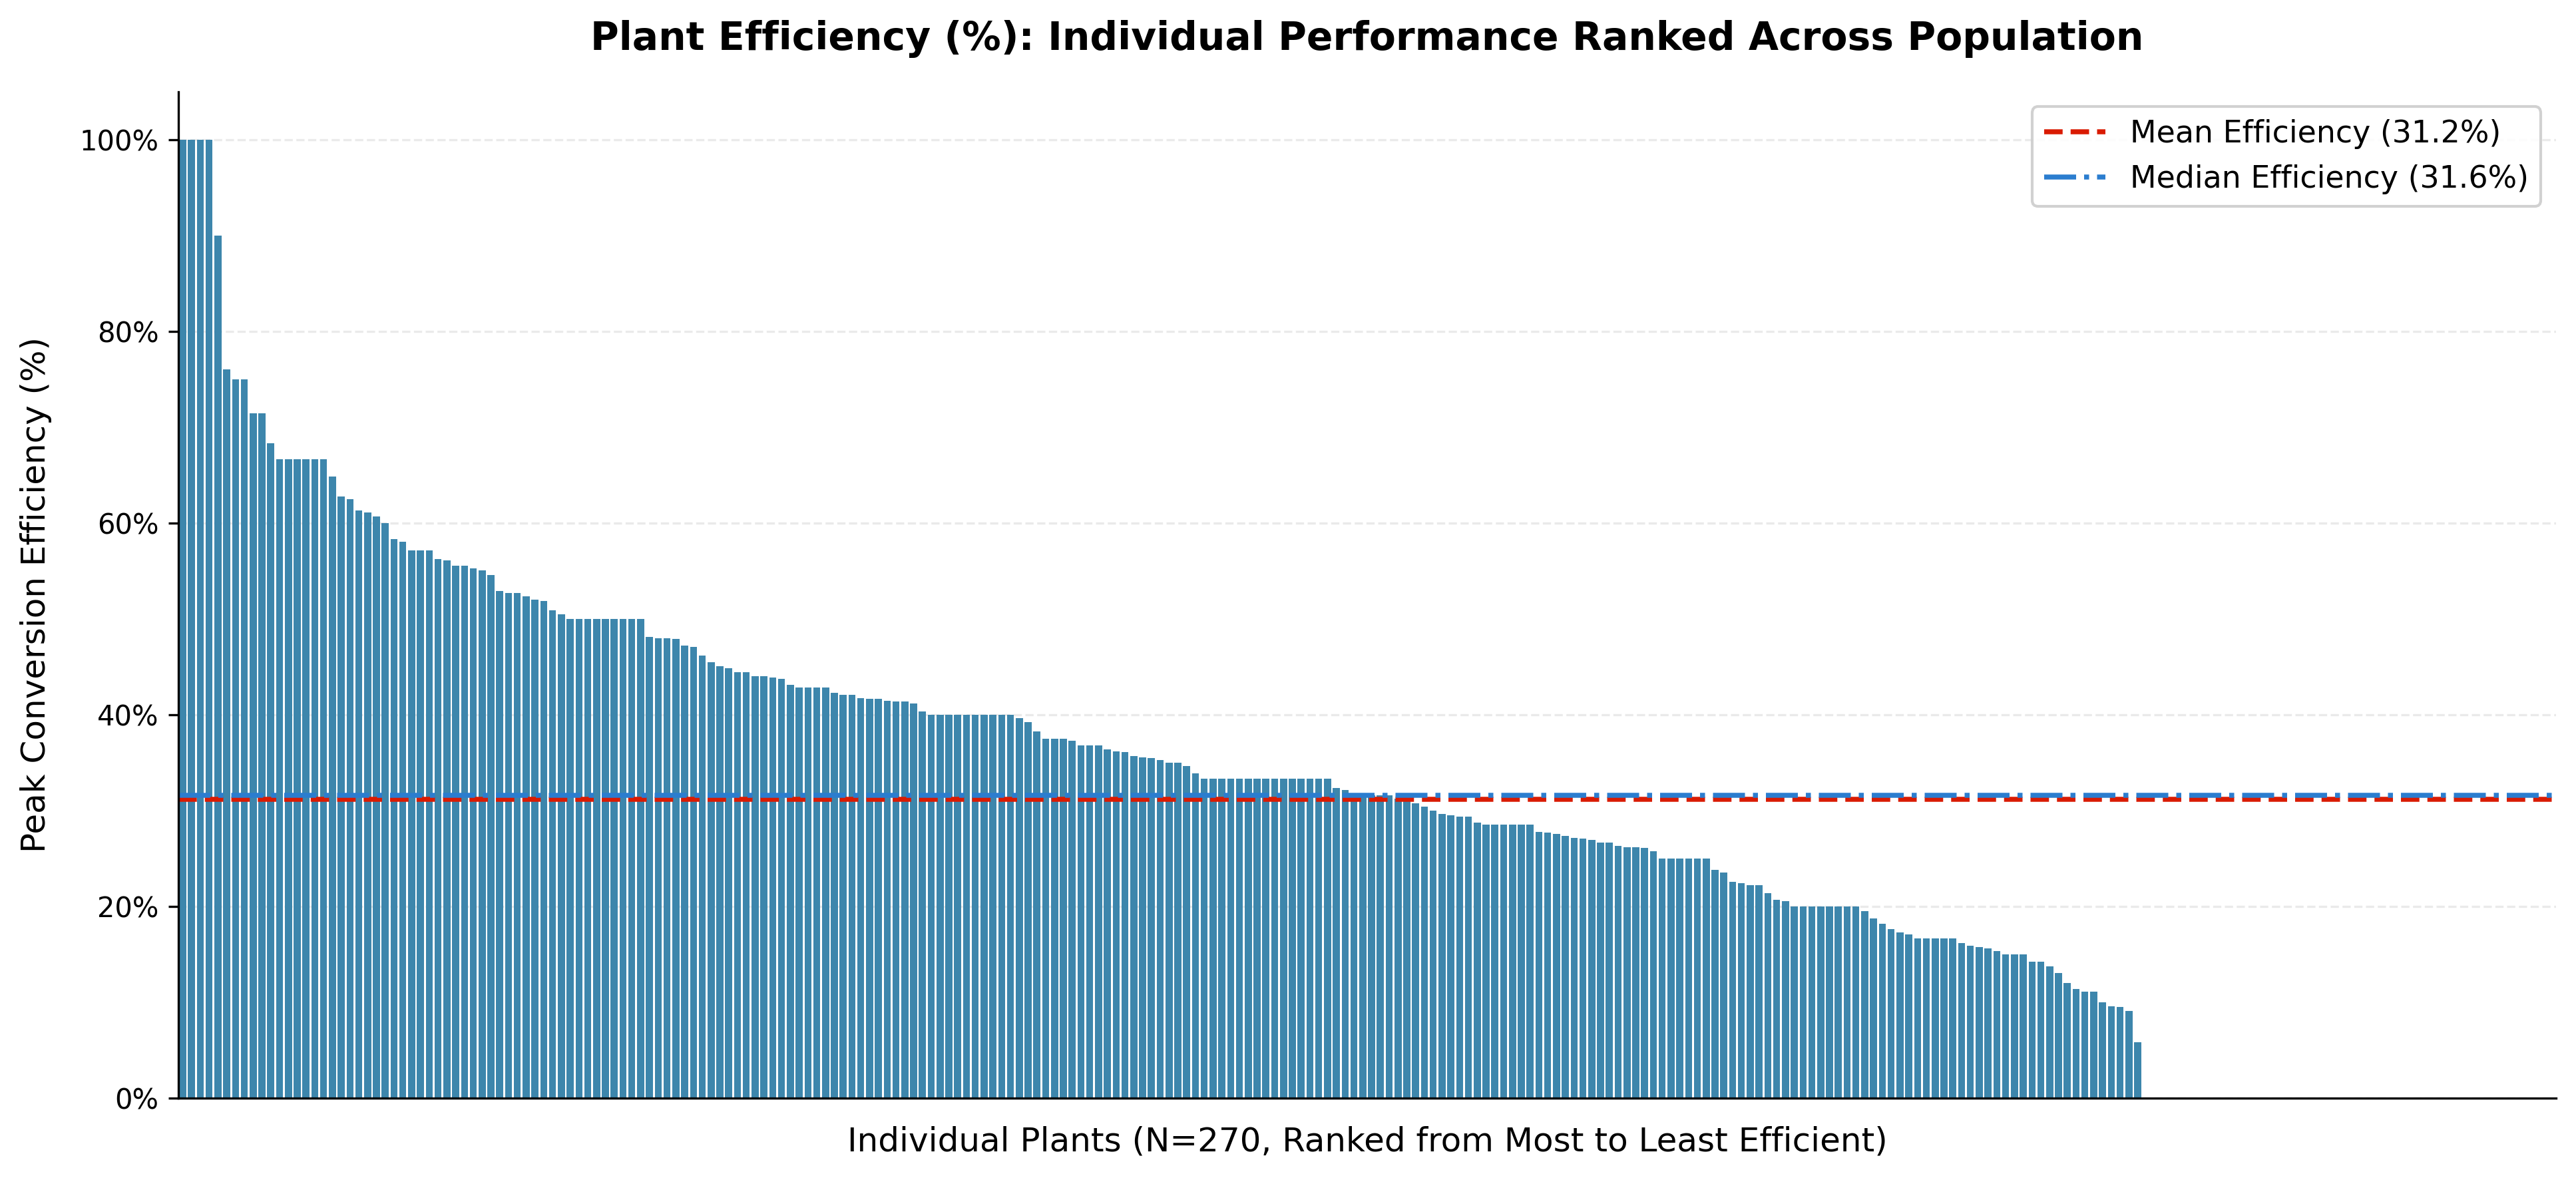

In [ ]:
# Extract total flowers count for each plant
flower_total = df.groupby("PlantID")[["Estim.Flowers.Nr"]].sum()

# Extract maximum count of fruits seen for each plant
seed_max = df.groupby("PlantID")[["Estim.Fruits.Nr"]].max()

# Merge total flowers and max fruits together
plant_max = pd.merge(flower_total, seed_max, on="PlantID")

# Calculate success percentage (RAW DATA)
plant_max["Success_Percentage"] = np.where(
    plant_max["Estim.Flowers.Nr"] > 0,
    (plant_max["Estim.Fruits.Nr"] / plant_max["Estim.Flowers.Nr"]) * 100,
    np.nan,  # Mark division-by-zero as NaN to remove cleanly
)

# --- FILTER DATA: Keep only valid plants with efficiency <= 100% ---
plant_max = plant_max[
    (plant_max["Success_Percentage"].notna())
    & (plant_max["Success_Percentage"] <= 100.0)
].copy()

# Sort from most to least efficient
plant_max = plant_max.sort_values(
    by="Success_Percentage", ascending=False
).reset_index(drop=True)

# Calculate summary metrics on filtered dataset
mean_pct = plant_max["Success_Percentage"].mean()
median_pct = plant_max["Success_Percentage"].median()

# Set up the plot
fig, ax = plt.subplots(figsize=(13, 6), dpi=300)

sns.barplot(
    data=plant_max,
    x=plant_max.index,
    y="Success_Percentage",
    color="#2b8cbe",
    edgecolor="none",
    ax=ax,
)

# --- HORIZONTAL REFERENCE TREND LINES ---
# 1. Mean Line
ax.axhline(
    mean_pct,
    color="#d91b02",
    linestyle="--",
    linewidth=1.8,
    label=f"Mean Efficiency ({mean_pct:.1f}%)",
)

# 2. Median Line
ax.axhline(
    median_pct,
    color="#2b7dcf",
    linestyle="-.",
    linewidth=1.8,
    label=f"Median Efficiency ({median_pct:.1f}%)",
)

# Format Y-axis as percentage
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

# Customization & Labels
ax.set_title(
    "Plant Efficiency (%): Individual Performance Ranked Across Population",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
ax.set_xlabel(
    f"Individual Plants (N={len(plant_max)}, Ranked from Most to Least Efficient)",
    fontsize=12,
    labelpad=10,
)
ax.set_ylabel("Peak Conversion Efficiency (%)", fontsize=12, labelpad=10)

# Clean up axes & legend
ax.set_xticks([])
ax.grid(axis="y", linestyle="--", alpha=0.4, color="#cccccc")
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    fontsize=11, loc="upper right", frameon=True, facecolor="white", framealpha=0.9
)

# Cap Y-lim neatly at 100%
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig("../results/filtered_plants_success_percentage.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Load dataset
csv_path = "../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv"
df = pd.read_csv(csv_path)

# 1. Aggregate total flowers and max fruits per plant
plant_summary = (
    df.groupby("PlantID")
    .agg(
        total_flowers=("Estim.Flowers.Nr", "sum"),
        max_fruits=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

# 2. Compute raw efficiency percentage
plant_summary["Efficiency_Pct"] = np.where(
    plant_summary["total_flowers"] > 0,
    (plant_summary["max_fruits"] / plant_summary["total_flowers"]) * 100,
    np.nan,
)

# 3. Filter for plants > 100% efficiency
over_100_df = plant_summary[
    plant_summary["Efficiency_Pct"] > 100.0
].copy()

# Add a column showing the surplus count (fruits exceeding flowers)
over_100_df["Fruit_Exceeds_Flowers_By"] = (
    over_100_df["max_fruits"] - over_100_df["total_flowers"]
)

# Sort by highest efficiency anomaly
over_100_df = over_100_df.sort_values(
    by="Efficiency_Pct", ascending=False
).reset_index(drop=True)

# 4. Print Summary Report
total_plants = len(plant_summary)
over_100_count = len(over_100_df)
zero_flower_count = plant_summary["total_flowers"].eq(0).sum()
valid_filtered_count = len(
    plant_summary[
        (plant_summary["Efficiency_Pct"].notna())
        & (plant_summary["Efficiency_Pct"] <= 100.0)
    ]
)

print("=== PLANT EFFICIENCY DISCREPANCY AUDIT ===")
print(f"Total Unique Plants in Survey:    {total_plants}")
print(f"Plants with 0 Flowers Recorded:  {zero_flower_count}")
print(f"Plants with Efficiency <= 100%:  {valid_filtered_count}")
print(f"Plants with Efficiency > 100%:   {over_100_count} ({over_100_count / total_plants * 100:.2f}%)")
print("==========================================\n")

print("=== DETAILED LIST OF >100% EFFICIENCY PLANTS ===")
print(
    over_100_df[
        [
            "PlantID",
            "total_flowers",
            "max_fruits",
            "Efficiency_Pct",
            "Fruit_Exceeds_Flowers_By",
        ]
    ].to_string(index=False)
)

=== PLANT EFFICIENCY DISCREPANCY AUDIT ===
Total Unique Plants in Survey:    297
Plants with 0 Flowers Recorded:  10
Plants with Efficiency <= 100%:  270
Plants with Efficiency > 100%:   17 (5.72%)

=== DETAILED LIST OF >100% EFFICIENCY PLANTS ===
PlantID  total_flowers  max_fruits  Efficiency_Pct  Fruit_Exceeds_Flowers_By
 PF0659              1           5      500.000000                         4
 PF0658              1           4      400.000000                         3
 PF0058             25          82      328.000000                        57
 PF0447              4          11      275.000000                         7
 PF0778              3           8      266.666667                         5
 PF0647              3           7      233.333333                         4
 PF0622              5          11      220.000000                         6
 PF0664              1           2      200.000000                         1
 PF0795              1           2      200.000000         

Just looking in to plants with an efficency higher than 100%.

In [ ]:
# 1. Filter for plants with efficiency > 100% (> 1.0)
over_100_df = plant_df[plant_df["efficiency"] > 1.0].copy()

# 2. Calculate the raw difference (Fruit count exceeding flower count)
over_100_df["fruit_exceeds_flowers_by"] = (
    over_100_df["seed_max"] - over_100_df["flower_total"]
)

# 3. Sort by highest efficiency score
over_100_df = over_100_df.sort_values(by="efficiency", ascending=False).reset_index(
    drop=True
)

# 4. Display all 18 plants cleanly
print("=== 18 PLANTS WITH EFFICIENCY > 100% ===")
print(
    over_100_df[
        [
            "PlantID",
            "flower_total",
            "seed_max",
            "fruit_exceeds_flowers_by",
            "efficiency",
        ]
    ].to_string(index=False)
)

# 5. Summary Statistics of the discrepancies
print("\n=== DISCREPANCY SUMMARY ===")
print(f"Mean excess fruit count: {over_100_df['fruit_exceeds_flowers_by'].mean():.2f}")
print(f"Max excess fruit count:  {over_100_df['fruit_exceeds_flowers_by'].max()}")
print(f"Min excess fruit count:  {over_100_df['fruit_exceeds_flowers_by'].min()}")

NameError: name 'plant_df' is not defined

In [ ]:
# 1. Summary Statistics (Crucial for skewed % data)
mean_eff = plant_max["Success_Percentage"].mean()
median_eff = plant_max["Success_Percentage"].median()
iqr_low = plant_max["Success_Percentage"].quantile(0.25)
iqr_high = plant_max["Success_Percentage"].quantile(0.75)
skewness = plant_max["Success_Percentage"].skew()

# 2. One-Sample Test against 0% baseline (Wilcoxon Signed-Rank Test)
# Tests if median conversion efficiency is significantly > 0%
w_stat, p_val_wilc = stats.wilcoxon(plant_max["Success_Percentage"] - 0)

# 3. Trade-off Analysis: Total Flowers vs Efficiency (Spearman Correlation)
rho_eff, p_val_eff = stats.spearmanr(
    plant_max["Estim.Flowers.Nr"], plant_max["Success_Percentage"]
)

# --- TERMINAL OUTPUT ---
print("=== CONVERSION EFFICIENCY STATISTICAL SUMMARY ===")
print(
    f"Mean Efficiency:   {mean_eff:.2f}% | Median: {median_eff:.2f}% (IQR: {iqr_low:.2f}% - {iqr_high:.2f}%)"
)
print(f"Distribution Skewness: {skewness:.2f}")
print(
    f"One-Sample Wilcoxon Test (vs 0%): W = {w_stat:.1f}, p = {p_val_wilc:.4e}"
)
print(
    f"Trade-off (Total Flowers vs Efficiency): rho = {rho_eff:.3f}, p = {p_val_eff:.4e}"
)
print("=================================================\n")

=== CONVERSION EFFICIENCY STATISTICAL SUMMARY ===
Mean Efficiency:   31.24% | Median: 31.58% (IQR: 16.67% - 43.90%)
Distribution Skewness: 0.45
One-Sample Wilcoxon Test (vs 0%): W = 0.0, p = 2.4121e-38
Trade-off (Total Flowers vs Efficiency): rho = 0.248, p = 4.0306e-05



Make a histrogram to visualize distrubution.

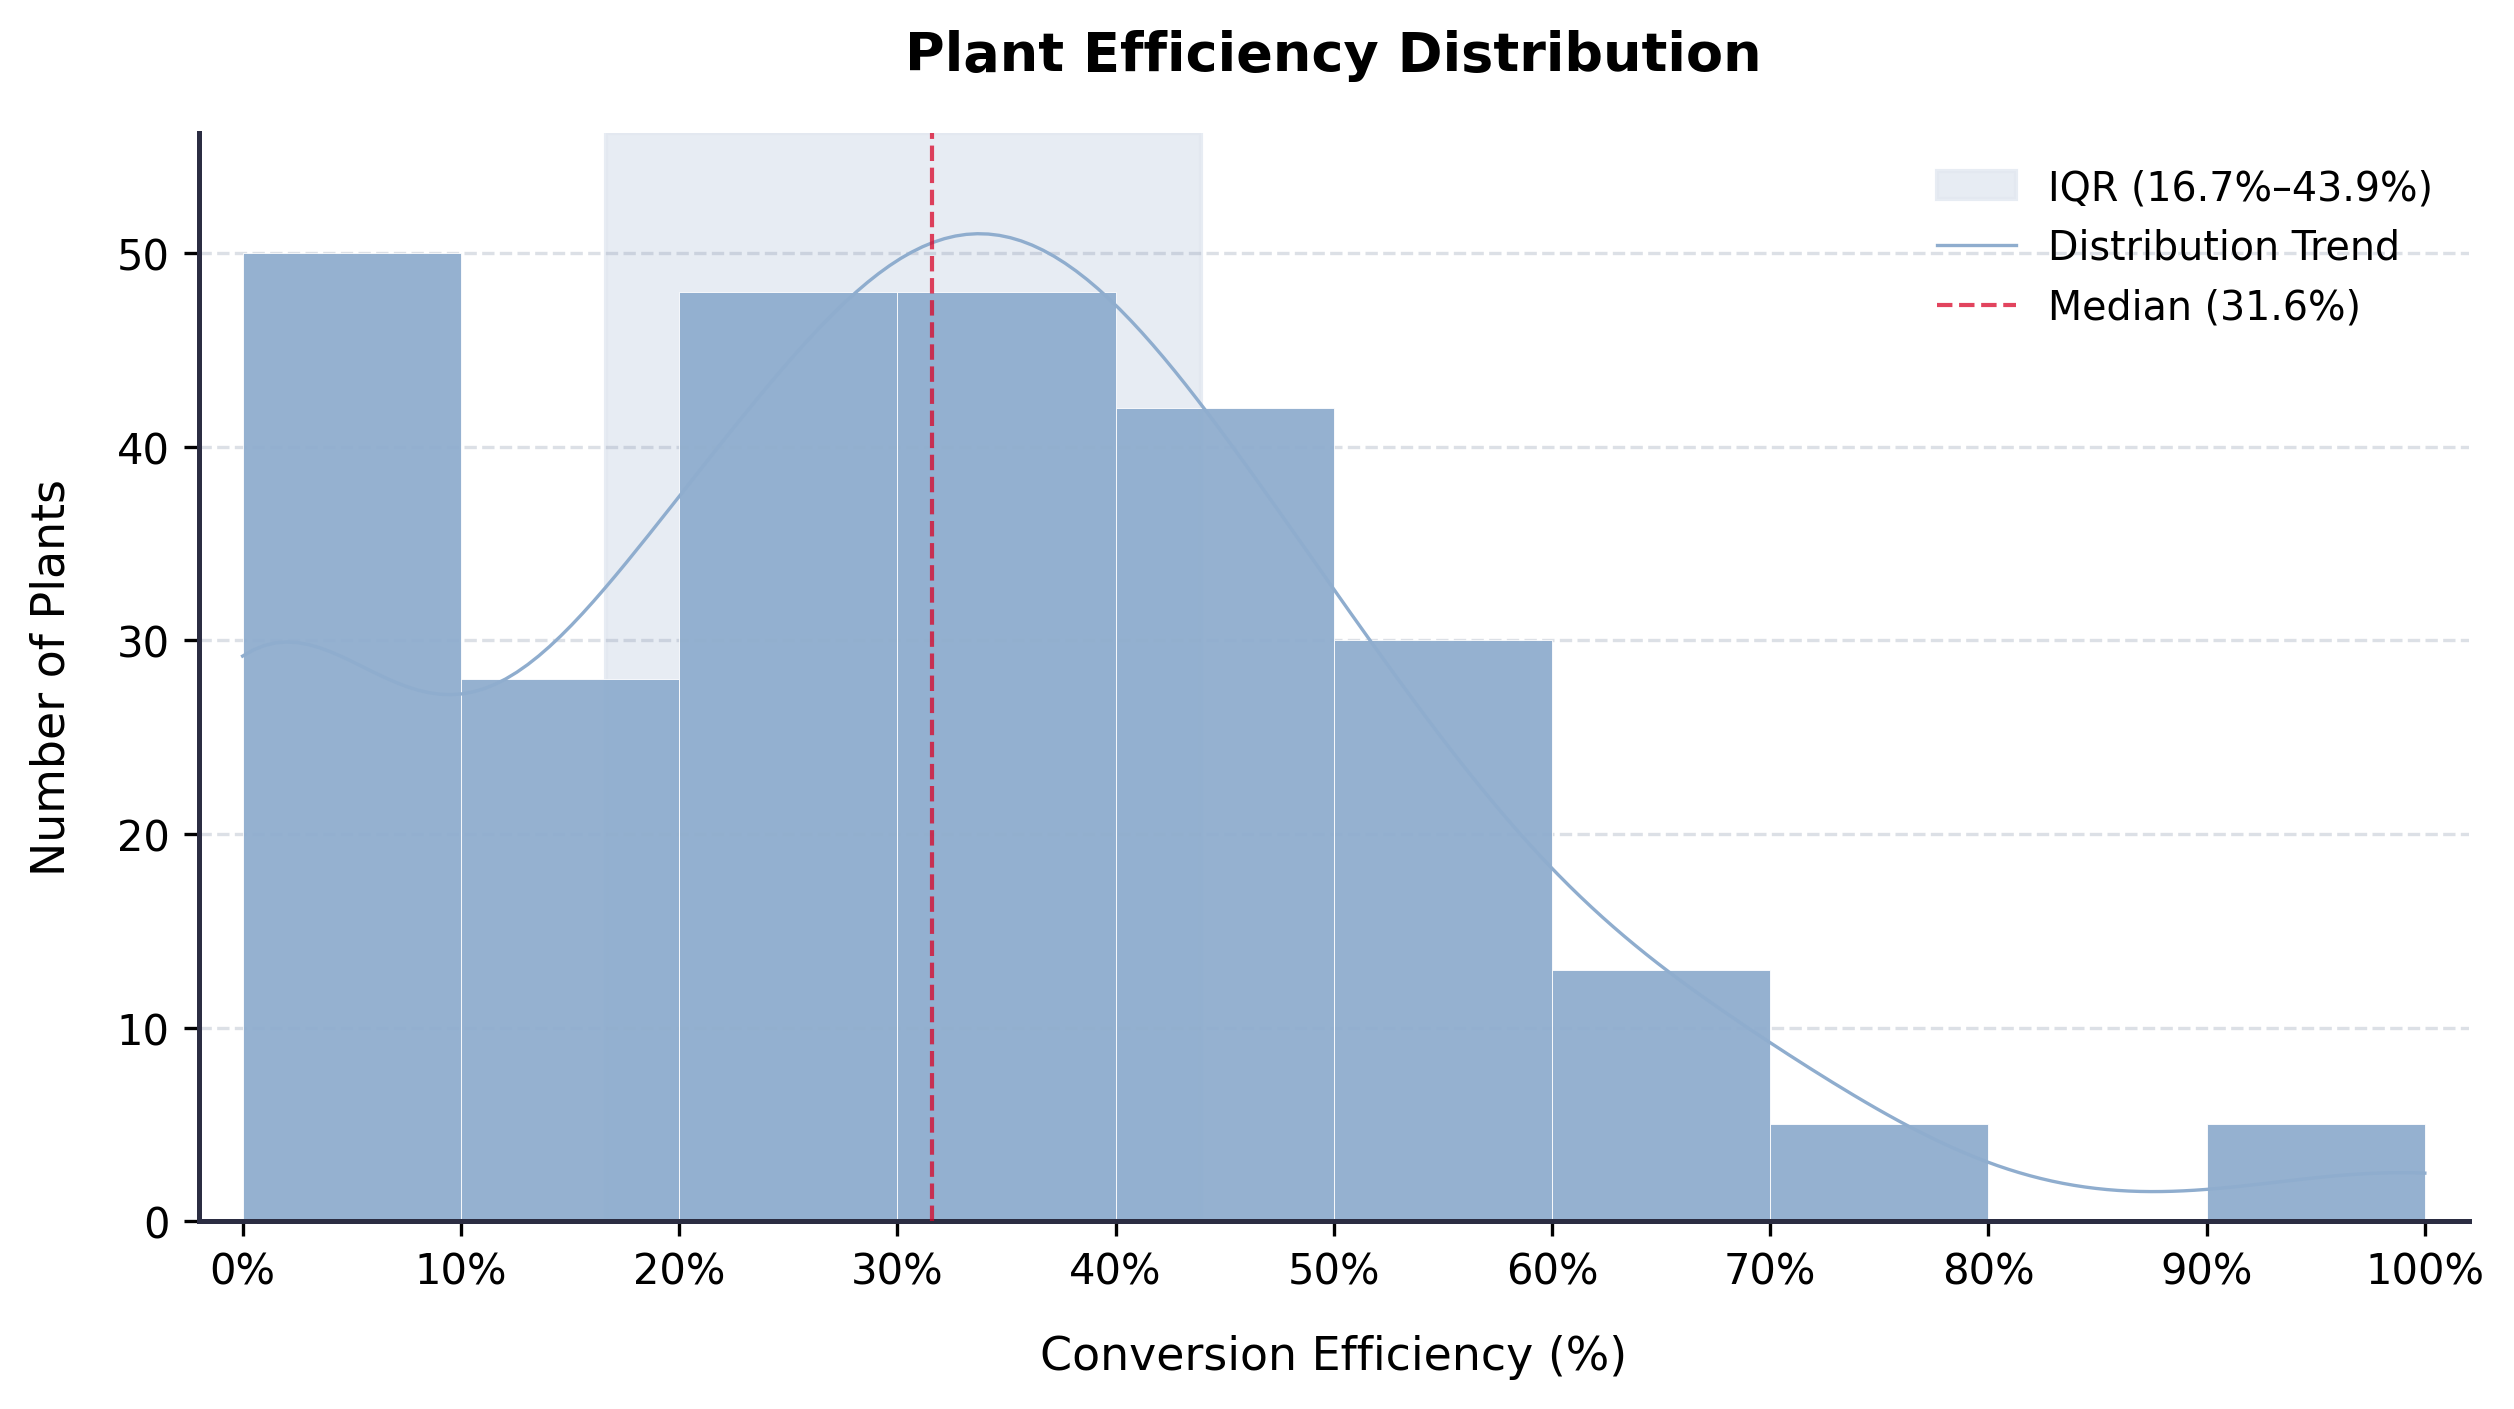

In [ ]:
# --- DATA PREPARATION ---
flower_total = df.groupby("PlantID")[["Estim.Flowers.Nr"]].sum()
seed_max = df.groupby("PlantID")[["Estim.Fruits.Nr"]].max()
plant_max = pd.merge(flower_total, seed_max, on="PlantID")

plant_max["Success_Percentage"] = np.where(
    plant_max["Estim.Flowers.Nr"] > 0,
    (plant_max["Estim.Fruits.Nr"] / plant_max["Estim.Flowers.Nr"]) * 100,
    np.nan,
)

# Filter valid plants (<= 100%)
plant_max = plant_max[
    (plant_max["Success_Percentage"].notna())
    & (plant_max["Success_Percentage"] <= 100.0)
].copy()

median_pct = plant_max["Success_Percentage"].median()
q1_pct = plant_max["Success_Percentage"].quantile(0.25)
q3_pct = plant_max["Success_Percentage"].quantile(0.75)

# --- FIGURE SETUP ---
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)

# 1. Soft IQR Span (Background)
ax.axvspan(
    q1_pct,
    q3_pct,
    color="#E2E8F075",
    alpha=0.8,
    zorder=1,
    label=f"IQR ({q1_pct:.1f}%–{q3_pct:.1f}%)",
)

# 2. Histogram with KDE Distribution Line
sns.histplot(
    data=plant_max,
    x="Success_Percentage",
    bins=10,
    binrange=(0, 100),
    kde=True,
    color="#8FADCE74",
    edgecolor="white",
    linewidth=0.2,
    alpha=0.95,
    line_kws={"linewidth": 0.8, "color":"#DE3F23D5", "label": "Distribution Trend"},
    zorder=2,
    ax=ax,
)

# 3. Clean Median Line
ax.axvline(
    median_pct,
    color="#D90427BE",
    linestyle="--",
    linewidth=1,
    zorder=4,
    label=f"Median ({median_pct:.1f}%)",
)

# --- X-AXIS ENHANCEMENTS ---
ax.set_xticks(np.arange(0, 101, 10))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))

ax.set_xlim(-2, 102)
ax.set_ylim(0, ax.get_ylim()[1] * 1.05)

ax.set_title("Plant Efficiency Distribution", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Conversion Efficiency (%)", fontsize=11, labelpad=10)
ax.set_ylabel("Number of Plants", fontsize=11, labelpad=10)

# Axis lines
ax.spines["left"].set_visible(True)
ax.spines["left"].set_color("#2B2D42")
ax.spines["left"].set_linewidth(1.2)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#2B2D42")
ax.spines["bottom"].set_linewidth(1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Horizontal gridlines
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#8D99AE")
ax.grid(False, axis="x")

# Legend
ax.legend(frameon=False, loc="upper right", fontsize=9.5)

plt.tight_layout()
plt.savefig("../results/informative_efficiency_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

To better visualize the reproductive efficiency of each plant, we plotted total flowers on the x-axis against maximum fruit on the y-axis, highlighting the ratio between flower production and fruit set.

=== UNFILTERED ANALYSIS (N = 297) ===
Regression: Fruits = 0.330 * Flowers + 0.904
R²: 0.749 | p: 2.0187e-90
Spearman rho: 0.805 | p: 5.6278e-69



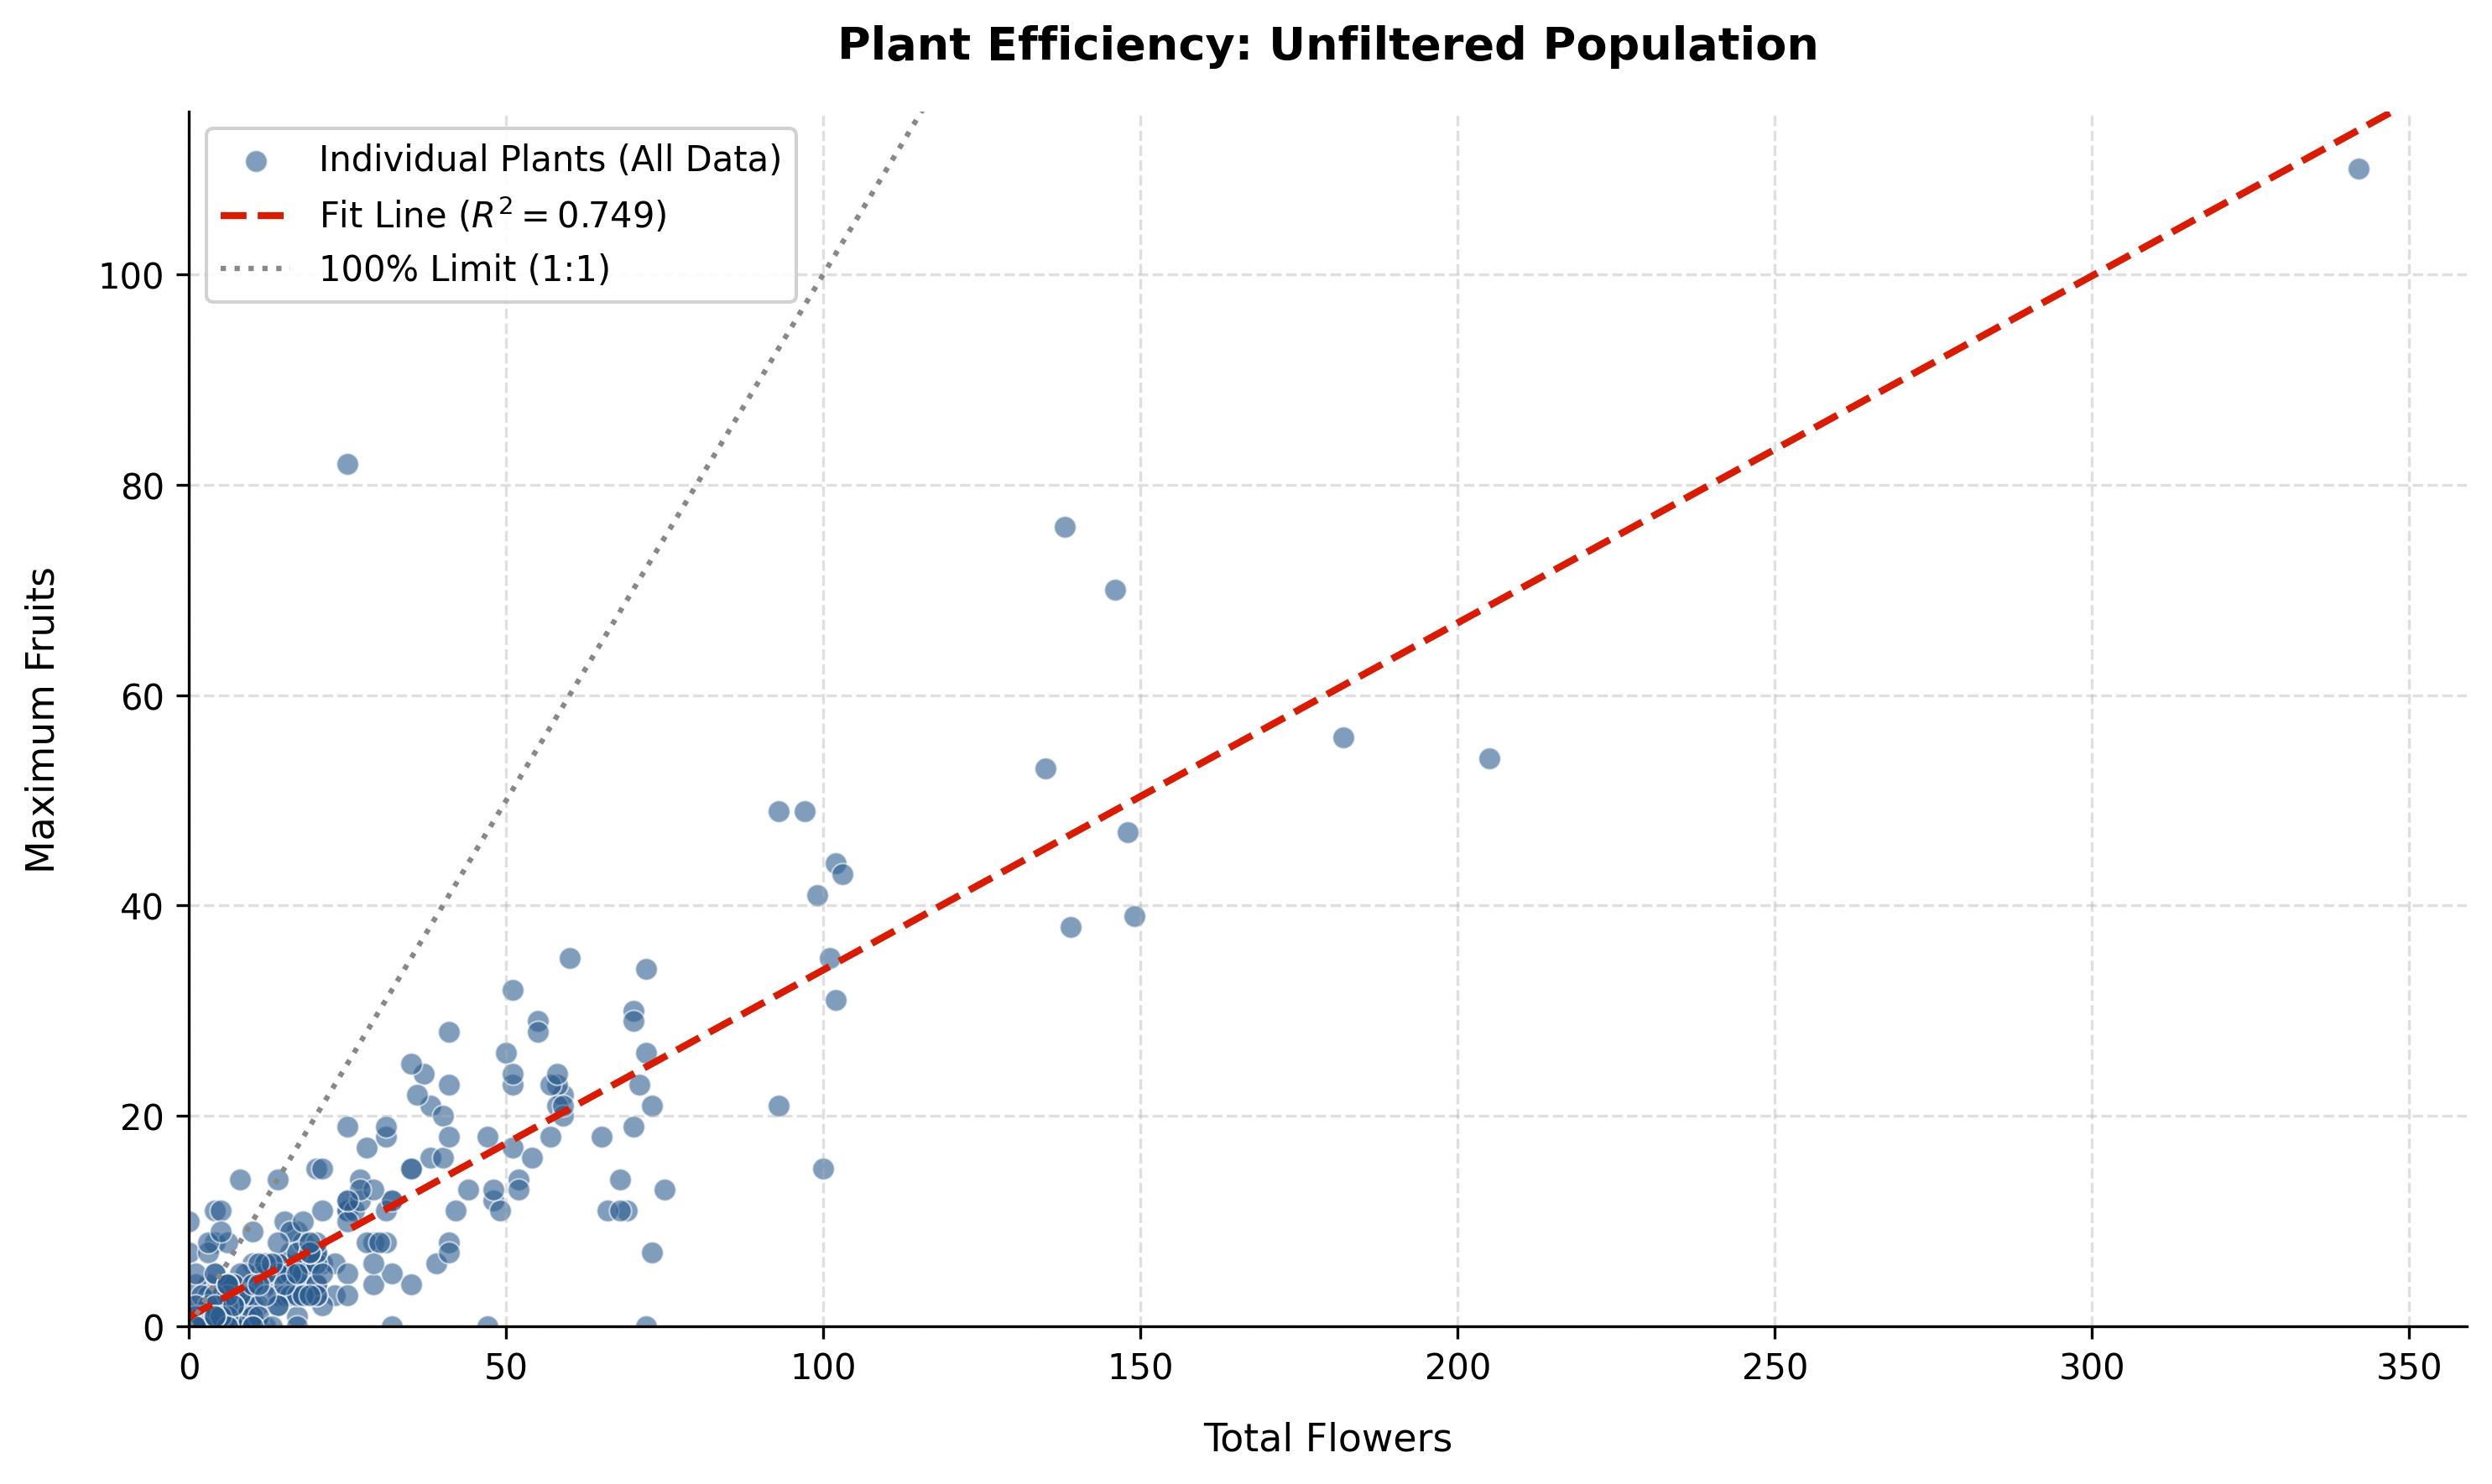

=== FILTERED ANALYSIS (N = 223) ===
Regression: Fruits = 0.333 * Flowers + 0.811
R²: 0.840 | p: 6.8023e-90
Spearman rho: 0.890 | p: 2.6724e-77



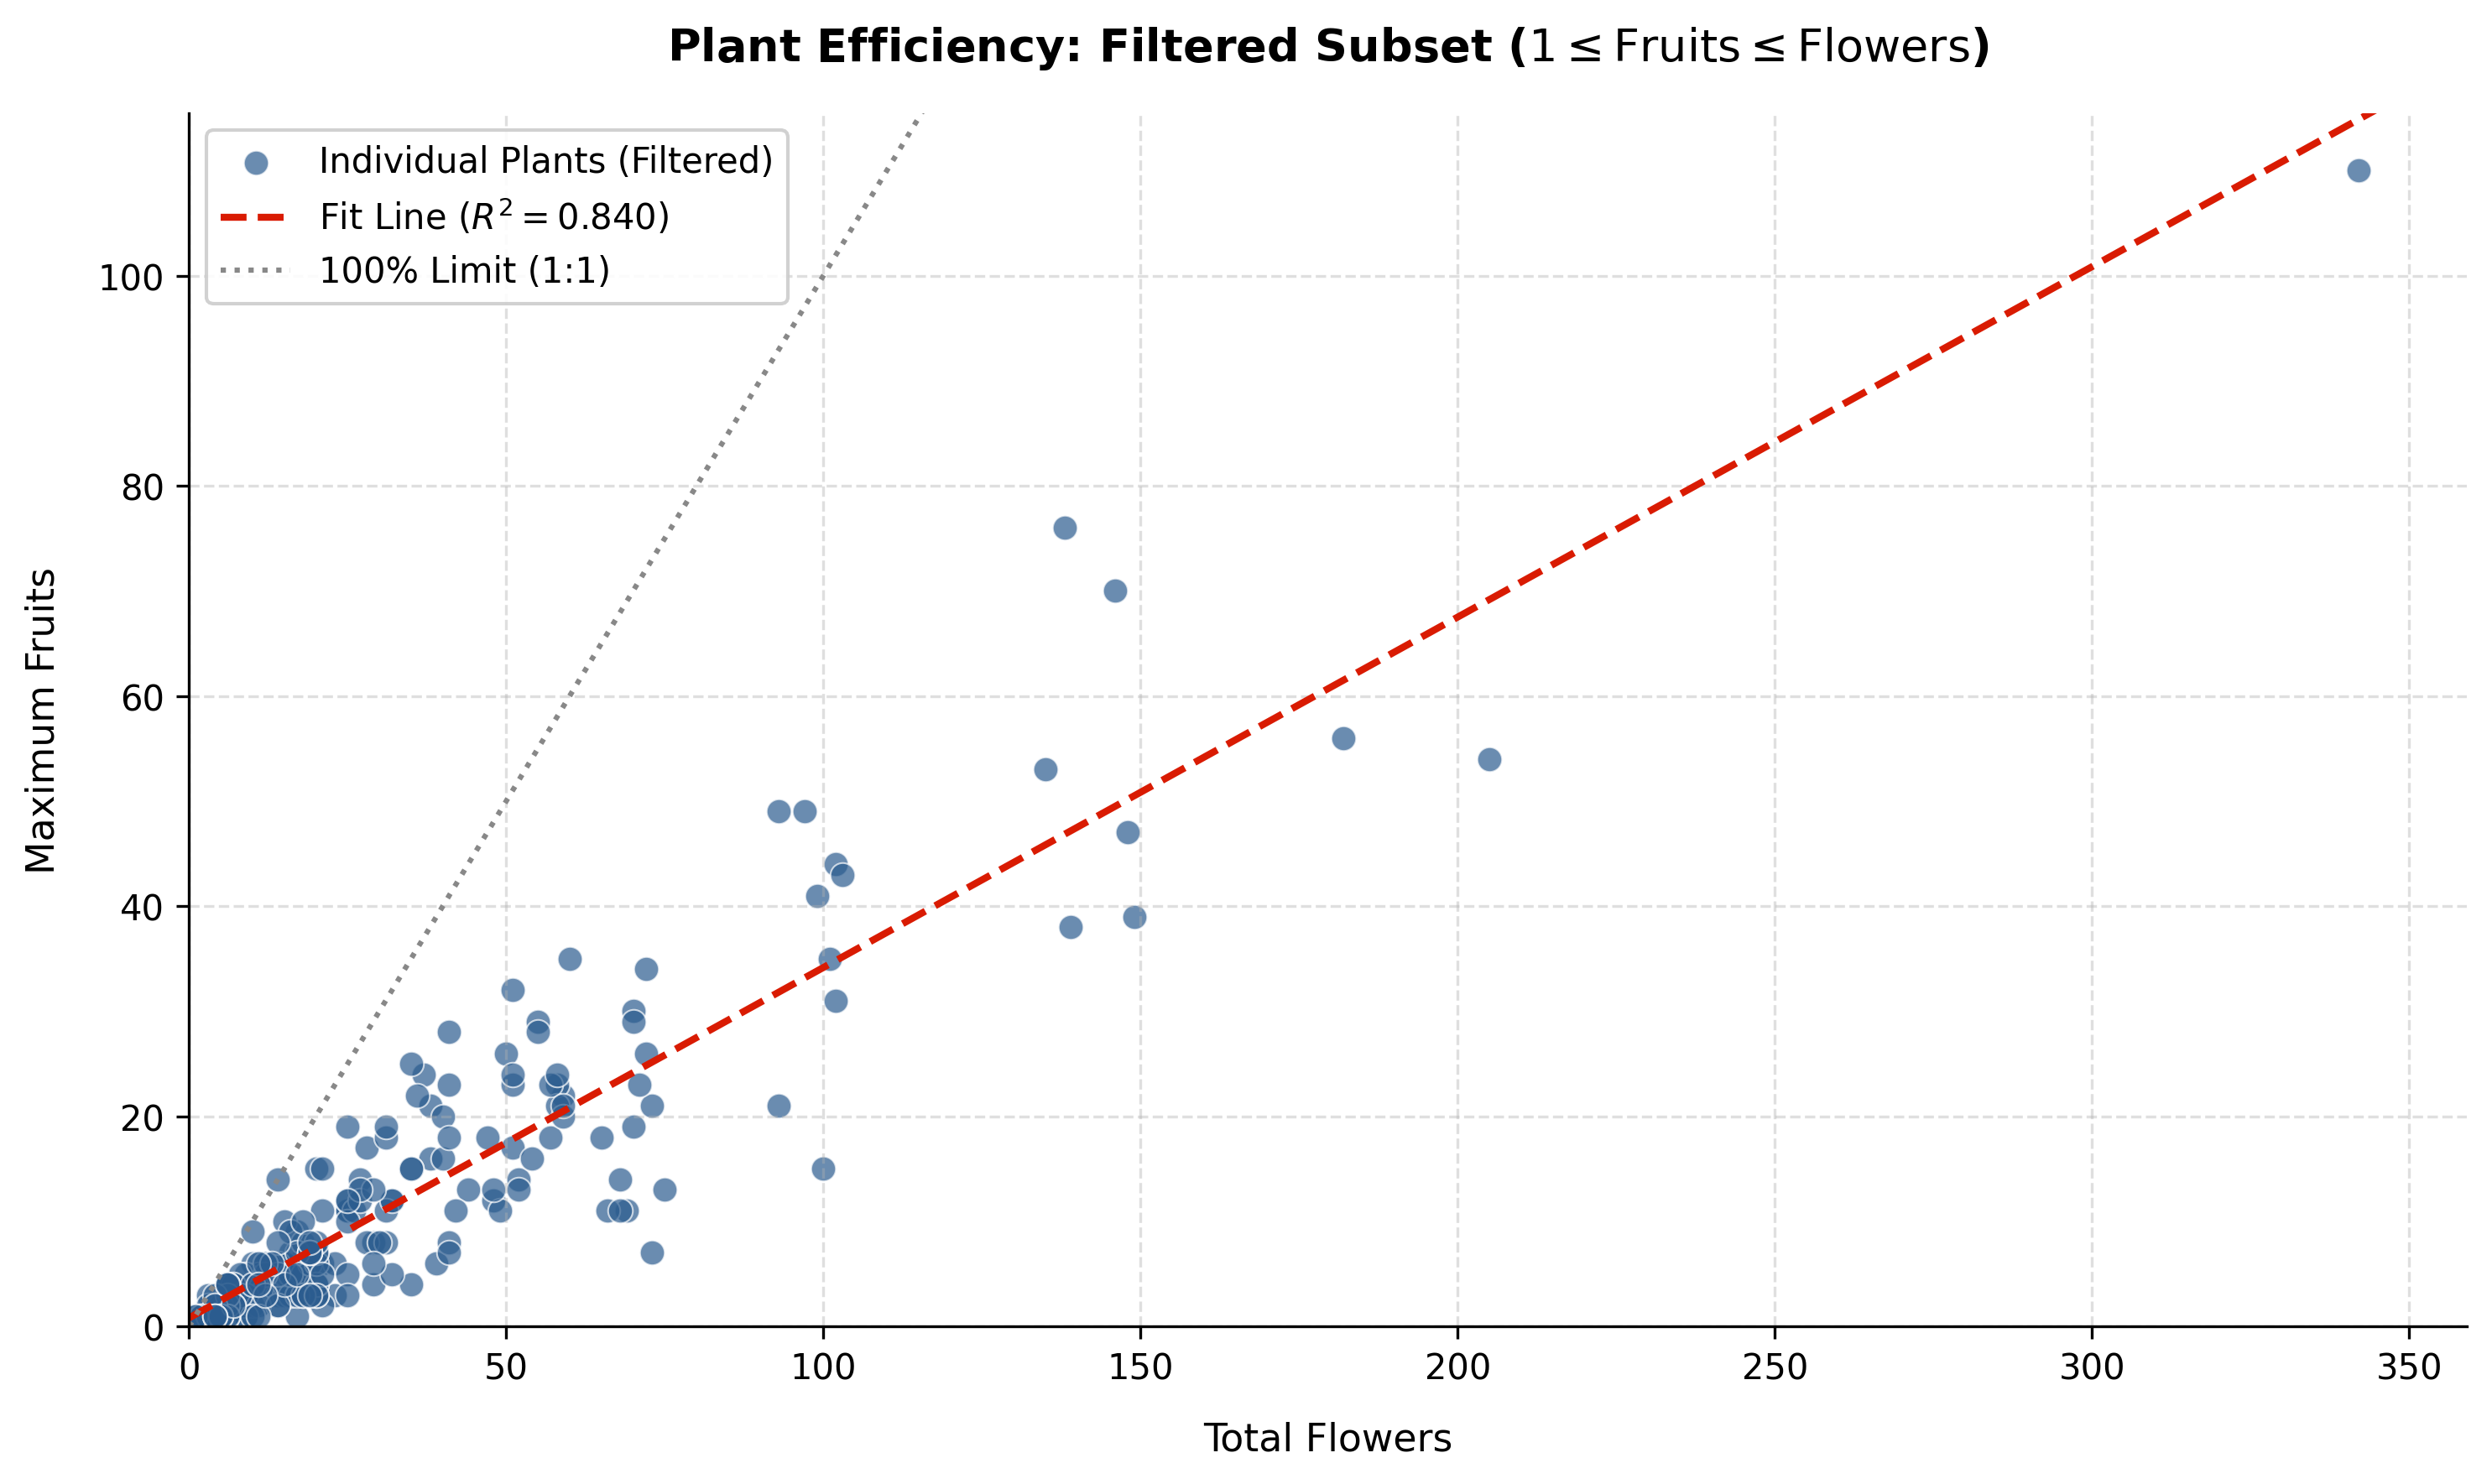

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# ==========================================
# 0. LOAD DATAFILE
# ==========================================
df = pd.read_csv("../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv")

# ==========================================
# 1. DATA PREPARATION & GLOBAL AXIS BOUNDS
# ==========================================
# Full aggregated dataset (Plot 1 base)
full_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

# Filtered dataset: Flowers > 0, Fruits >= 1, and Fruits <= Flowers (Plot 2 base)
filtered_df = full_df[
    (full_df["flower_total"] > 0)
    & (full_df["seed_max"] >= 1)
    & (full_df["seed_max"] <= full_df["flower_total"])
].copy()

# Calculate global maximums to fix identical X and Y scales on both plots
max_x = max(full_df["flower_total"].max(), filtered_df["flower_total"].max()) * 1.05
max_y = max(full_df["seed_max"].max(), filtered_df["seed_max"].max()) * 1.05

# Shared figure size and styling setup
FIG_SIZE = (10, 6)
DPI = 300

# ==========================================
# 2. PLOT 1: UNFILTERED (RAW DATA)
# ==========================================
flowers_raw = full_df["flower_total"].dropna()
fruits_raw = full_df["seed_max"].dropna()

slope_raw, intercept_raw, r_val_raw, p_val_raw, _ = stats.linregress(
    flowers_raw, fruits_raw
)
r2_raw = r_val_raw**2
rho_raw, p_spearman_raw = stats.spearmanr(flowers_raw, fruits_raw)

print(f"=== UNFILTERED ANALYSIS (N = {len(full_df)}) ===")
print(f"Regression: Fruits = {slope_raw:.3f} * Flowers + {intercept_raw:.3f}")
print(f"R²: {r2_raw:.3f} | p: {p_val_raw:.4e}")
print(f"Spearman rho: {rho_raw:.3f} | p: {p_spearman_raw:.4e}\n")

fig1, ax1 = plt.subplots(figsize=FIG_SIZE, dpi=DPI)

ax1.scatter(
    flowers_raw,
    fruits_raw,
    alpha=0.6,
    color="#2b5c8f",
    s=40,
    edgecolor="white",
    linewidth=0.5,
    label="Individual Plants (All Data)",
)

x_line_raw = np.array([0, max_x])
ax1.plot(
    x_line_raw,
    intercept_raw + slope_raw * x_line_raw,
    color="#d91b02",
    linestyle="--",
    linewidth=2,
    label=f"Fit Line ($R^2 = {r2_raw:.3f}$)",
)

# 1:1 Biological Limit Line
ax1.plot([0, max_x], [0, max_x], color="#888888", linestyle=":", label="100% Limit (1:1)")

ax1.set_title("Plant Efficiency: Unfiltered Population", fontsize=13, fontweight="bold", pad=15)
ax1.set_xlabel("Total Flowers", fontsize=11, labelpad=10)
ax1.set_ylabel("Maximum Fruits", fontsize=11, labelpad=10)

# LOCK MATCHING AXIS LIMITS
ax1.set_xlim(0, max_x)
ax1.set_ylim(0, max_y)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.savefig("../results/raw_flower_vs_fruit_scatter.png", dpi=DPI)
plt.show()

# ==========================================
# 3. PLOT 2: FILTERED DATA (1 <= Fruits <= Flowers)
# ==========================================
flowers_filt = filtered_df["flower_total"]
fruits_filt = filtered_df["seed_max"]

slope_filt, intercept_filt, r_val_filt, p_val_filt, _ = stats.linregress(
    flowers_filt, fruits_filt
)
r2_filt = r_val_filt**2
rho_filt, p_spearman_filt = stats.spearmanr(flowers_filt, fruits_filt)

print(f"=== FILTERED ANALYSIS (N = {len(filtered_df)}) ===")
print(f"Regression: Fruits = {slope_filt:.3f} * Flowers + {intercept_filt:.3f}")
print(f"R²: {r2_filt:.3f} | p: {p_val_filt:.4e}")
print(f"Spearman rho: {rho_filt:.3f} | p: {p_spearman_filt:.4e}\n")

fig2, ax2 = plt.subplots(figsize=FIG_SIZE, dpi=DPI)

ax2.scatter(
    flowers_filt,
    fruits_filt,
    alpha=0.7,
    color="#2b5c8f",
    s=50,
    edgecolor="white",
    linewidth=0.5,
    label="Individual Plants (Filtered)",
)

x_line_filt = np.array([0, max_x])
ax2.plot(
    x_line_filt,
    intercept_filt + slope_filt * x_line_filt,
    color="#d91b02",
    linestyle="--",
    linewidth=2,
    label=f"Fit Line ($R^2 = {r2_filt:.3f}$)",
)

# 1:1 Biological Limit Line
ax2.plot([0, max_x], [0, max_x], color="#888888", linestyle=":", label="100% Limit (1:1)")

ax2.set_title(
    r"Plant Efficiency: Filtered Subset ($1 \leq \mathrm{Fruits} \leq \mathrm{Flowers}$)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax2.set_xlabel("Total Flowers", fontsize=11, labelpad=10)
ax2.set_ylabel("Maximum Fruits", fontsize=11, labelpad=10)

# LOCK MATCHING AXIS LIMITS
ax2.set_xlim(0, max_x)
ax2.set_ylim(0, max_y)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.savefig("../results/filtered_flower_vs_fruit_scatter.png", dpi=DPI)
plt.show()

=== UNFILTERED LOG-TRANSFORMED ANALYSIS (N = 297) ===
Log Regression: log(Fruits+1) = 0.760 * log(Flowers+1) + -0.295
R²: 0.621 | p: 4.5192e-64
Spearman rho: 0.805 | p: 5.6278e-69



<>:82: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:142: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:82: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:142: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/var/folders/7b/tyzwtcv13pz7k6db8rvxss_r0000gn/T/ipykernel_73018/3129985885.py:82: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ax1.set_title("Plant Efficiency: Unfiltered Population ($\log(x+1)$ Scale)", fontsize=13, fontweight="bold", pad=15)
/var/folders/7b/tyzwtcv13pz7k6db8

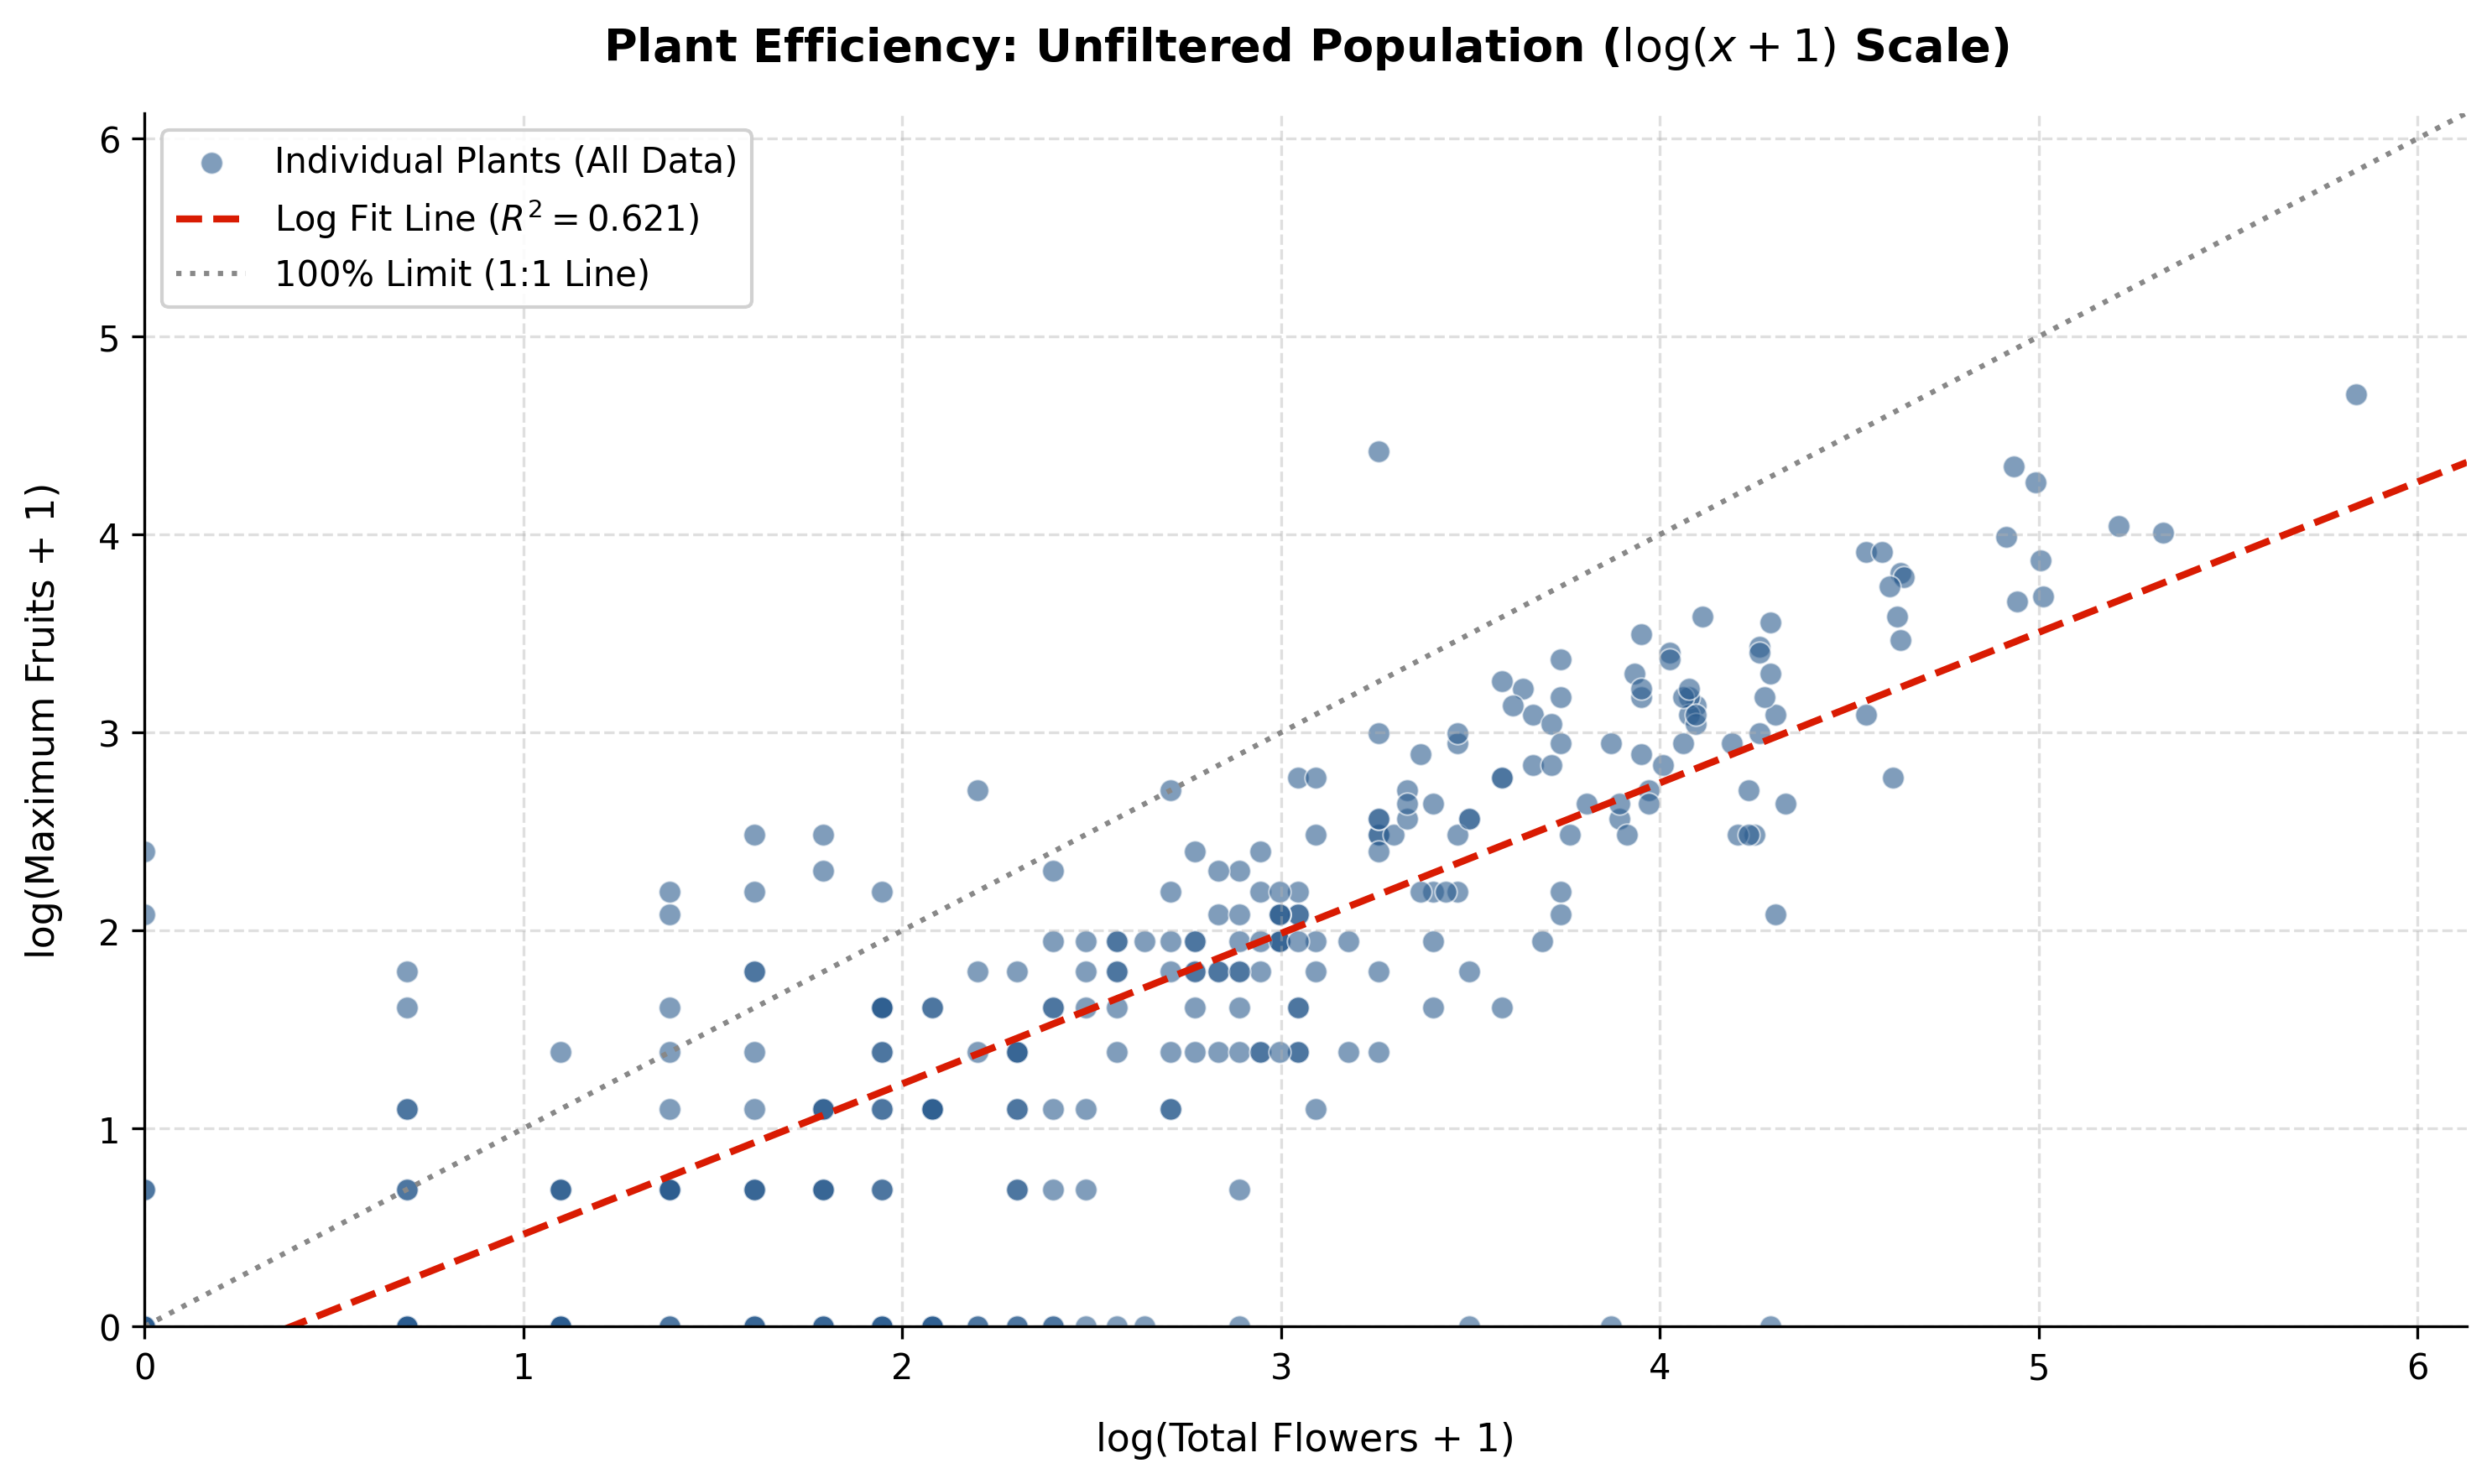

=== FILTERED LOG-TRANSFORMED ANALYSIS (N = 223) ===
Log Regression: log(Fruits+1) = 0.859 * log(Flowers+1) + -0.523
R²: 0.803 | p: 5.2092e-80
Spearman rho: 0.890 | p: 2.6724e-77



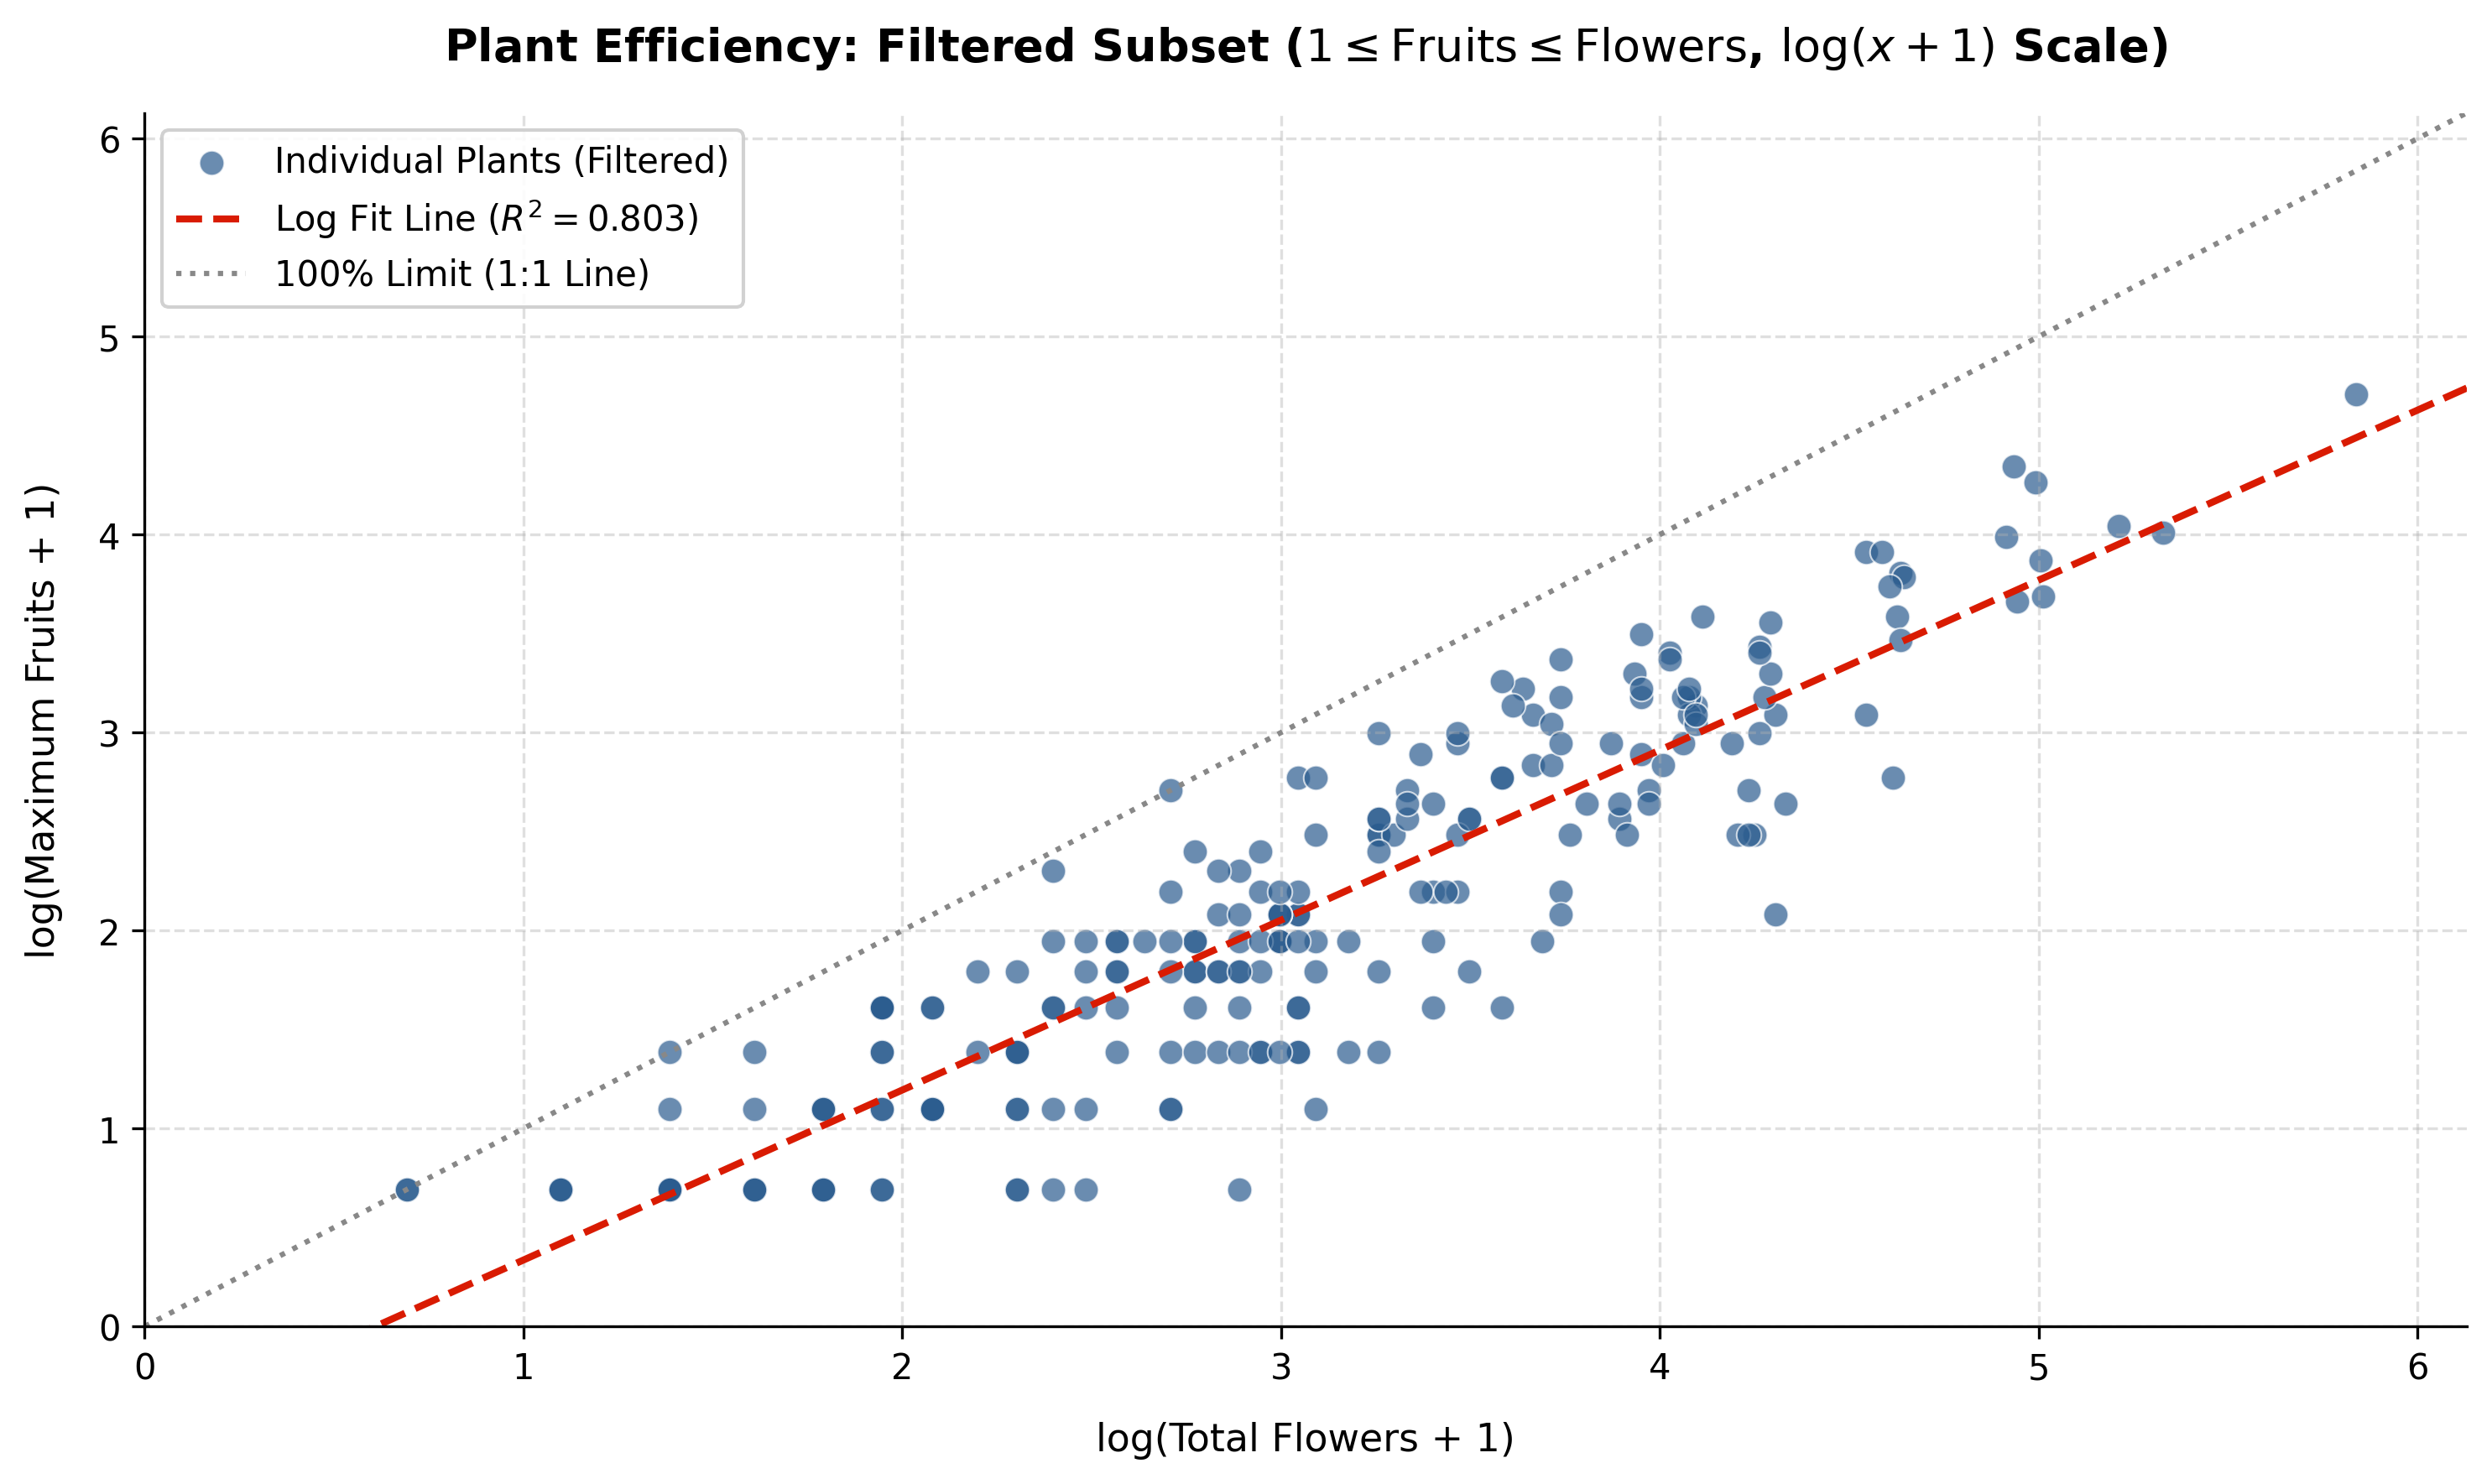

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# ==========================================
# 0. LOAD DATAFILE
# ==========================================
df = pd.read_csv("../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv")

# ==========================================
# 1. DATA PREPARATION & LOG(X + 1) TRANSFORM
# ==========================================
# Full aggregated dataset (Plot 1 base)
full_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

# Apply log1p transformation: log(x + 1)
full_df["log_flowers"] = np.log1p(full_df["flower_total"])
full_df["log_fruits"] = np.log1p(full_df["seed_max"])

# Filtered dataset: Flowers > 0, Fruits >= 1, and Fruits <= Flowers (Plot 2 base)
filtered_df = full_df[
    (full_df["flower_total"] > 0)
    & (full_df["seed_max"] >= 1)
    & (full_df["seed_max"] <= full_df["flower_total"])
].copy()

# Calculate global maximums on log scale for shared axis limits
max_log_x = max(full_df["log_flowers"].max(), filtered_df["log_flowers"].max()) * 1.05
max_log_y = max(full_df["log_fruits"].max(), filtered_df["log_fruits"].max()) * 1.05
max_shared_lim = max(max_log_x, max_log_y)  # Keeps identical X and Y scale boundaries

FIG_SIZE = (10, 6)
DPI = 300

# ==========================================
# 2. PLOT 1: UNFILTERED (LOG SCALE)
# ==========================================
flowers_log_raw = full_df["log_flowers"].dropna()
fruits_log_raw = full_df["log_fruits"].dropna()

slope_raw, intercept_raw, r_val_raw, p_val_raw, _ = stats.linregress(
    flowers_log_raw, fruits_log_raw
)
r2_raw = r_val_raw**2
rho_raw, p_spearman_raw = stats.spearmanr(flowers_log_raw, fruits_log_raw)

print(f"=== UNFILTERED LOG-TRANSFORMED ANALYSIS (N = {len(full_df)}) ===")
print(f"Log Regression: log(Fruits+1) = {slope_raw:.3f} * log(Flowers+1) + {intercept_raw:.3f}")
print(f"R²: {r2_raw:.3f} | p: {p_val_raw:.4e}")
print(f"Spearman rho: {rho_raw:.3f} | p: {p_spearman_raw:.4e}\n")

fig1, ax1 = plt.subplots(figsize=FIG_SIZE, dpi=DPI)

ax1.scatter(
    flowers_log_raw,
    fruits_log_raw,
    alpha=0.6,
    color="#2b5c8f",
    s=40,
    edgecolor="white",
    linewidth=0.5,
    label="Individual Plants (All Data)",
)

x_line_raw = np.array([0, max_shared_lim])
ax1.plot(
    x_line_raw,
    intercept_raw + slope_raw * x_line_raw,
    color="#d91b02",
    linestyle="--",
    linewidth=2,
    label=f"Log Fit Line ($R^2 = {r2_raw:.3f}$)",
)

# 1:1 Biological Limit Line: log(Fruits+1) == log(Flowers+1)
ax1.plot([0, max_shared_lim], [0, max_shared_lim], color="#888888", linestyle=":", label="100% Limit (1:1 Line)")

ax1.set_title(r"Plant Efficiency: Unfiltered Population ($\log(x+1)$ Scale)", fontsize=13, fontweight="bold", pad=15)
ax1.set_xlabel(r"log(Total Flowers + 1)", fontsize=11, labelpad=10)
ax1.set_ylabel(r"log(Maximum Fruits + 1)", fontsize=11, labelpad=10)

ax1.set_xlim(0, max_shared_lim)
ax1.set_ylim(0, max_shared_lim)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.savefig("../results/raw_log1p_flower_vs_fruit.png", dpi=DPI)
plt.show()

# ==========================================
# 3. PLOT 2: FILTERED DATA (LOG SCALE)
# ==========================================
flowers_log_filt = filtered_df["log_flowers"]
fruits_log_filt = filtered_df["log_fruits"]

slope_filt, intercept_filt, r_val_filt, p_val_filt, _ = stats.linregress(
    flowers_log_filt, fruits_log_filt
)
r2_filt = r_val_filt**2
rho_filt, p_spearman_filt = stats.spearmanr(flowers_log_filt, fruits_log_filt)

print(f"=== FILTERED LOG-TRANSFORMED ANALYSIS (N = {len(filtered_df)}) ===")
print(f"Log Regression: log(Fruits+1) = {slope_filt:.3f} * log(Flowers+1) + {intercept_filt:.3f}")
print(f"R²: {r2_filt:.3f} | p: {p_val_filt:.4e}")
print(f"Spearman rho: {rho_filt:.3f} | p: {p_spearman_filt:.4e}\n")

fig2, ax2 = plt.subplots(figsize=FIG_SIZE, dpi=DPI)

ax2.scatter(
    flowers_log_filt,
    fruits_log_filt,
    alpha=0.7,
    color="#2b5c8f",
    s=50,
    edgecolor="white",
    linewidth=0.5,
    label="Individual Plants (Filtered)",
)

x_line_filt = np.array([0, max_shared_lim])
ax2.plot(
    x_line_filt,
    intercept_filt + slope_filt * x_line_filt,
    color="#d91b02",
    linestyle="--",
    linewidth=2,
    label=f"Log Fit Line ($R^2 = {r2_filt:.3f}$)",
)

# 1:1 Biological Limit Line
ax2.plot([0, max_shared_lim], [0, max_shared_lim], color="#888888", linestyle=":", label="100% Limit (1:1 Line)")

ax2.set_title(
    r"Plant Efficiency: Filtered Subset ($1 \leq \mathrm{Fruits} \leq \mathrm{Flowers}$, $\log(x+1)$ Scale)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax2.set_xlabel(r"log(Total Flowers + 1)", fontsize=11, labelpad=10)
ax2.set_ylabel(r"log(Maximum Fruits + 1)", fontsize=11, labelpad=10)

ax2.set_xlim(0, max_shared_lim)
ax2.set_ylim(0, max_shared_lim)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.savefig("../results/filtered_log1p_flower_vs_fruit.png", dpi=DPI)
plt.show()

making abinomial model?

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Aggregate data per plant
efficiency_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

# 2. FILTER: Plants with flowers > 0, AT LEAST 1 fruit, and valid sampling (Fruits <= Flowers)
df_active = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["seed_max"] >= 1)
    & (efficiency_df["seed_max"] <= efficiency_df["flower_total"])
].copy()

# 3. Define failure counts for the Binomial trial
df_active["failures"] = df_active["flower_total"] - df_active["seed_max"]

# 4. Fit Binomial GLM (logit link by default)
# Tests if total flower count influences the probability of an individual flower forming fruit
glm_binom = smf.glm(
    formula="Q('seed_max') + Q('failures') ~ flower_total",
    data=df_active,
    family=sm.families.Binomial(),
).fit()

print(glm_binom.summary())

# Extract Odds Ratio for total_flowers
odds_ratio = np.exp(glm_binom.params["flower_total"])
print(f"\nOdds Ratio per additional flower: {odds_ratio:.4f}")

                         Generalized Linear Model Regression Results                          
Dep. Variable:     ["Q('seed_max')", "Q('failures')"]   No. Observations:                  223
Model:                                            GLM   Df Residuals:                      221
Model Family:                                Binomial   Df Model:                            1
Link Function:                                  Logit   Scale:                          1.0000
Method:                                          IRLS   Log-Likelihood:                -705.27
Date:                                Wed, 26 Aug 2026   Deviance:                       676.70
Time:                                        13:10:54   Pearson chi2:                     646.
No. Iterations:                                     4   Pseudo R-squ. (CS):            0.03101
Covariance Type:                            nonrobust                                         
                   coef    std err          z     

=== BINOMIAL GLM STATISTICAL SUMMARY ===
Sample Size (N):               223
Intercept (beta_0):            -0.5185
Slope Coefficient (beta_1):    -0.0009
Odds Ratio (per flower):       0.9991
p-value (flower_total):        8.0002e-03
Dispersion Parameter (phi):    2.932
McFadden's Pseudo R-squared:   0.0104



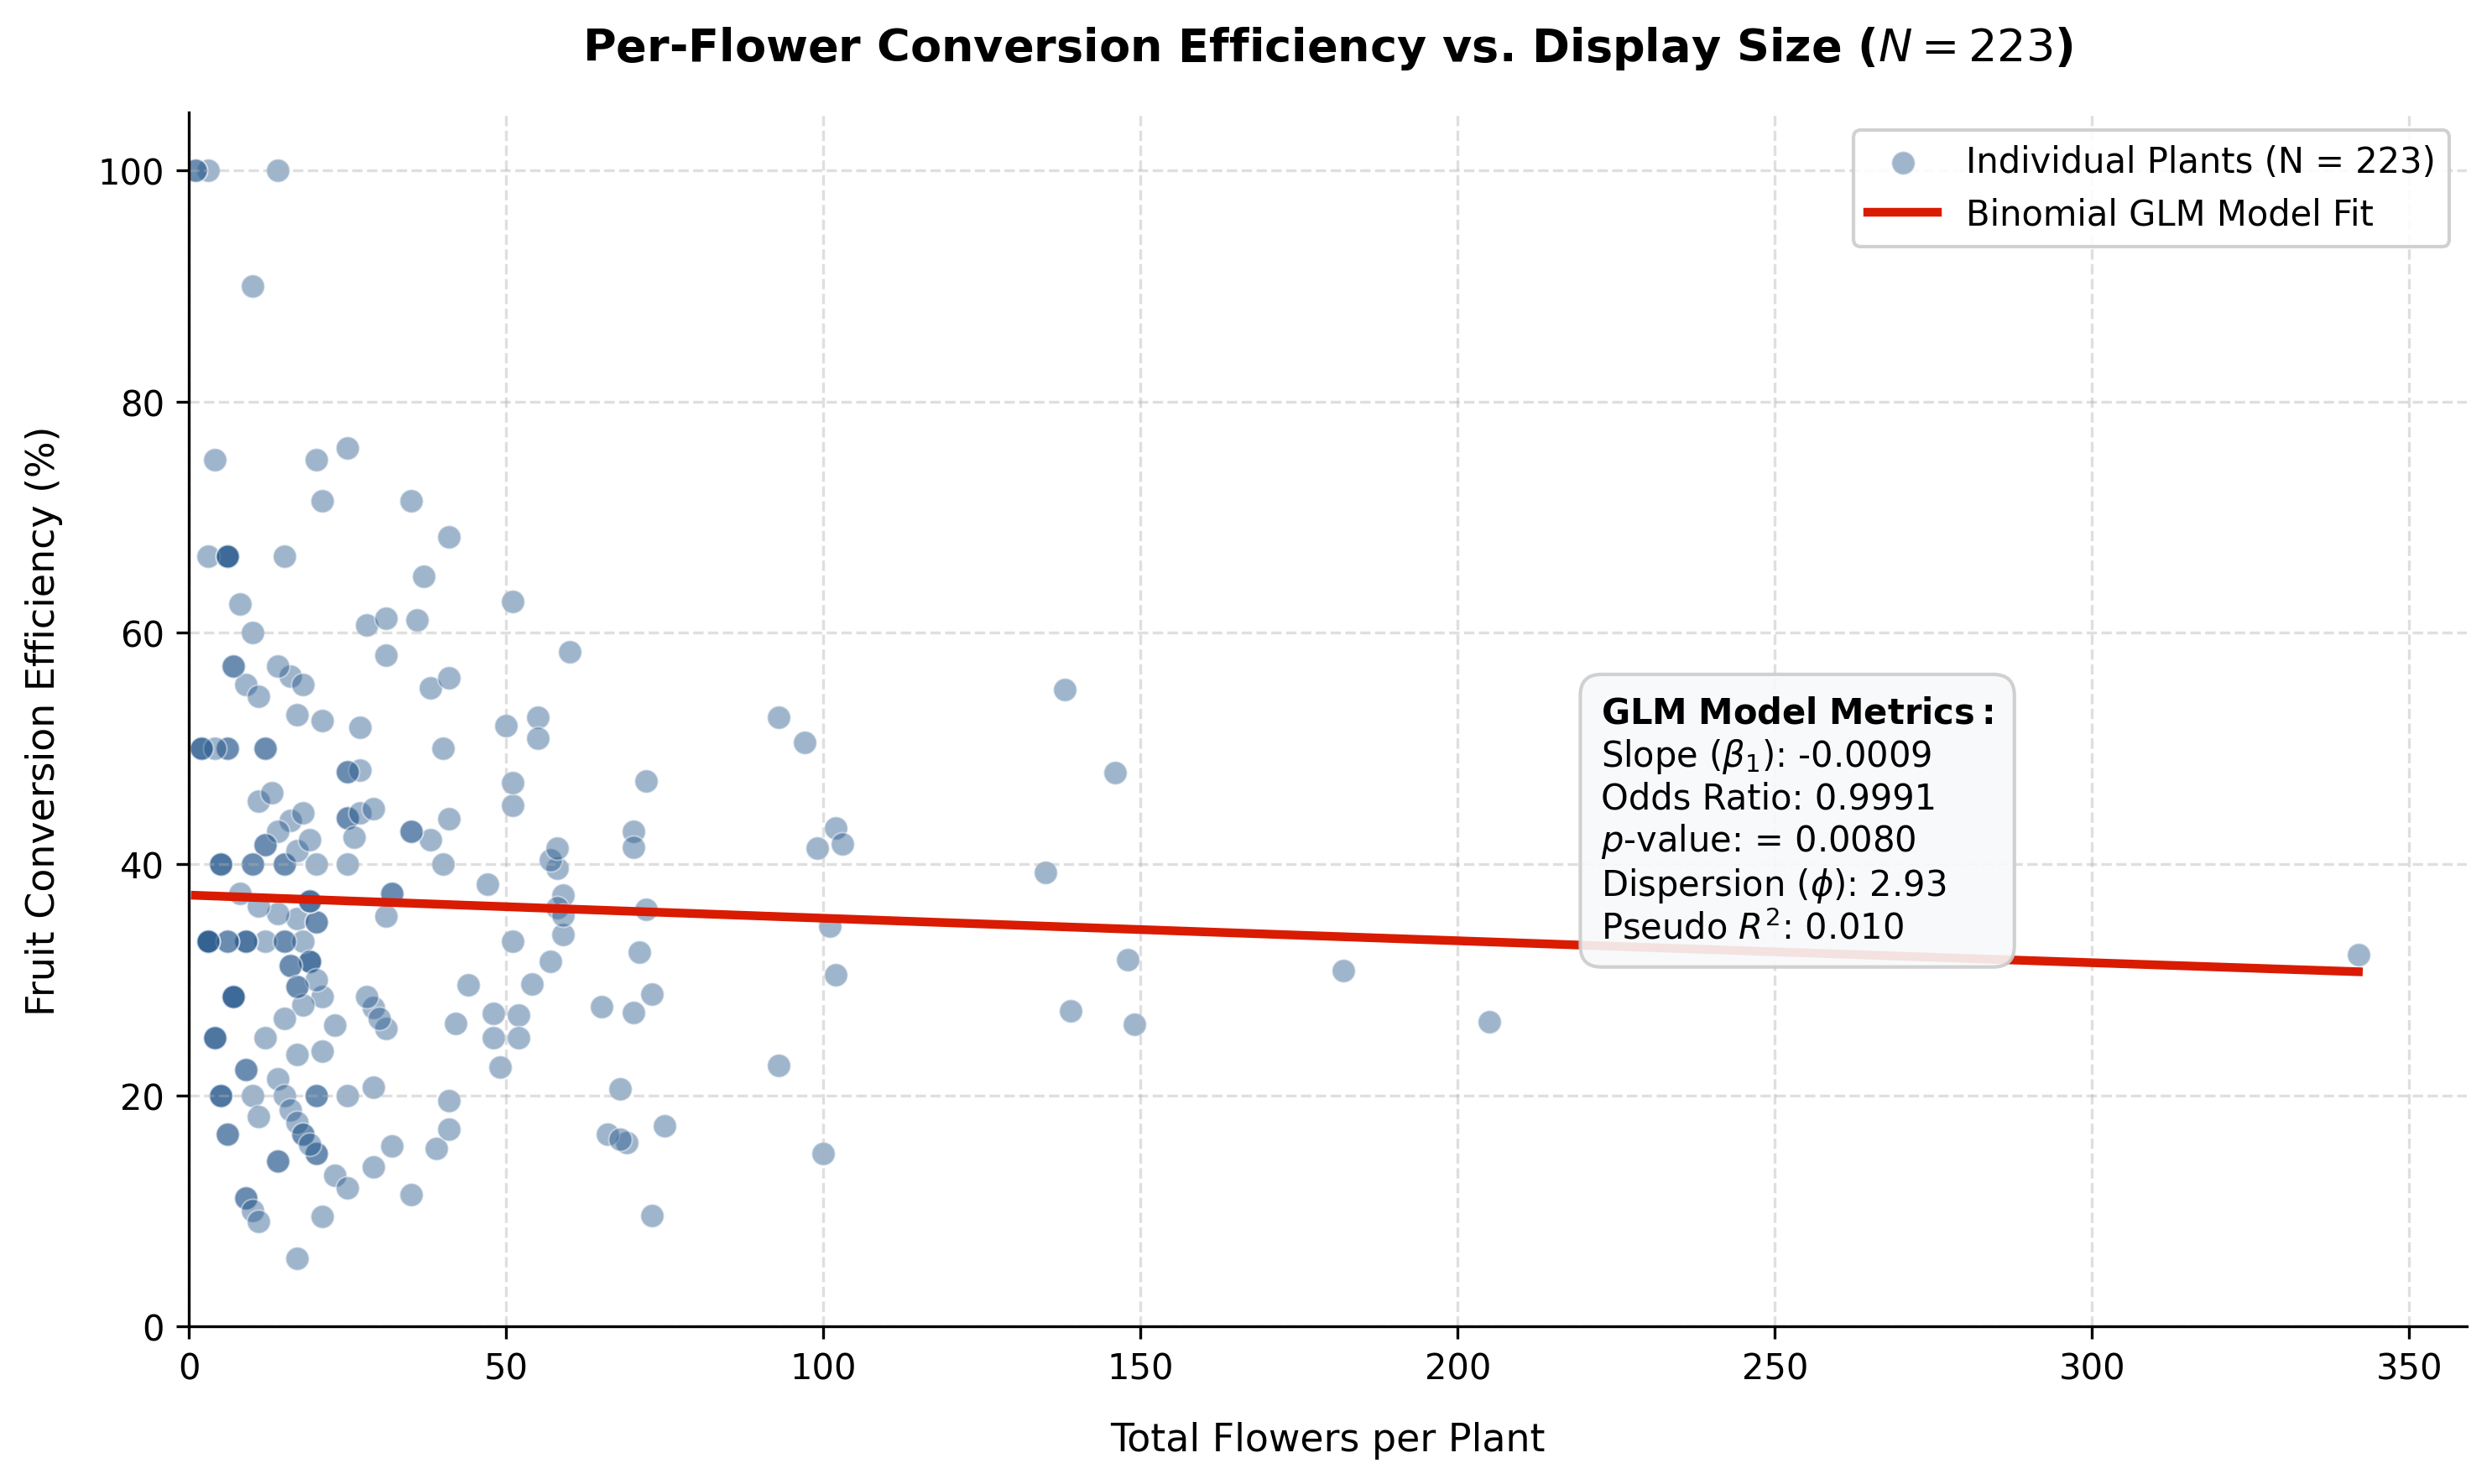

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ==========================================
# 0. LOAD DATAFILE
# ==========================================
csv_path = "../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv"
df = pd.read_csv(csv_path)

# ==========================================
# 1. AGGREGATE AND FILTER DATA
# ==========================================
efficiency_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

df_active = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["seed_max"] >= 1)
    & (efficiency_df["seed_max"] <= efficiency_df["flower_total"])
].copy()

# Calculate observed conversion percentage and failure trials
df_active["efficiency_pct"] = (
    df_active["seed_max"] / df_active["flower_total"]
) * 100
df_active["failures"] = df_active["flower_total"] - df_active["seed_max"]

# ==========================================
# 2. FIT BINOMIAL GLM & EXTRACT STATISTICS
# ==========================================
glm_binom = smf.glm(
    formula="Q('seed_max') + Q('failures') ~ flower_total",
    data=df_active,
    family=sm.families.Binomial(),
).fit()

# Statistical Metrics Extraction
n_obs = int(glm_binom.nobs)
beta_0 = glm_binom.params["Intercept"]
beta_1 = glm_binom.params["flower_total"]
p_val = glm_binom.pvalues["flower_total"]
odds_ratio = np.exp(beta_1)
phi = glm_binom.pearson_chi2 / glm_binom.df_resid  # Overdispersion factor

# McFadden's Pseudo R-squared: 1 - (Deviance_model / Deviance_null)
pseudo_r2 = 1 - (glm_binom.deviance / glm_binom.null_deviance)

# Console Output Audit
print("=== BINOMIAL GLM STATISTICAL SUMMARY ===")
print(f"Sample Size (N):               {n_obs}")
print(f"Intercept (beta_0):            {beta_0:.4f}")
print(f"Slope Coefficient (beta_1):    {beta_1:.4f}")
print(f"Odds Ratio (per flower):       {odds_ratio:.4f}")
print(f"p-value (flower_total):        {p_val:.4e}")
print(f"Dispersion Parameter (phi):    {phi:.3f}")
print(f"McFadden's Pseudo R-squared:   {pseudo_r2:.4f}")
print("========================================\n")

# ==========================================
# 3. GENERATE PREDICTION CURVE
# ==========================================
x_seq = np.linspace(
    df_active["flower_total"].min(), df_active["flower_total"].max(), 300
)
pred_df = pd.DataFrame({"flower_total": x_seq})

# Predict probability (0.0 - 1.0) and scale to percentage (0 - 100%)
pred_df["pred_pct"] = glm_binom.predict(pred_df) * 100

# ==========================================
# 4. PLOTTING WITH ANNOTATED STATS
# ==========================================
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# Observed Plant Efficiencies (Scatter)
ax.scatter(
    df_active["flower_total"],
    df_active["efficiency_pct"],
    alpha=0.45,
    color="#2b5c8f",
    s=45,
    edgecolor="white",
    linewidth=0.5,
    label=f"Individual Plants (N = {n_obs})",
)

# GLM Logistic Trend Line
ax.plot(
    pred_df["flower_total"],
    pred_df["pred_pct"],
    color="#d91b02",
    linewidth=2.5,
    label="Binomial GLM Model Fit",
)

# Statistical Summary Box (Constructed using raw strings to prevent Matplotlib LaTeX syntax errors)
p_formatted = "< 0.001" if p_val < 0.001 else f"= {p_val:.4f}"
stats_text = (
    r"$\mathbf{GLM\ Model\ Metrics:}$" + "\n"
    rf"Slope ($\beta_1$): {beta_1:.4f}" + "\n"
    rf"Odds Ratio: {odds_ratio:.4f}" + "\n"
    rf"$p$-value: {p_formatted}" + "\n"
    rf"Dispersion ($\phi$): {phi:.2f}" + "\n"
    rf"Pseudo $R^2$: {pseudo_r2:.3f}"
)

ax.text(
    0.62,
    0.52,
    stats_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#f8f9fa",
        edgecolor="#cccccc",
        alpha=0.9,
    ),
)

# Formatting
ax.set_title(
    rf"Per-Flower Conversion Efficiency vs. Display Size ($N = {n_obs}$)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Total Flowers per Plant", fontsize=11, labelpad=10)
ax.set_ylabel("Fruit Conversion Efficiency (%)", fontsize=11, labelpad=10)

ax.set_xlim(0, df_active["flower_total"].max() * 1.05)
ax.set_ylim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.savefig("../results/efficiency_glm_with_stats.png", dpi=300)
plt.show()

Because the data was overdispered I decided to model a quasi binomial GLM.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Prepare Data
efficiency_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

df_active = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["seed_max"] >= 1)
    & (efficiency_df["seed_max"] <= efficiency_df["flower_total"])
].copy()

df_active["failures"] = df_active["flower_total"] - df_active["seed_max"]

# ==========================================
# 1. STANDARD BINOMIAL GLM (Baseline)
# ==========================================
glm_binom = smf.glm(
    formula="Q('seed_max') + Q('failures') ~ flower_total",
    data=df_active,
    family=sm.families.Binomial(),
).fit()

# ==========================================
# 2. QUASI-BINOMIAL GLM (Empirical Covariance Correction)
# ==========================================
# Statsmodels handles Quasi-Binomial via cov_type='dispersion' or scaling cov_params
# Dispersion parameter (Pearson chi2 / residual df)
phi = glm_binom.pearson_chi2 / glm_binom.df_resid

# Fit GLM with robust covariance accounting for overdispersion
glm_quasi = smf.glm(
    formula="Q('seed_max') + Q('failures') ~ flower_total",
    data=df_active,
    family=sm.families.Binomial(),
).fit(cov_type="dispersion", cov_kwds={"dispersion": phi})

# ==========================================
# COMPARISON TABLE
# ==========================================
print(f"Calculated Dispersion Scale Factor (Phi): {phi:.3f}\n")

results_summary = pd.DataFrame(
    {
        "Model": ["Standard Binomial", "Quasi-Binomial"],
        "Slope (beta_1)": [
            glm_binom.params["flower_total"],
            glm_quasi.params["flower_total"],
        ],
        "Std Error": [
            glm_binom.bse["flower_total"],
            glm_quasi.bse["flower_total"],
        ],
        "z-stat": [glm_binom.tvalues["flower_total"], glm_quasi.tvalues["flower_total"]],
        "p-value": [
            glm_binom.pvalues["flower_total"],
            glm_quasi.pvalues["flower_total"],
        ],
        "Odds Ratio": [
            np.exp(glm_binom.params["flower_total"]),
            np.exp(glm_quasi.params["flower_total"]),
        ],
    }
)

print(results_summary.to_string(index=False))

ValueError: cov_type not recognized. See docstring for available options and spelling

**Expanding on the model**

Adding different factors using the new datafile:

../data/processed/FINAL_DATA_with_plant_traits.csv


Here I want to look at how the color difference in the plants reflect on the plant efficiency. 

=== EFFICIENCY SUMMARY BY FLOWER COLOUR ===
               Count      Mean    Median       Std
Flower.colour                                     
Hybrid           141  0.416228  0.333333  0.433618
Magenta           67  0.330104  0.333333  0.211021
Yellow             9  0.646005  0.416667  1.004607

Kruskal-Wallis Test across groups: H = 0.788, p = 6.7431e-01



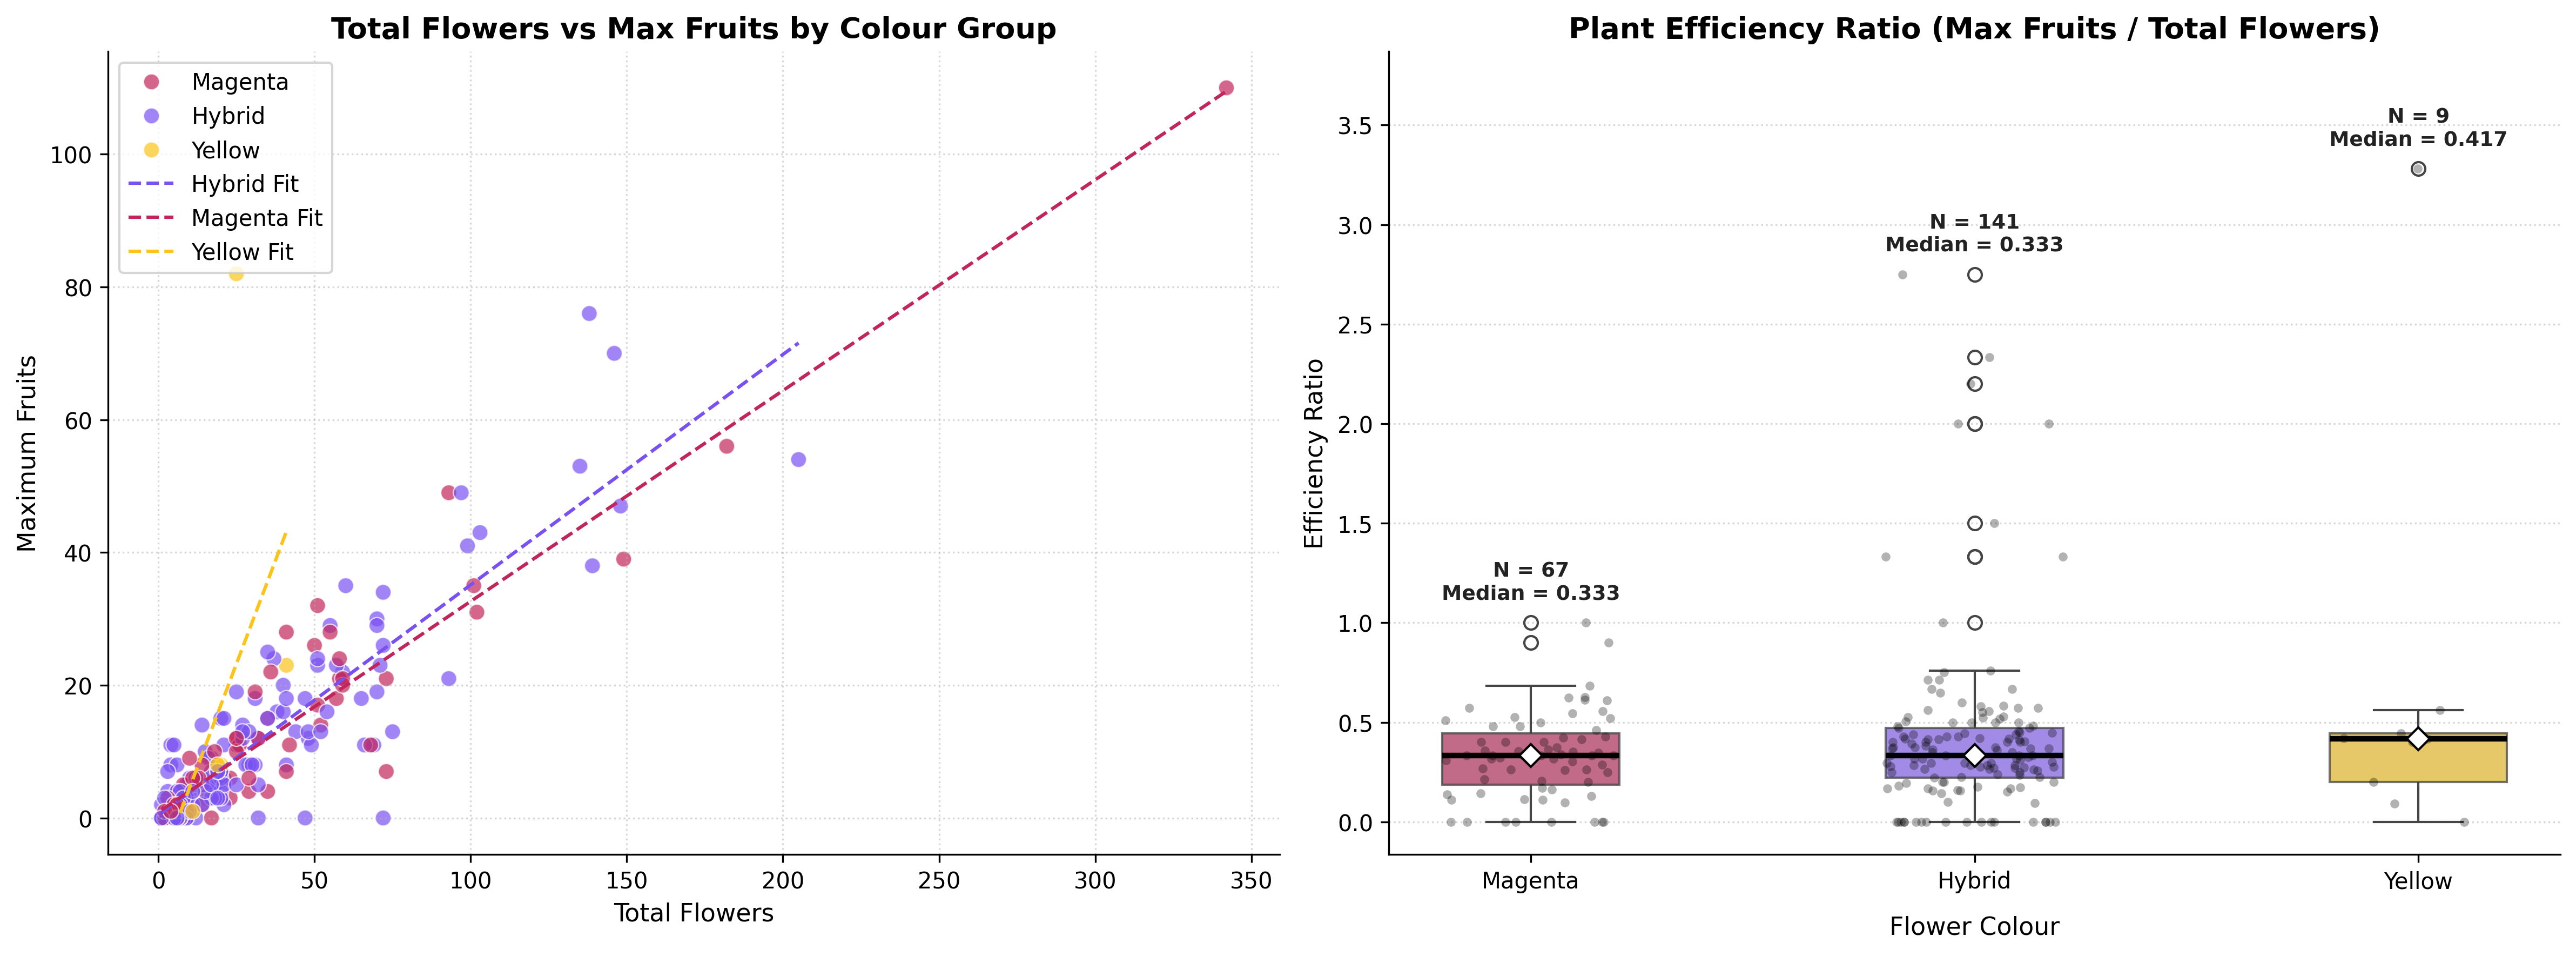

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# ==========================================
# 0. LOAD DATAFILE
# ==========================================
csv_file = "../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv"
df = pd.read_csv(csv_file)

# ==========================================
# 1. CLEAN & ASSIGN CONSENSUS FLOWER COLOUR
# ==========================================
df_clean = df.copy()

# Standardize text in 'Flower.colour'
df_clean["Flower.colour"] = (
    df_clean["Flower.colour"]
    .astype(str)
    .str.strip()
    .str.capitalize()
)

# Identify known valid colors
valid_colors = ["Magenta", "Hybrid", "Yellow"]

# Map valid color per PlantID across the entire dataset
plant_color_map = (
    df_clean[df_clean["Flower.colour"].isin(valid_colors)]
    .groupby("PlantID")["Flower.colour"]
    .first()  # Takes the non-null color entry for each plant
)

# Assign consensus color back to main dataframe
df_clean["ConsensusColour"] = df_clean["PlantID"].map(plant_color_map)

# ==========================================
# 2. AGGREGATE DATA BY PLANT
# ==========================================
efficiency_df = (
    df_clean.groupby(["PlantID", "ConsensusColour"], as_index=False)
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .rename(columns={"ConsensusColour": "Flower.colour"})
)

# Filter: keep only positive flowers and valid color categories
efficiency_df = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["Flower.colour"].isin(valid_colors))
].dropna(subset=["flower_total", "seed_max"]).copy()

# Calculate Plant Efficiency Ratio
efficiency_df["Efficiency"] = (
    efficiency_df["seed_max"] / efficiency_df["flower_total"]
)

# ==========================================
# 3. STATISTICAL ANALYSIS
# ==========================================
print("=== EFFICIENCY SUMMARY BY FLOWER COLOUR ===")
summary = efficiency_df.groupby("Flower.colour")["Efficiency"].agg(
    Count="count", Mean="mean", Median="median", Std="std"
)
print(summary)
print("===========================================\n")

# Extract valid groups for Kruskal-Wallis test
groups = [
    group["Efficiency"].values
    for name, group in efficiency_df.groupby("Flower.colour")
    if len(group) > 0
]

if len(groups) >= 2:
    h_stat, p_val_kw = stats.kruskal(*groups)
    print(f"Kruskal-Wallis Test across groups: H = {h_stat:.3f}, p = {p_val_kw:.4e}\n")
else:
    print(f"Skipping Kruskal-Wallis Test: Found only {len(groups)} group(s) with valid data.\n")

# ==========================================
# 4. VISUALIZATION
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

palette = {"Magenta": "#c2255c", "Hybrid": "#7950f2", "Yellow": "#fcc419"}

# Panel 1: Scatter plot (Flowers vs Fruits by Color)
sns.scatterplot(
    data=efficiency_df,
    x="flower_total",
    y="seed_max",
    hue="Flower.colour",
    palette=palette,
    alpha=0.7,
    s=50,
    ax=ax1,
)

for color, group in efficiency_df.groupby("Flower.colour"):
    if len(group) > 1:
        slope, intercept = np.polyfit(
            group["flower_total"], group["seed_max"], 1
        )
        x_vals = np.array([group["flower_total"].min(), group["flower_total"].max()])
        ax1.plot(
            x_vals,
            intercept + slope * x_vals,
            color=palette[color],
            linestyle="--",
            label=f"{color} Fit",
        )

ax1.set_title(
    "Total Flowers vs Max Fruits by Colour Group", fontsize=13, fontweight="bold"
)
ax1.set_xlabel("Total Flowers", fontsize=11)
ax1.set_ylabel("Maximum Fruits", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="upper left")

# Panel 2: Boxplot comparing Efficiency with Highlighted Medians
sns.boxplot(
    data=efficiency_df,
    x="Flower.colour",
    y="Efficiency",
    hue="Flower.colour",
    order=valid_colors,
    palette=palette,
    legend=False,
    ax=ax2,
    width=0.4,
    boxprops=dict(alpha=0.75),
    medianprops=dict(color="black", linewidth=2.5),
)

sns.stripplot(
    data=efficiency_df,
    x="Flower.colour",
    y="Efficiency",
    order=valid_colors,
    color="black",
    alpha=0.3,
    size=4,
    jitter=0.2,
    ax=ax2,
)

ax2.set_title(
    "Plant Efficiency Ratio (Max Fruits / Total Flowers)",
    fontsize=13,
    fontweight="bold",
)
ax2.set_xlabel("Flower Colour", fontsize=11, labelpad=10)
ax2.set_ylabel("Efficiency Ratio", fontsize=11)
ax2.grid(axis="y", linestyle=":", alpha=0.5)

# Annotate sample sizes AND Medians directly on plot
if not efficiency_df.empty:
    max_eff = efficiency_df["Efficiency"].max()
    for i, color in enumerate(valid_colors):
        group_data = efficiency_df[efficiency_df["Flower.colour"] == color]["Efficiency"]
        n_obs = len(group_data)
        
        if n_obs > 0:
            median_val = group_data.median()
            group_max = group_data.max()
            
            # Overlay distinct diamond marker on median
            ax2.plot(
                i, median_val, marker="D", color="white", markeredgecolor="black", markersize=7, zorder=5
            )
            
            # Text annotation
            ax2.text(
                i,
                group_max + (max_eff * 0.03),
                f"N = {n_obs}\nMedian = {median_val:.3f}",
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
                color="#222222",
            )

    ax2.set_ylim(top=max_eff * 1.18)

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("../results/efficiency_by_flower_colour.png", dpi=300)
plt.show()

How does plant efficiency differ in perennial plant comapred to annual plants?

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# ==========================================
# 1. FILE PATHS & DATA LOADING
# ==========================================
csv_file = "../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv"
sequoia_xltx_path = "../data/raw/CONSENSUS_field_sequoia.xltx"

print("Loading intensive survey dataset...")
df_survey = pd.read_csv(csv_file)

print("Loading Sequoia template dataset...")
df_sequoia = pd.read_excel(sequoia_xltx_path, engine="openpyxl")

# Standardize PlantIDs
df_survey["PlantID"] = df_survey["PlantID"].astype(str).str.strip().str.upper()
df_sequoia["PlantID"] = df_sequoia["PlantID"].astype(str).str.strip().str.upper()

# ==========================================
# 2. SEED & FLOWER AGGREGATION + CONSENSUS COLOUR
# ==========================================
# Clean flower colour values
df_survey["Flower.colour"] = (
    df_survey["Flower.colour"]
    .astype(str)
    .str.strip()
    .str.capitalize()
)

valid_colors = ["Magenta", "Hybrid", "Yellow"]

# Map valid color per PlantID across the entire survey dataset
plant_color_map = (
    df_survey[df_survey["Flower.colour"].isin(valid_colors)]
    .groupby("PlantID")["Flower.colour"]
    .first()
)

# Aggregate flower totals and max fruits per plant
efficiency_df = (
    df_survey.groupby("PlantID", as_index=False)
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
)

# Re-assign consensus color
efficiency_df["Flower.colour"] = efficiency_df["PlantID"].map(plant_color_map)

# Filter valid plants with non-zero flowers and assigned valid color
efficiency_df = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["Flower.colour"].isin(valid_colors))
].dropna(subset=["flower_total", "seed_max"]).copy()

# Compute Efficiency Ratio
efficiency_df["Efficiency"] = efficiency_df["seed_max"] / efficiency_df["flower_total"]

# ==========================================
# 3. MERGE SEQUOIA RECURRENCE METRICS
# ==========================================
alive_cols = [col for col in df_sequoia.columns if col.startswith("AliveRec_")]
print(f"Found {len(alive_cols)} recurrence columns: {alive_cols}")

sequoia_sub = df_sequoia[["PlantID"] + alive_cols].drop_duplicates(subset=["PlantID"])
df_merged = pd.merge(efficiency_df, sequoia_sub, on="PlantID", how="left")

def is_alive(val):
    if pd.isna(val):
        return False
    val_str = str(val).strip().lower()
    return val_str in ["alive", "1", "true"]

df_merged["Years_Recorded_Alive"] = df_merged[alive_cols].apply(
    lambda row: sum(is_alive(val) for val in row), axis=1
)
df_merged["Is_Multiyear_Perennial"] = df_merged["Years_Recorded_Alive"] > 1
df_merged["LifeHistory"] = np.where(df_merged["Is_Multiyear_Perennial"], "Perennial (>1 yr)", "Annual / 1-yr")

# Save combined dataset
df_merged.to_csv("FINAL_DATA_with_perennial_recurrence.csv", index=False)

# ==========================================
# 4. STATISTICAL ANALYSIS
# ==========================================
print("\n=== EFFICIENCY SUMMARY BY FLOWER COLOUR ===")
summary_color = df_merged.groupby("Flower.colour")["Efficiency"].agg(
    Count="count", Mean="mean", Median="median", Std="std"
)
print(summary_color)

color_groups = [
    group["Efficiency"].values
    for _, group in df_merged.groupby("Flower.colour")
    if len(group) > 0
]

if len(color_groups) >= 2:
    h_stat, p_val_kw = stats.kruskal(*color_groups)
    print(f"\nKruskal-Wallis Test (Colour): H = {h_stat:.3f}, p = {p_val_kw:.4e}")

print("\n=== EFFICIENCY SUMMARY BY LIFE HISTORY ===")
summary_life = df_merged.groupby("LifeHistory")["Efficiency"].agg(
    Count="count", Mean="mean", Median="median", Std="std"
)
print(summary_life)

life_groups = [
    group["Efficiency"].values
    for _, group in df_merged.groupby("LifeHistory")
    if len(group) > 0
]

if len(life_groups) == 2:
    u_stat, p_val_mw = stats.mannwhitneyu(life_groups[0], life_groups[1])
    print(f"Mann-Whitney U Test (Life History): U = {u_stat:.3f}, p = {p_val_mw:.4e}\n")

# ==========================================
# 5. VISUALIZATION
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

palette_color = {"Magenta": "#c2255c", "Hybrid": "#7950f2", "Yellow": "#fcc419"}
palette_life = {"Annual / 1-yr": "#4dabf7", "Perennial (>1 yr)": "#40c057"}

# Panel 1: Efficiency by Flower Colour
sns.boxplot(
    data=df_merged,
    x="Flower.colour",
    y="Efficiency",
    hue="Flower.colour",
    order=valid_colors,
    palette=palette_color,
    legend=False,
    ax=ax1,
    width=0.4,
    boxprops=dict(alpha=0.75),
    medianprops=dict(color="black", linewidth=2.5),
)
sns.stripplot(
    data=df_merged,
    x="Flower.colour",
    y="Efficiency",
    order=valid_colors,
    color="black",
    alpha=0.3,
    size=4,
    jitter=0.2,
    ax=ax1,
)

ax1.set_title("Plant Efficiency by Flower Colour", fontsize=13, fontweight="bold")
ax1.set_xlabel("Flower Colour", fontsize=11, labelpad=10)
ax1.set_ylabel("Efficiency Ratio (Fruits / Flowers)", fontsize=11)
ax1.grid(axis="y", linestyle=":", alpha=0.5)

# Annotate Medians & N for Panel 1
if not df_merged.empty:
    max_eff = df_merged["Efficiency"].max()
    for i, color in enumerate(valid_colors):
        group_data = df_merged[df_merged["Flower.colour"] == color]["Efficiency"]
        n_obs = len(group_data)
        if n_obs > 0:
            median_val = group_data.median()
            group_max = group_data.max()
            ax1.plot(i, median_val, marker="D", color="white", markeredgecolor="black", markersize=7, zorder=5)
            ax1.text(
                i, group_max + (max_eff * 0.03),
                f"N = {n_obs}\nMedian = {median_val:.3f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold", color="#222222"
            )
    ax1.set_ylim(top=max_eff * 1.18)

# Panel 2: Efficiency by Life History Recurrence
life_order = ["Annual / 1-yr", "Perennial (>1 yr)"]
sns.boxplot(
    data=df_merged,
    x="LifeHistory",
    y="Efficiency",
    hue="LifeHistory",
    order=life_order,
    palette=palette_life,
    legend=False,
    ax=ax2,
    width=0.4,
    boxprops=dict(alpha=0.75),
    medianprops=dict(color="black", linewidth=2.5),
)
sns.stripplot(
    data=df_merged,
    x="LifeHistory",
    y="Efficiency",
    order=life_order,
    color="black",
    alpha=0.3,
    size=4,
    jitter=0.2,
    ax=ax2,
)

ax2.set_title("Plant Efficiency by Life History (Sequoia Recurrence)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Recurrence Status", fontsize=11, labelpad=10)
ax2.set_ylabel("Efficiency Ratio (Fruits / Flowers)", fontsize=11)
ax2.grid(axis="y", linestyle=":", alpha=0.5)

# Annotate Medians & N for Panel 2
if not df_merged.empty:
    for i, life_stage in enumerate(life_order):
        group_data = df_merged[df_merged["LifeHistory"] == life_stage]["Efficiency"]
        n_obs = len(group_data)
        if n_obs > 0:
            median_val = group_data.median()
            group_max = group_data.max()
            ax2.plot(i, median_val, marker="D", color="white", markeredgecolor="black", markersize=7, zorder=5)
            ax2.text(
                i, group_max + (max_eff * 0.03),
                f"N = {n_obs}\nMedian = {median_val:.3f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold", color="#222222"
            )
    ax2.set_ylim(top=max_eff * 1.18)

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("efficiency_by_colour_and_recurrence.png", dpi=300)
plt.show()

Loading intensive survey dataset...
Loading Sequoia template dataset...


FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/CONSENSUS_field_sequoia.xltx'

=== EFFICIENCY SUMMARY BY MULTIYEAR PERENNIAL STATUS ===
              Count      Mean    Median       Std
Is_Perennial                                     
No              261  0.433371  0.333333  0.586778
Yes              26  0.364548  0.353107  0.170241

Mann-Whitney U Test: U = 3787.5, p = 3.2778e-01



/var/folders/7b/tyzwtcv13pz7k6db8rvxss_r0000gn/T/ipykernel_71643/3953319334.py:118: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


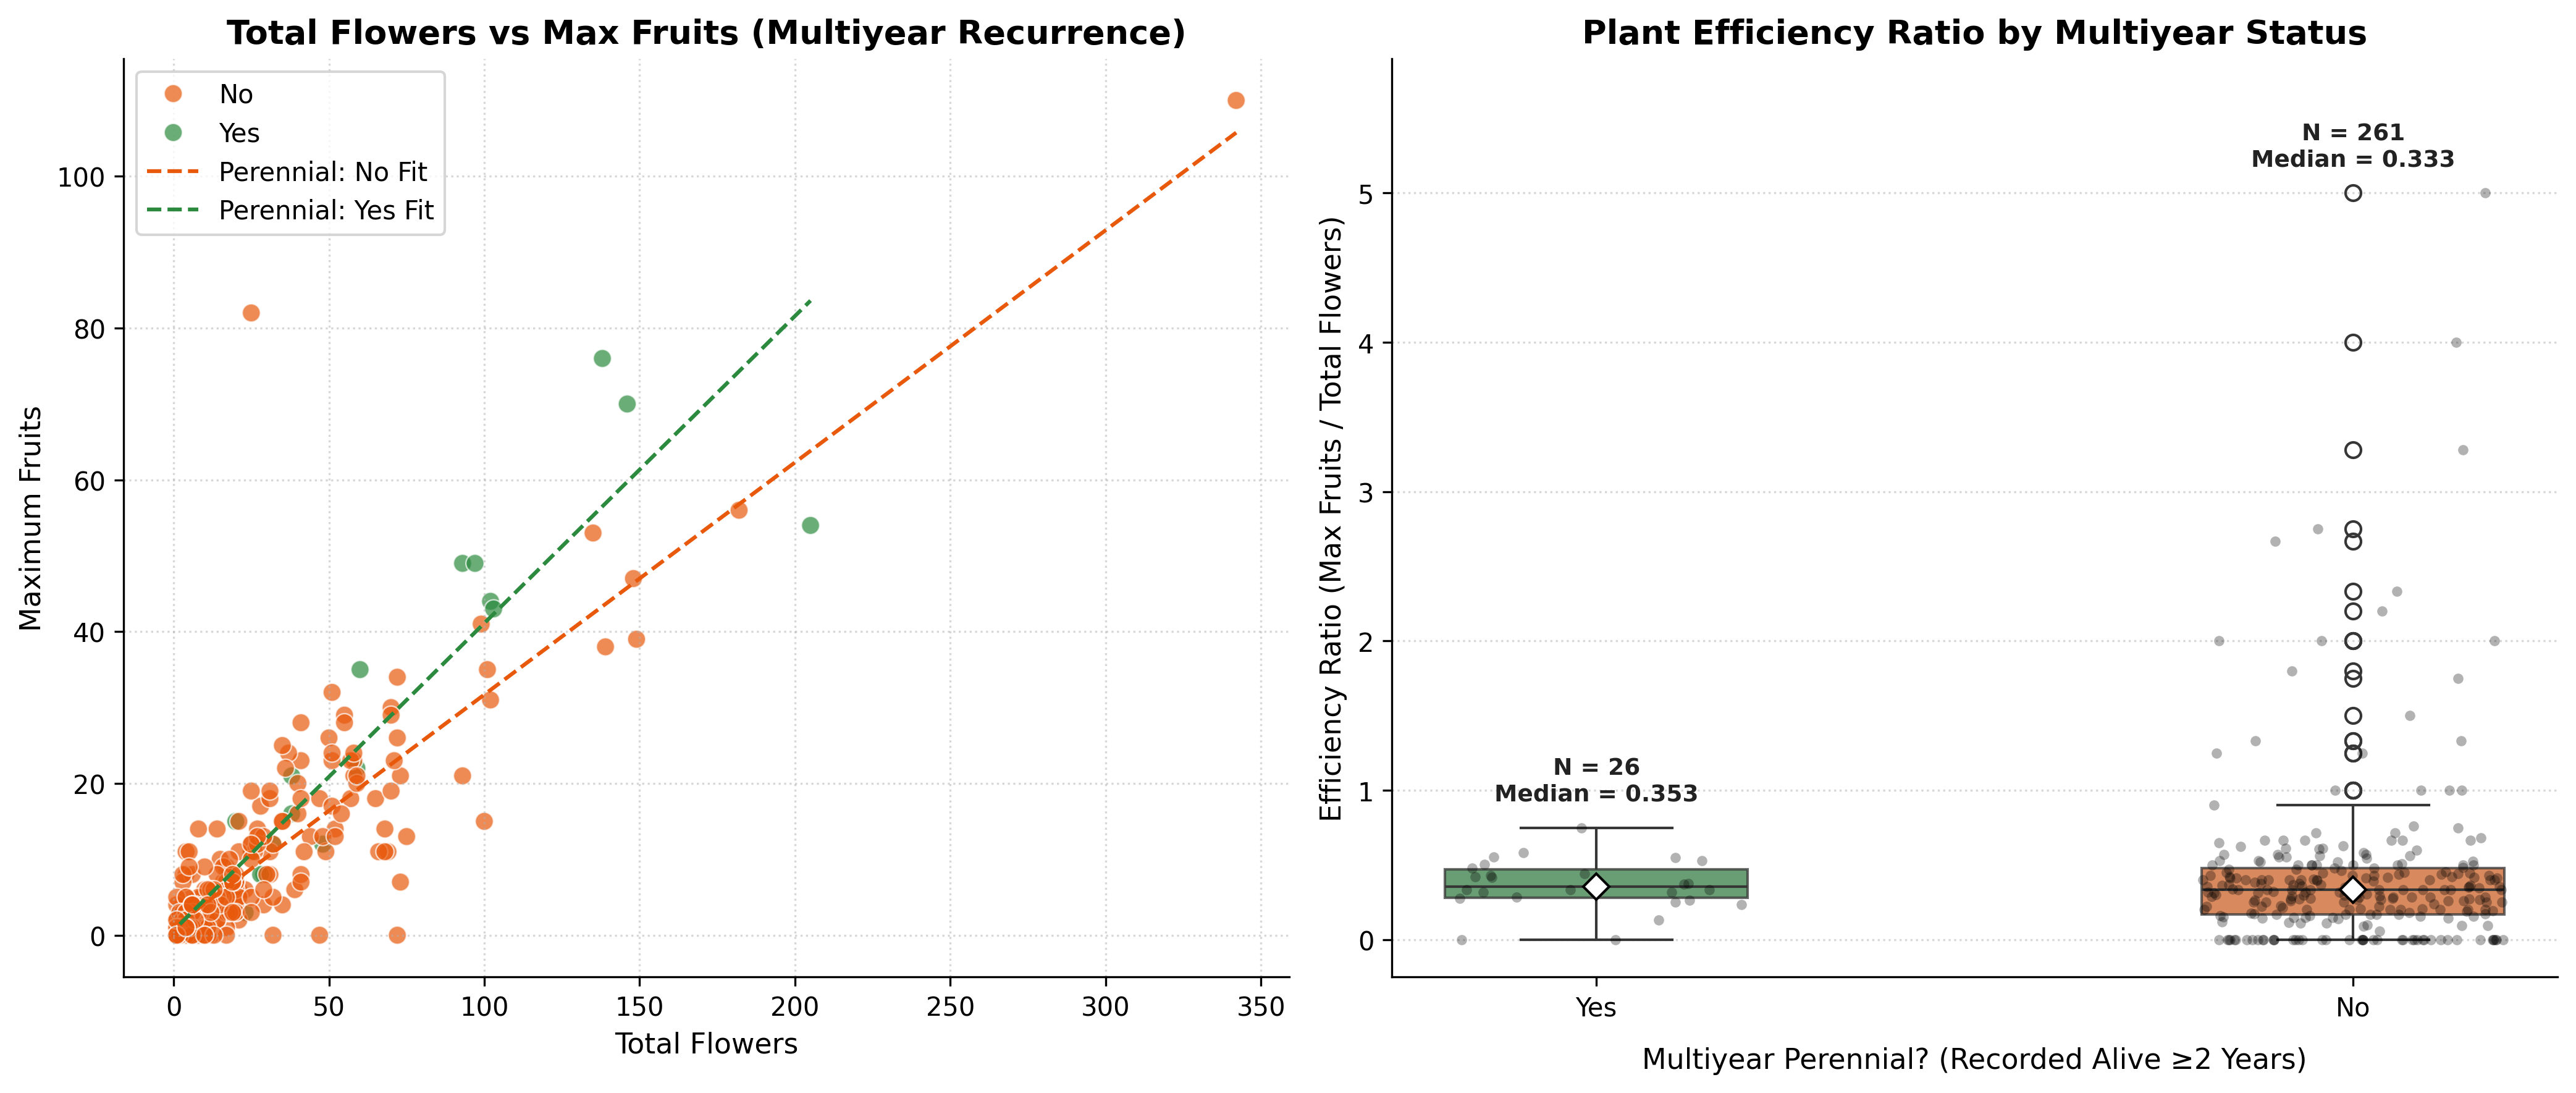

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 0. LOAD ENRICHED DATASET
file_path = "../data/processed/07_FINAL_merged_with_consensus_IntensiveSurvey2025.csv"
df = pd.read_csv(file_path)

# Normalize column headers and key values
df.columns = df.columns.astype(str).str.strip().str.replace("\ufeff", "")
df["PlantID"] = df["PlantID"].astype(str).str.strip().str.upper()

# Handle variations in flower and fruit count column names
flower_col = "Estim.Flowers.Nr" if "Estim.Flowers.Nr" in df.columns else "Estim.Flowers.No"
fruit_col = "Estim.Fruits.Nr" if "Estim.Fruits.Nr" in df.columns else "Estim.Fruits.No"

# 1. AGGREGATE & FILTER DATA BY PLANT
efficiency_df = (
    df.groupby(["PlantID", "Perennial"], as_index=False)
    .agg(
        flower_total=(flower_col, "sum"),
        seed_max=(fruit_col, "max"),
    )
    .dropna(subset=["Perennial", "flower_total", "seed_max"])
)

# Standardize 'Perennial' column values into 'Yes' / 'No'
efficiency_df["Is_Perennial"] = (
    efficiency_df["Perennial"]
    .astype(str)
    .str.strip()
    .str.capitalize()  # Converts 'YES', 'Yes', 'yes' -> 'Yes'
)

valid_perennial_vals = ["Yes", "No"]
efficiency_df = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["Is_Perennial"].isin(valid_perennial_vals))
].copy()

# 2. CALCULATE PLANT EFFICIENCY SAFELY
efficiency_df["Efficiency"] = (
    efficiency_df["seed_max"] / efficiency_df["flower_total"]
)

# Clean out division by zero (Inf) or NaN values
efficiency_df["Efficiency"] = efficiency_df["Efficiency"].replace(
    [np.inf, -np.inf], np.nan
)
efficiency_df = efficiency_df.dropna(subset=["Efficiency"]).copy()

if efficiency_df.empty:
    raise ValueError(
        "No valid efficiency records remain after filtering! Check flower/fruit column values and 'Perennial' entries."
    )

# --- TERMINAL STATISTICAL ANALYSIS ---
print("=== EFFICIENCY SUMMARY BY MULTIYEAR PERENNIAL STATUS ===")
summary = efficiency_df.groupby("Is_Perennial")["Efficiency"].agg(
    Count="count", Mean="mean", Median="median", Std="std"
)
print(summary)
print("=======================================================\n")

# Mann-Whitney U Test (Comparing Perennial Yes vs No)
perennial_yes = efficiency_df[efficiency_df["Is_Perennial"] == "Yes"]["Efficiency"].values
perennial_no = efficiency_df[efficiency_df["Is_Perennial"] == "No"]["Efficiency"].values

if len(perennial_yes) > 0 and len(perennial_no) > 0:
    u_stat, p_val_mwu = stats.mannwhitneyu(perennial_yes, perennial_no, alternative="two-sided")
    print(f"Mann-Whitney U Test: U = {u_stat:.1f}, p = {p_val_mwu:.4e}\n")
else:
    print("⚠️ Warning: One of the perennial groups (Yes/No) has 0 observations; skipping Mann-Whitney test.")

# 3. VISUALIZATION
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

palette = {"Yes": "#2b8a3e", "No": "#e8590c"}  # Green = Multiyear, Orange = Single-year

# Panel 1: Scatter plot (Flowers vs Fruits by Perennial Status)
sns.scatterplot(
    data=efficiency_df,
    x="flower_total",
    y="seed_max",
    hue="Is_Perennial",
    palette=palette,
    alpha=0.7,
    s=50,
    ax=ax1,
)

# Group-specific regression lines
for status, group in efficiency_df.groupby("Is_Perennial"):
    if len(group) > 1:
        slope, intercept = np.polyfit(
            group["flower_total"], group["seed_max"], 1
        )
        x_vals = np.array([group["flower_total"].min(), group["flower_total"].max()])
        ax1.plot(
            x_vals,
            intercept + slope * x_vals,
            color=palette.get(status, "#333333"),
            linestyle="--",
            label=f"Perennial: {status} Fit",
        )

ax1.set_title(
    "Total Flowers vs Max Fruits (Multiyear Recurrence)", fontsize=13, fontweight="bold"
)
ax1.set_xlabel("Total Flowers", fontsize=11)
ax1.set_ylabel("Maximum Fruits", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="upper left")

# Panel 2: Boxplot comparing Efficiency directly
sns.boxplot(
    data=efficiency_df,
    x="Is_Perennial",
    y="Efficiency",
    order=valid_perennial_vals,
    palette=palette,
    ax=ax2,
    width=0.4,
    boxprops=dict(alpha=0.75),
)

sns.stripplot(
    data=efficiency_df,
    x="Is_Perennial",
    y="Efficiency",
    order=valid_perennial_vals,
    color="black",
    alpha=0.3,
    size=4,
    jitter=0.2,
    ax=ax2,
)

ax2.set_title(
    "Plant Efficiency Ratio by Multiyear Status",
    fontsize=13,
    fontweight="bold",
)
ax2.set_xlabel("Multiyear Perennial? (Recorded Alive ≥2 Years)", fontsize=11, labelpad=10)
ax2.set_ylabel("Efficiency Ratio (Max Fruits / Total Flowers)", fontsize=11)
ax2.grid(axis="y", linestyle=":", alpha=0.5)

# Annotate sample sizes AND Medians directly on plot
max_eff = efficiency_df["Efficiency"].max()
for i, status in enumerate(valid_perennial_vals):
    group_data = efficiency_df[efficiency_df["Is_Perennial"] == status]["Efficiency"]
    n_obs = len(group_data)

    if n_obs > 0:
        median_val = group_data.median()
        group_max = group_data.max()

        # Distinct diamond marker on median bar
        ax2.plot(
            i, median_val, marker="D", color="white", markeredgecolor="black", markersize=7, zorder=5
        )

        # Text annotation: N count + Median
        ax2.text(
            i,
            group_max + (max_eff * 0.03),
            f"N = {n_obs}\nMedian = {median_val:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="#222222",
        )

# Safe y-axis top limit
if pd.notna(max_eff) and np.isfinite(max_eff) and max_eff > 0:
    ax2.set_ylim(top=max_eff * 1.18)

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("efficiency_by_perennial_status.png", dpi=300)
plt.show()

Q4: **Does the efficiency have any special distribution?**

In order to see if the efficiency of the plants are distributed unequally on the map we will plot the efficiency score for each plants geographical location. 

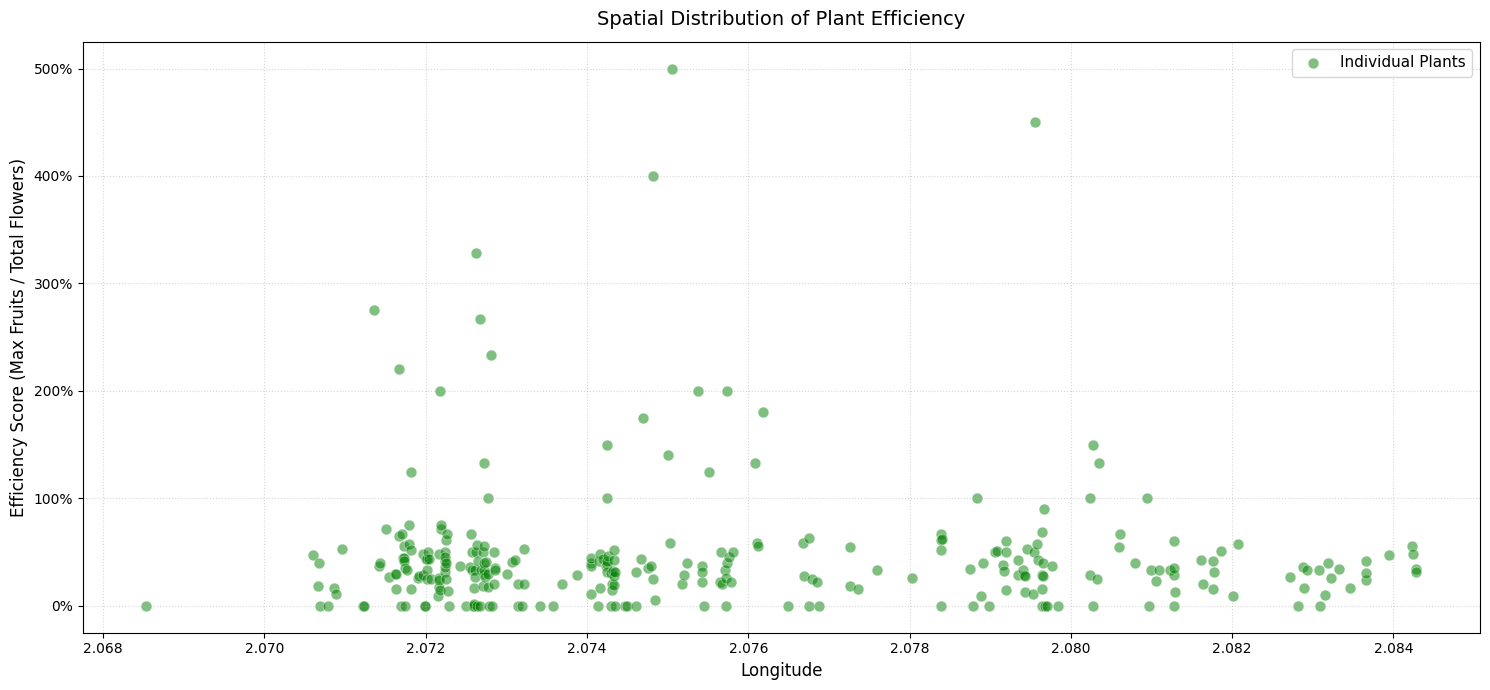

In [ ]:
# efficiency in to a colog gradient 

plant_df = df.groupby('PlantID').agg(
    flower_total=('Estim.Flowers.Nr', 'sum'),
    seed_max=('Estim.Fruits.Nr', 'max'),
).reset_index()

# Calculate Efficiency Score
plant_df['efficiency'] = plant_df['seed_max'] / plant_df['flower_total']

location_df = df_coordinates.groupby('PlantID').agg(
    latitude=('Latitude', 'first'),
    longitude=('Longitude', 'first')
).reset_index()

# Merge the two data set together. 
merged_df = pd.merge(plant_df, location_df, on='PlantID', how='inner')
# Sort along your spatial axis (e.g., Longitude or Latitude)
merged_df = merged_df.sort_values('longitude')

fig, ax = plt.subplots(figsize=(15, 7))

ax.scatter(
    merged_df['longitude'], # x-axis: Longitude
    merged_df['efficiency'], # y-axis: Efficiency Score
    s=60, 
    c='g', 
    alpha=0.5, 
    edgecolors='w', 
    linewidth=0.5,
    label='Individual Plants'
)

ax.set_title('Spatial Distribution of Plant Efficiency', fontsize=14, pad=12)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Efficiency Score (Max Fruits / Total Flowers)', fontsize=12)

# Format Y-axis as percentage (0% - 100%)
ax.yaxis.set_major_formatter('{x:.0%}')

ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

=== SPATIAL GRADIENT ANALYSIS (LONGITUDE VS. EFFICIENCY) ===
Sample Size (N): 269 plants
Spearman Correlation (rho): -0.0110
P-value: 8.5751e-01
RESULT: No statistically significant spatial gradient across Longitude (Random distribution).



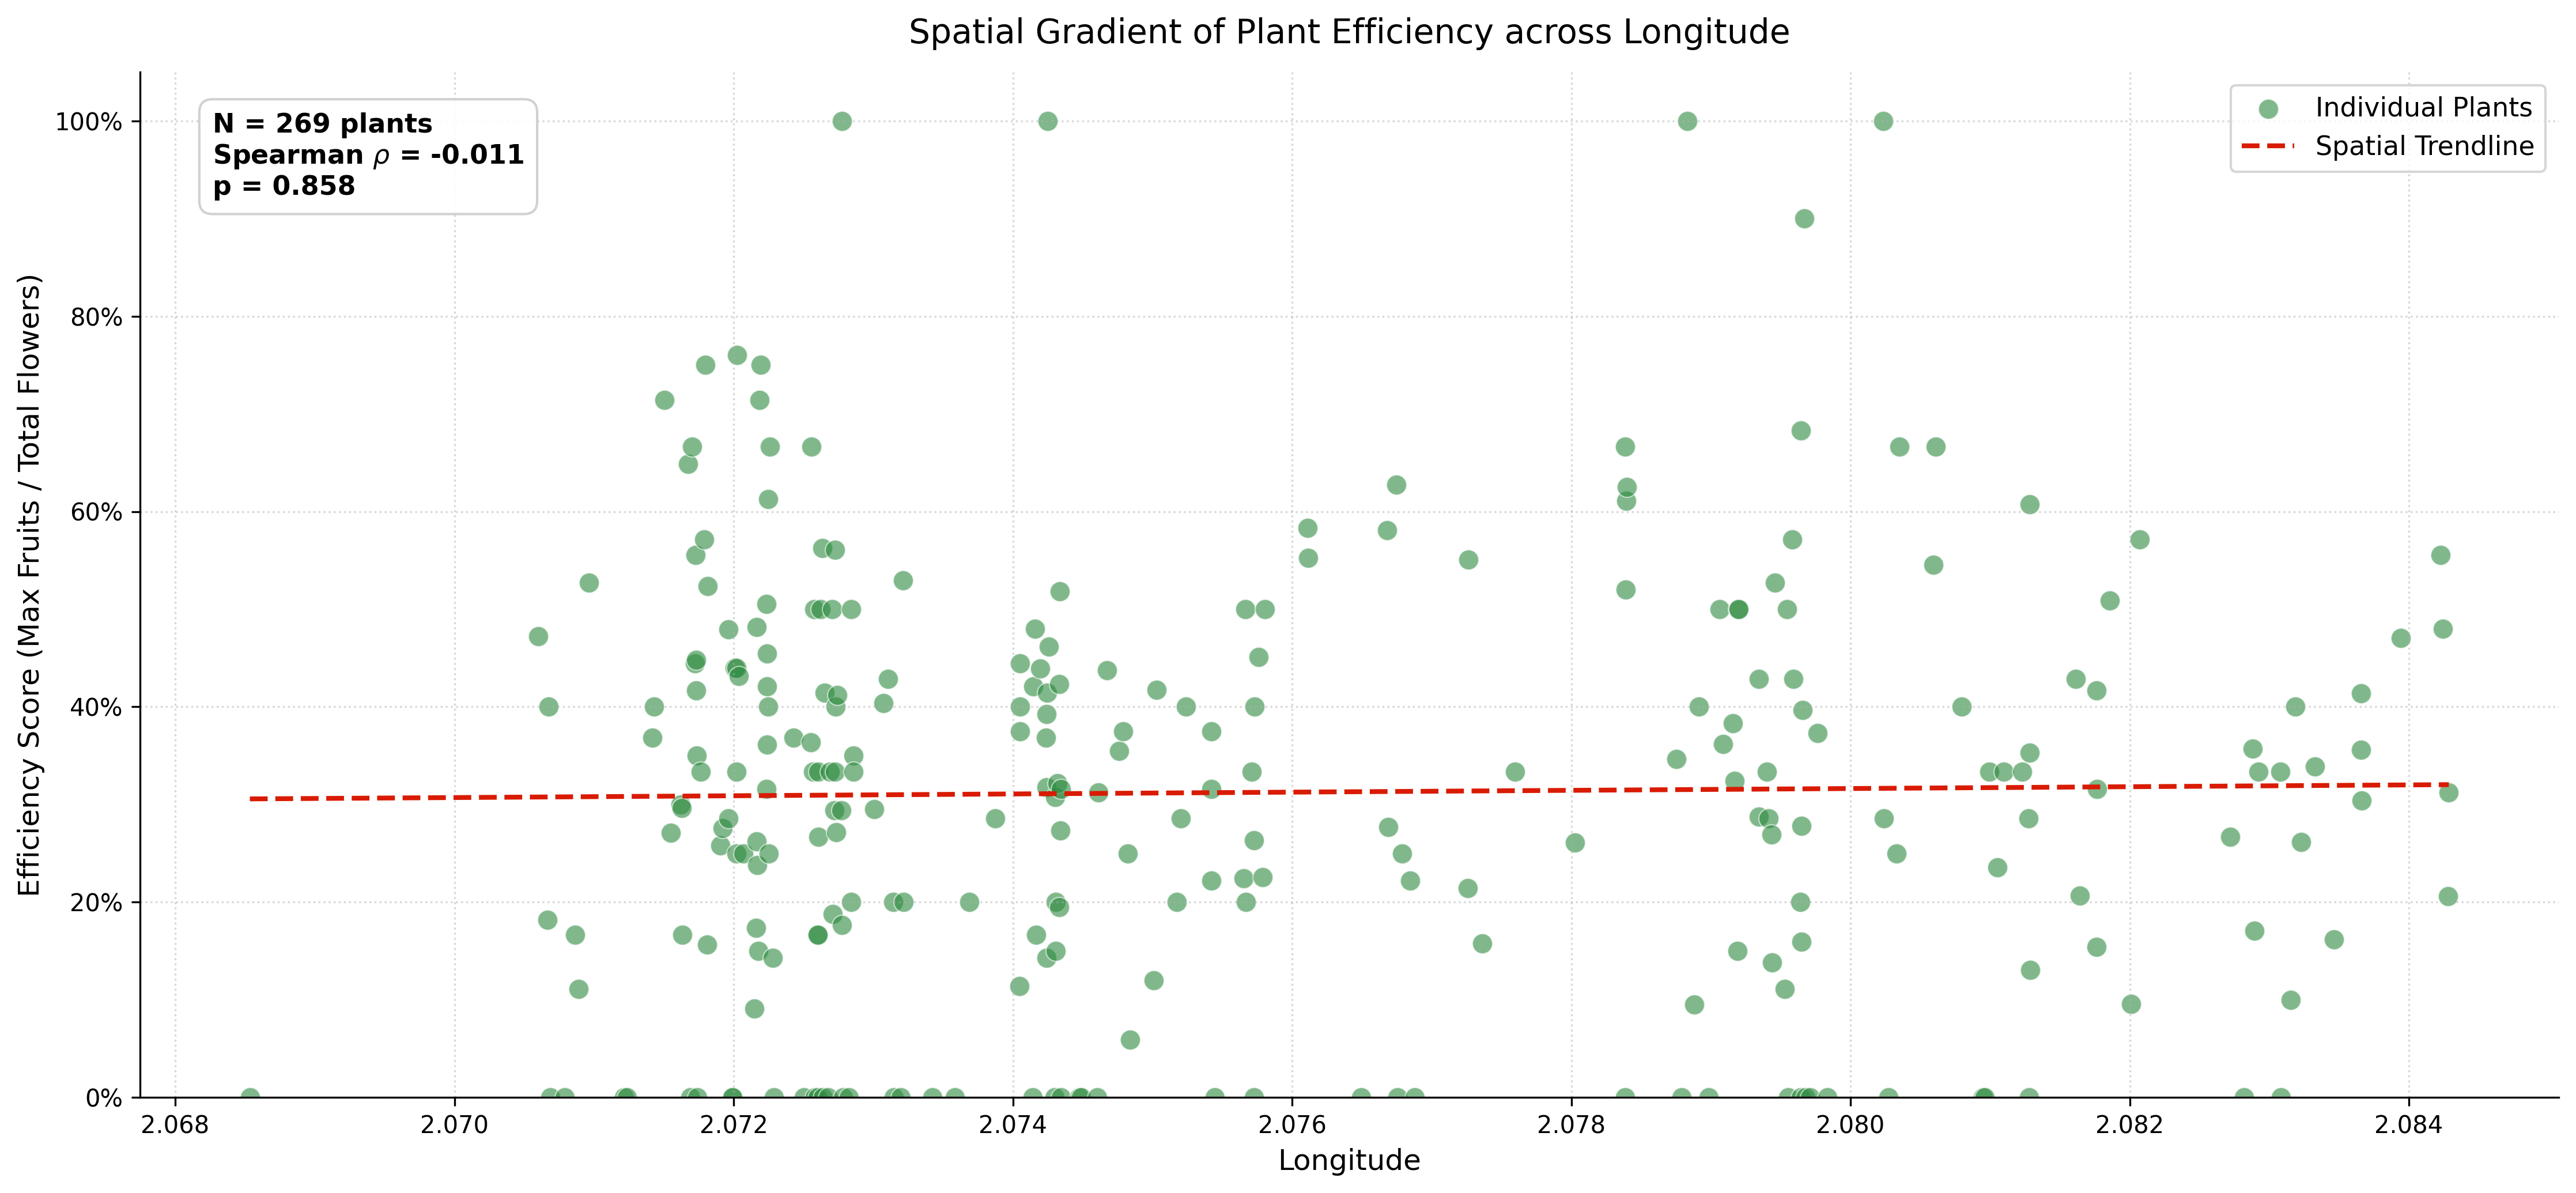

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats

# 1. AGGREGATE & MERGE DATA
plant_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

# Calculate Efficiency Score
plant_df["efficiency"] = plant_df["seed_max"] / plant_df["flower_total"]

location_df = (
    df_coordinates.groupby("PlantID")
    .agg(latitude=("Latitude", "first"), longitude=("Longitude", "first"))
    .reset_index()
)

# Merge the two datasets
merged_df = pd.merge(plant_df, location_df, on="PlantID", how="inner")

# Clean data: keep standard biological range (0% to 100%) and valid coordinates
merged_df = merged_df[
    (merged_df["efficiency"] <= 1.0)
    & (merged_df["efficiency"].notna())
    & (merged_df["longitude"].notna())
].copy()

merged_df = merged_df.sort_values("longitude")

# 2. QUANTIFY SPATIAL GRADIENT (Spearman Rank Correlation)
rho, p_val = stats.spearmanr(merged_df["longitude"], merged_df["efficiency"])

print("=== SPATIAL GRADIENT ANALYSIS (LONGITUDE VS. EFFICIENCY) ===")
print(f"Sample Size (N): {len(merged_df)} plants")
print(f"Spearman Correlation (rho): {rho:.4f}")
print(f"P-value: {p_val:.4e}")

if p_val < 0.05:
    if rho > 0:
        print("RESULT: Significant positive spatial gradient (Efficiency increases moving East).")
    else:
        print("RESULT: Significant negative spatial gradient (Efficiency decreases moving East).")
else:
    print("RESULT: No statistically significant spatial gradient across Longitude (Random distribution).")
print("============================================================\n")

# 3. VISUALIZATION
fig, ax = plt.subplots(figsize=(15, 7), dpi=300)

# Scatter plot
ax.scatter(
    merged_df["longitude"],
    merged_df["efficiency"],
    s=70,
    c="#2b8a3e",
    alpha=0.6,
    edgecolors="w",
    linewidth=0.5,
    label="Individual Plants",
)

# Fit linear trendline across Longitude
x_long = merged_df["longitude"].values
y_eff = merged_df["efficiency"].values

slope, intercept = np.polyfit(x_long, y_eff, 1)
x_line = np.array([x_long.min(), x_long.max()])
y_line = intercept + slope * x_line

ax.plot(
    x_line,
    y_line,
    color="#d91b02",
    linestyle="--",
    linewidth=2,
    label="Spatial Trendline",
)

# Titles & Formatting
ax.set_title("Spatial Gradient of Plant Efficiency across Longitude", fontsize=14, pad=12)
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Efficiency Score (Max Fruits / Total Flowers)", fontsize=12)

# Format Y-axis as percentage (0% - 100%)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.set_ylim(bottom=0, top=min(1.05, merged_df["efficiency"].max() * 1.05))

# Annotate correlation results on plot
p_text = "< 0.001" if p_val < 0.001 else f"= {p_val:.3f}"
annot_text = f"N = {len(merged_df)} plants\nSpearman $\\rho$ = {rho:.3f}\np {p_text}"
ax.text(
    0.03,
    0.88,
    annot_text,
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9, edgecolor="#cccccc"),
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()

look at the calculation of the efficiency because it seems off?

I will make the same plot but use the longitudinal coordinates on the y axis and mark efficiency as a color gradient. 

=== SPATIAL CLUSTERING ANALYSIS (GLOBAL MORAN'S I) ===
Sample Size (N): 269 plants
Observed Moran's I: -0.0315
Expected Moran's I (under randomness): -0.0037
Z-Score: -0.8645
P-value (Permutations): 2.1500e-01
RESULT: No statistically significant spatial clustering observed (Random distribution).



/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 5 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


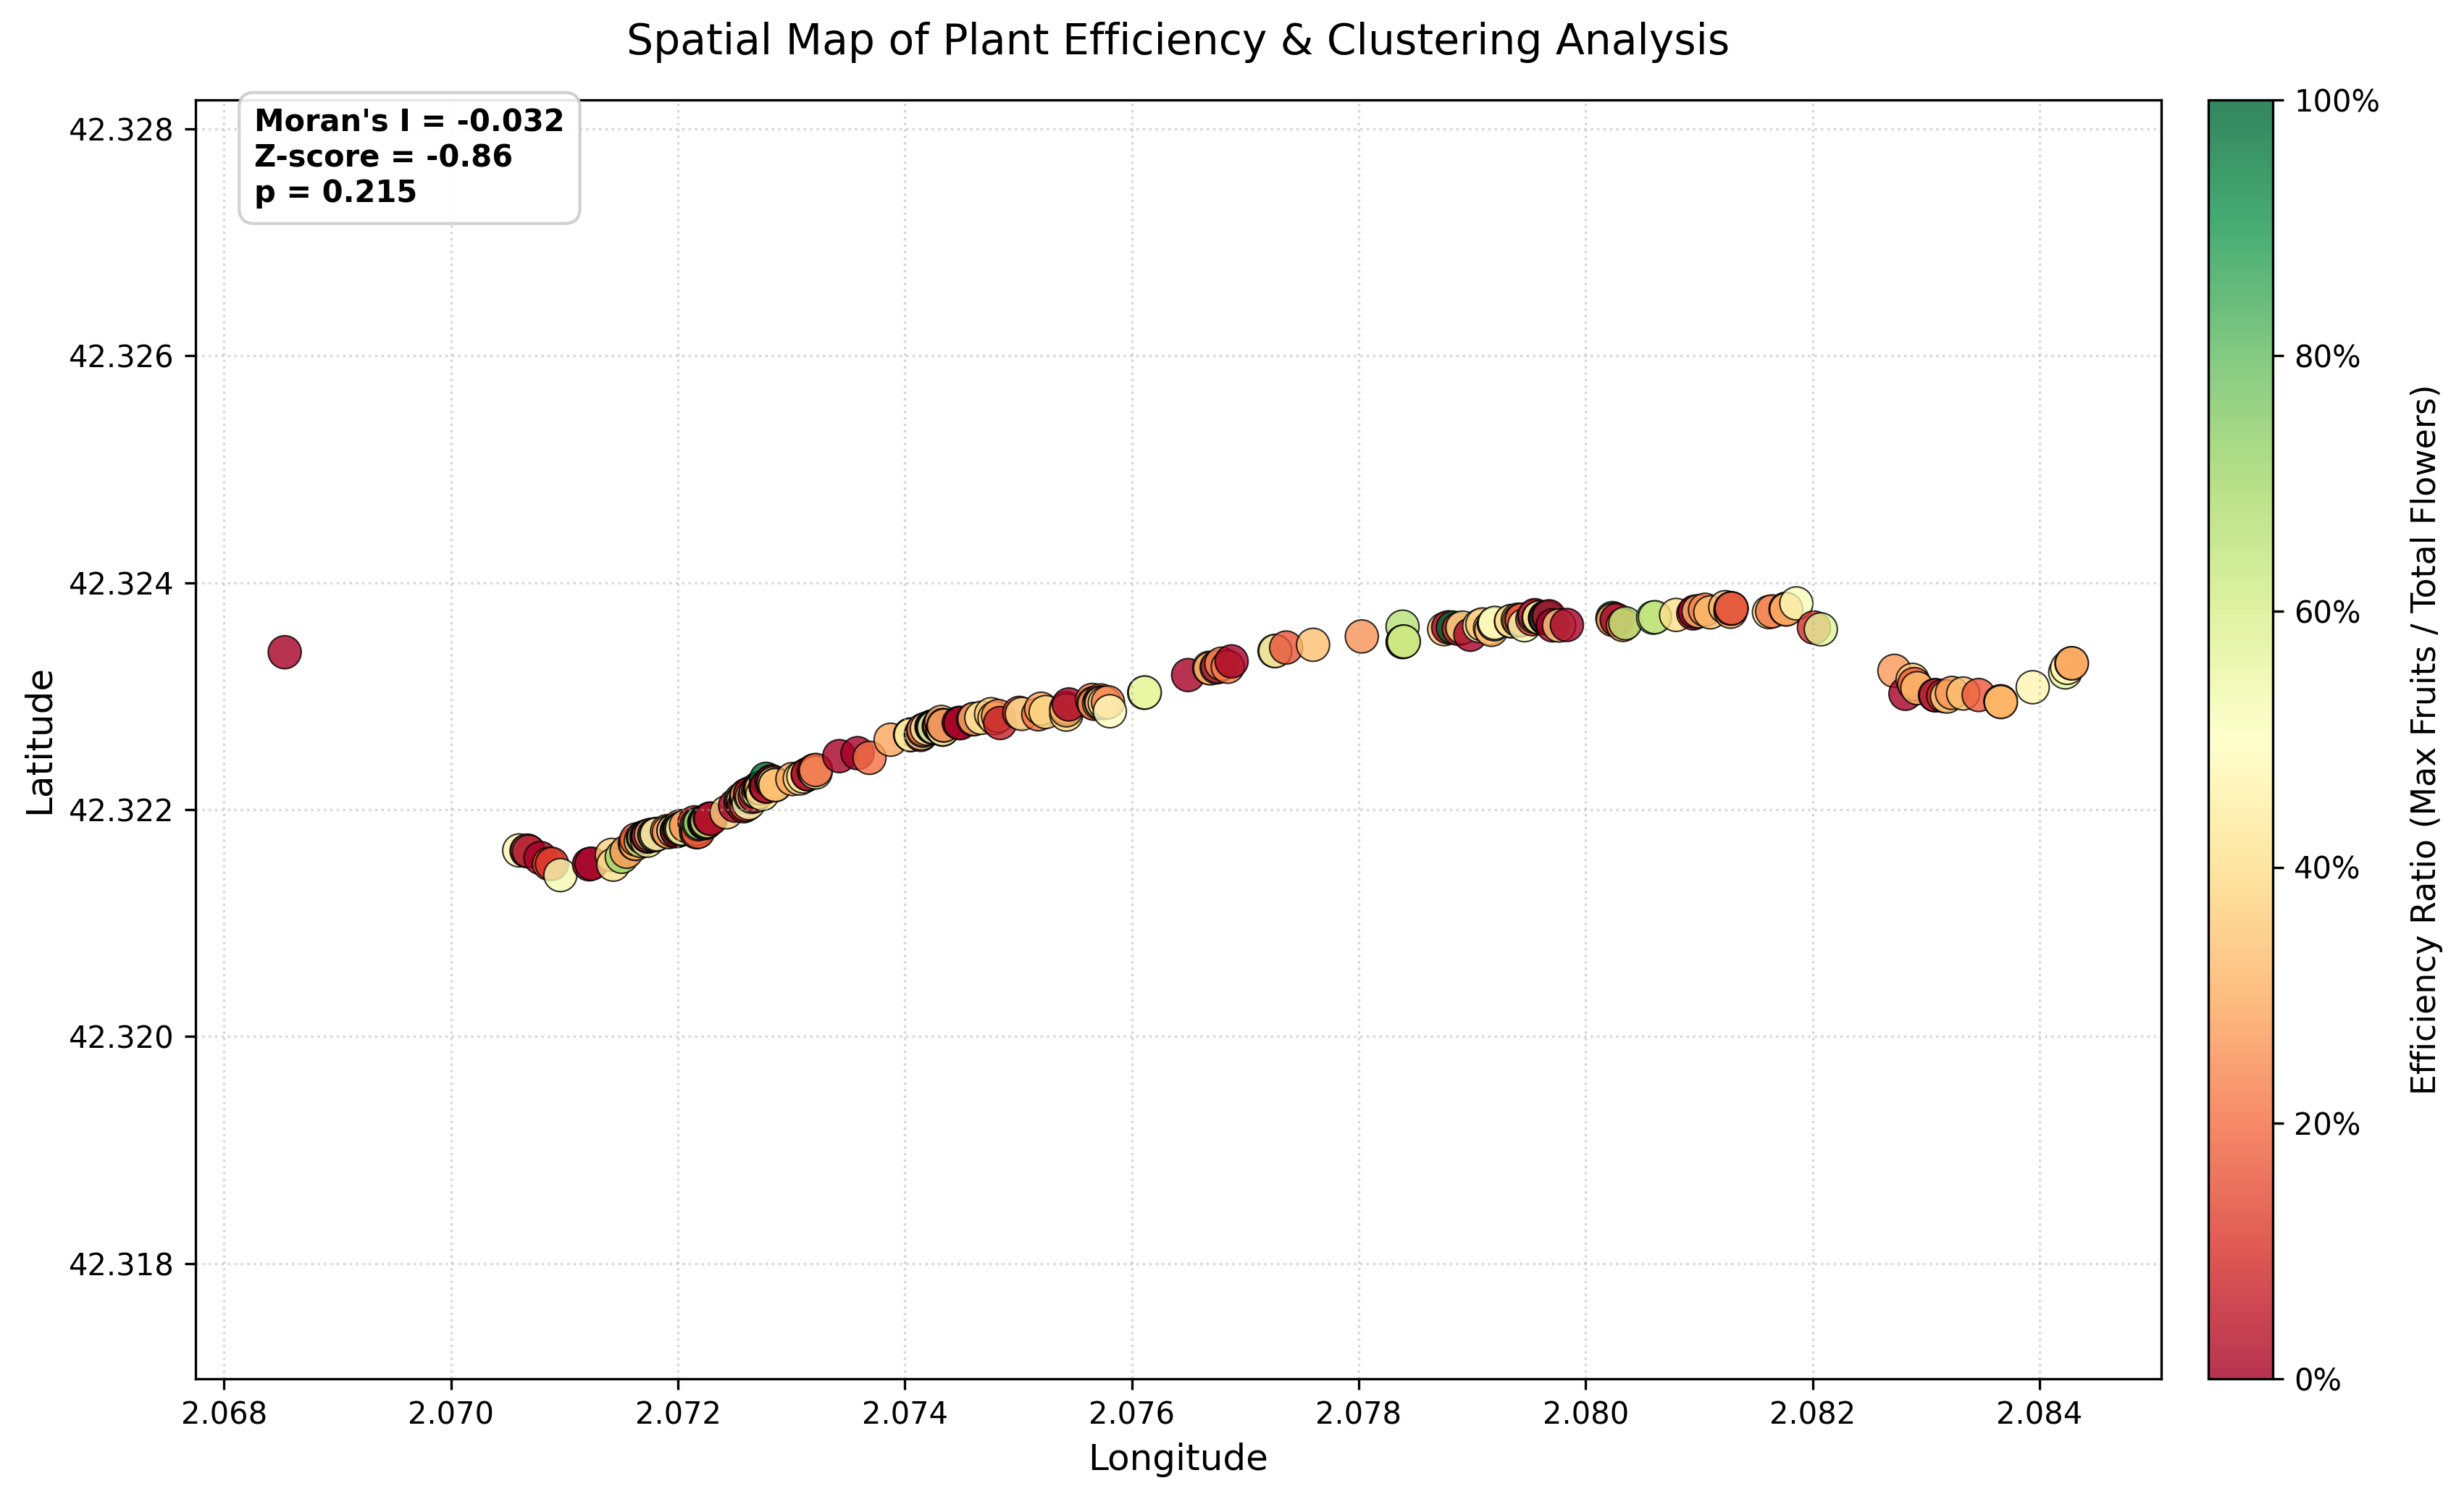

In [ ]:
from esda.moran import Moran
from libpysal.weights import DistanceBand, KNN

# 1. AGGREGATE & MERGE DATA
plant_df = (
    df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

plant_df["efficiency"] = plant_df["seed_max"] / plant_df["flower_total"]

location_df = (
    df_coordinates.groupby("PlantID")
    .agg(latitude=("Latitude", "first"), longitude=("Longitude", "first"))
    .reset_index()
)

merged_df = pd.merge(plant_df, location_df, on="PlantID", how="inner")

# Filter out impossible efficiencies (>1.0) and NaNs before spatial analysis
merged_df = merged_df[
    (merged_df["efficiency"] <= 1.0) & (merged_df["efficiency"].notna())
].copy()
merged_df = merged_df.sort_values("longitude")

# 2. QUANTIFY SPATIAL CLUSTERING (Global Moran's I)
# Extract 2D Spatial Coordinates (Longitude, Latitude)
coords = list(zip(merged_df["longitude"], merged_df["latitude"]))

# Build a spatial weights matrix (e.g., k=6 nearest neighbors per plant)
# You can adjust k based on how close neighbor plants are in your field site
w = KNN.from_array(coords, k=6)
w.transform = "R"  # Row-standardize weights

# Run Moran's I Test on Efficiency
mi = Moran(merged_df["efficiency"], w)

# --- TERMINAL OUTPUT FOR YOUR SUPERVISOR ---
print("=== SPATIAL CLUSTERING ANALYSIS (GLOBAL MORAN'S I) ===")
print(f"Sample Size (N): {len(merged_df)} plants")
print(f"Observed Moran's I: {mi.I:.4f}")
print(f"Expected Moran's I (under randomness): {mi.EI:.4f}")
print(f"Z-Score: {mi.z_sim:.4f}")
print(f"P-value (Permutations): {mi.p_sim:.4e}")

if mi.p_sim < 0.05:
    if mi.I > mi.EI:
        print("RESULT: Significant Positive Spatial Clustering (High efficiency plants cluster together).")
    else:
        print("RESULT: Significant Spatial Dispersion (High/low efficiency plants alternate).")
else:
    print("RESULT: No statistically significant spatial clustering observed (Random distribution).")
print("========================================================\n")


# 3. VISUALIZATION (Updated with Spatial Statistics Box)
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

sc = ax.scatter(
    merged_df["longitude"],
    merged_df["latitude"],
    c=merged_df["efficiency"],
    cmap="RdYlGn",
    vmin=0.0,
    vmax=1.0,
    s=120,
    alpha=0.8,
    edgecolors="k",
    linewidth=0.5,
    label="Individual Plants",
)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Efficiency Ratio (Max Fruits / Total Flowers)", fontsize=11, labelpad=10)
cbar.ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))

ax.set_title("Spatial Map of Plant Efficiency & Clustering Analysis", fontsize=14, pad=15)
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True, linestyle=":", alpha=0.5)

# Annotate Moran's I metrics on the map
p_str = "< 0.001" if mi.p_sim < 0.001 else f"= {mi.p_sim:.3f}"
annot_text = f"Moran's I = {mi.I:.3f}\nZ-score = {mi.z_sim:.2f}\np {p_str}"
ax.text(
    0.03,
    0.92,
    annot_text,
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9, edgecolor="#cccccc"),
)

plt.tight_layout()
plt.show()

Q5: **Does late bloomers have a higher efficency? (Look at when the peak flower is happening and comapare it to the plant efficiency)**

/var/folders/7b/tyzwtcv13pz7k6db8rvxss_r0000gn/T/ipykernel_73999/2988146265.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["end"])


⚠️ DATA QUALITY WARNING: Removed 17 plant(s) with impossible efficiency > 100%.
=== PEAK FLOWERING DATE VS. EFFICIENCY (%) ANALYSIS ===
Sample Size (N): 270 unique plants
Average Efficiency: 31.2%
Spearman Correlation: rho = -0.255, p = 2.2380e-05
Result: Significant relationship between peak blooming date and efficiency.



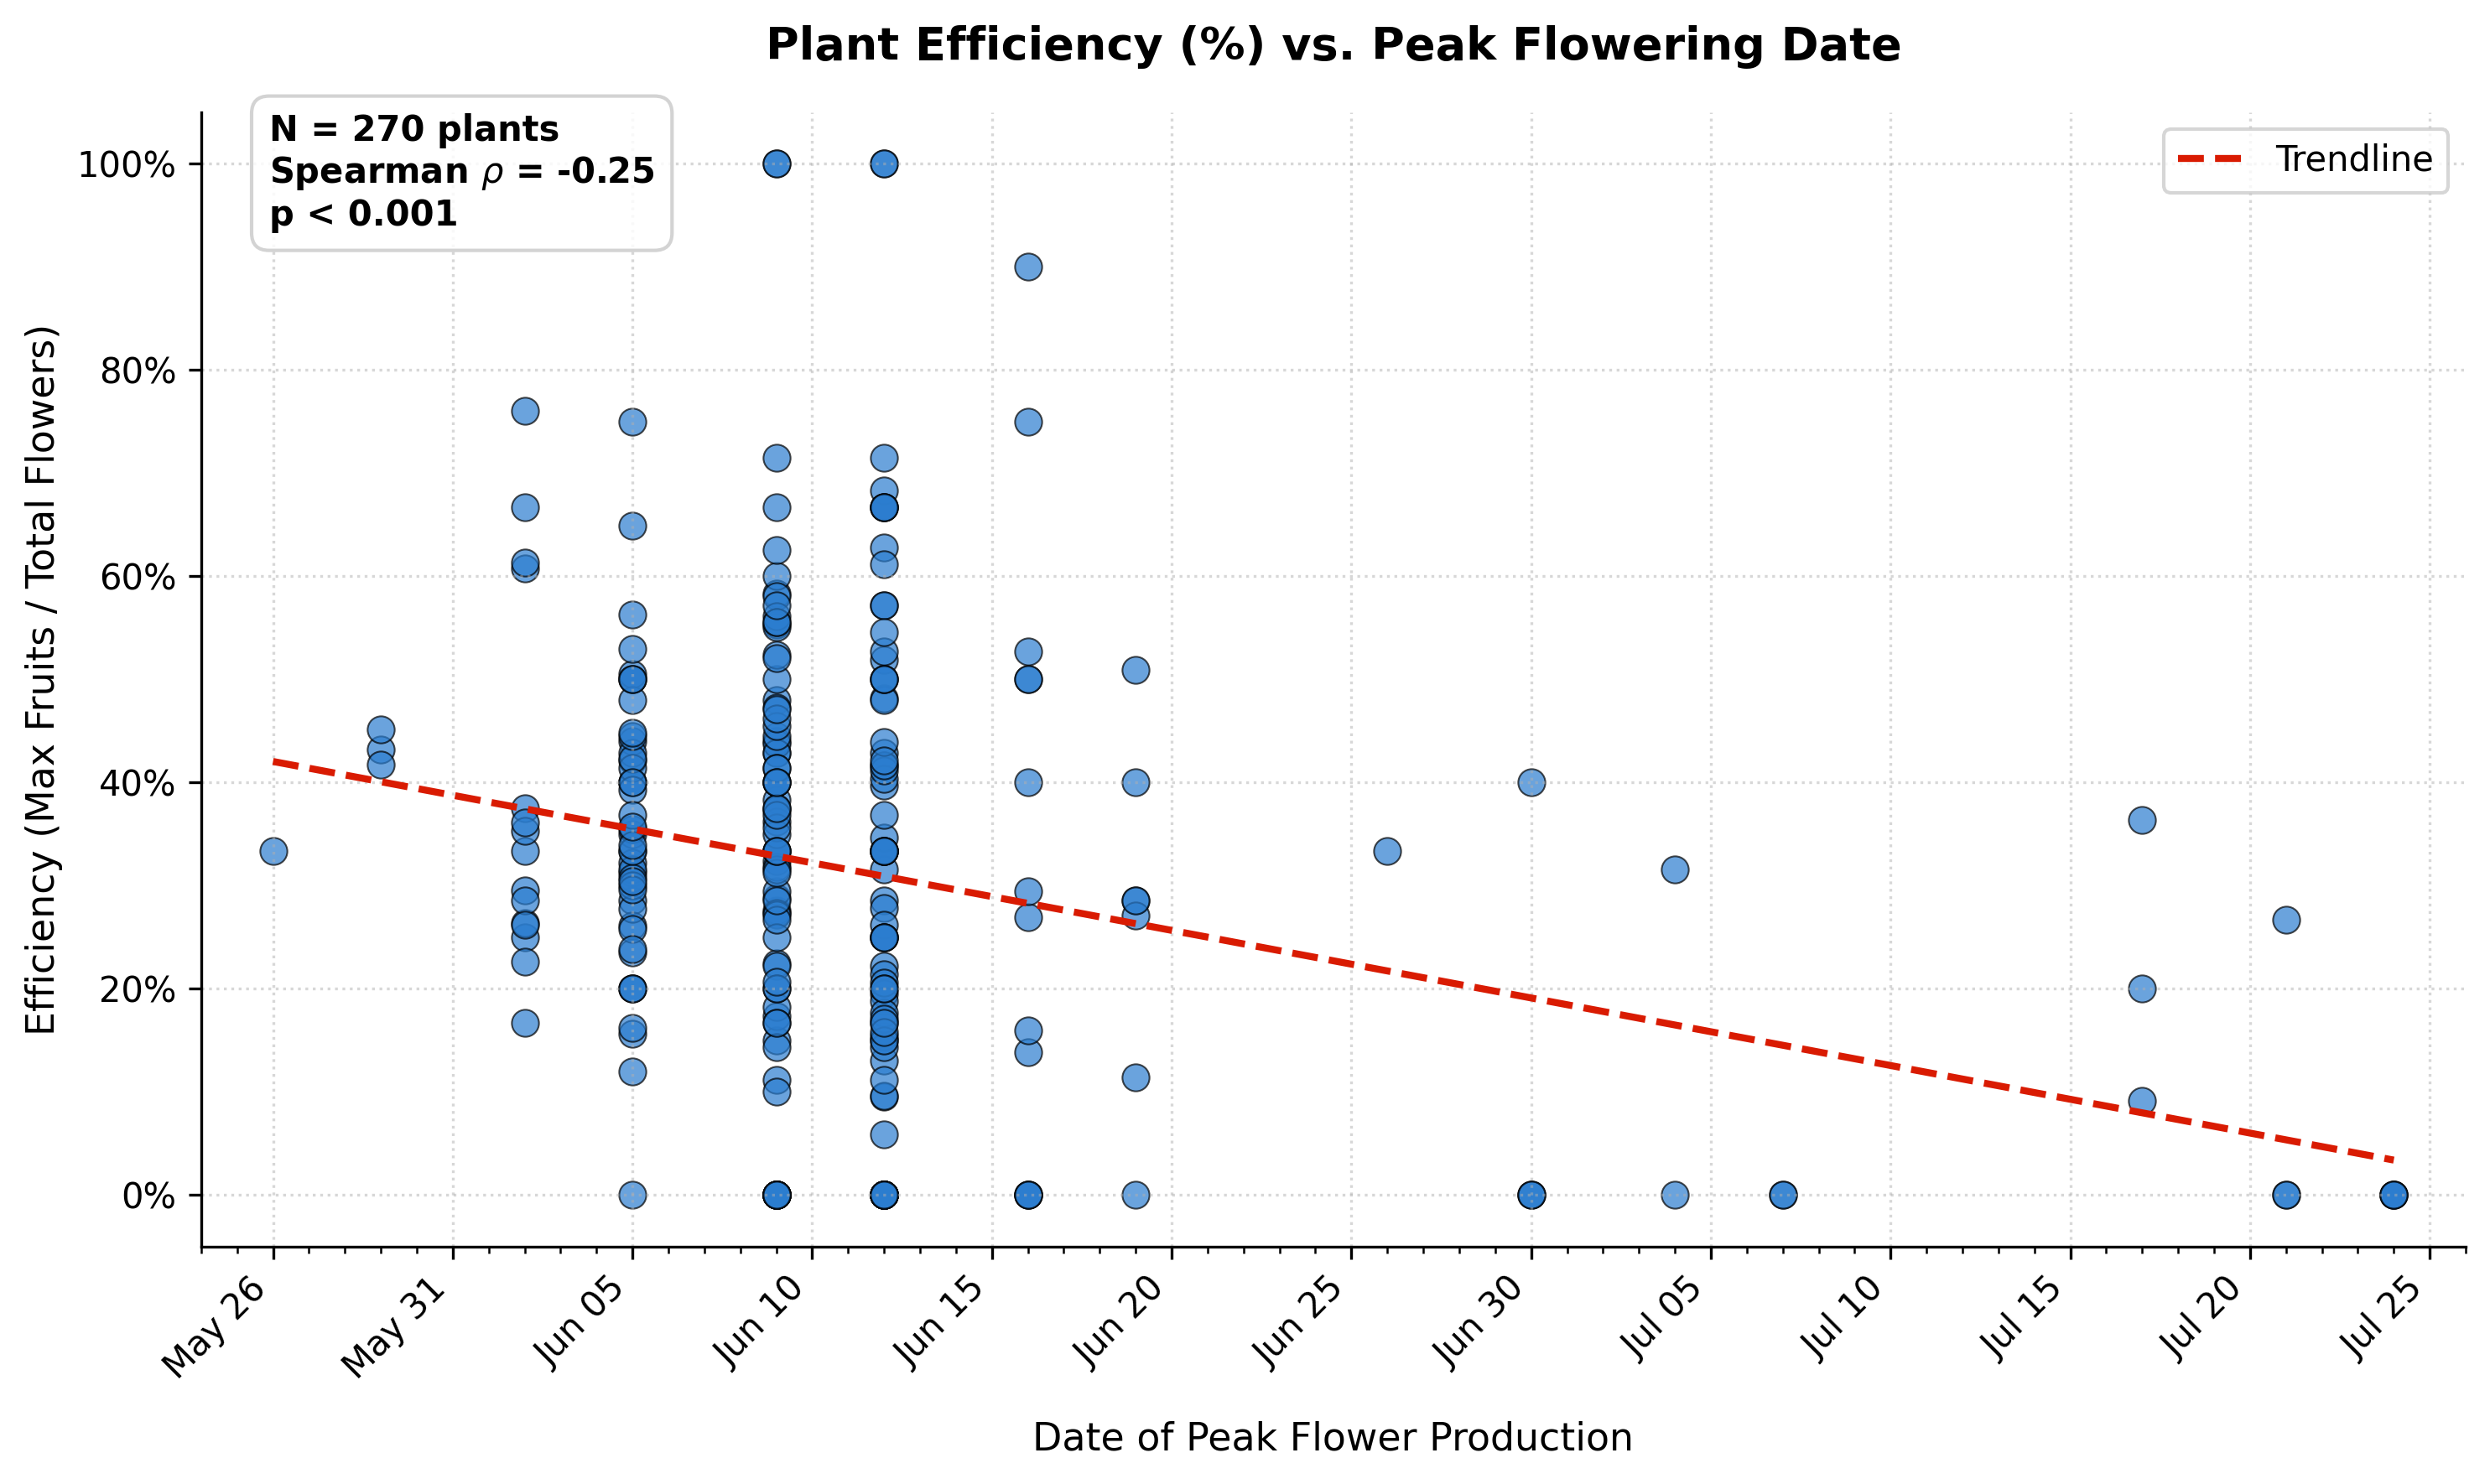

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

# 1. PARSE DATES AND CLEAN DATA
if "end" in df.columns:
    df["Date"] = pd.to_datetime(df["end"])
else:
    df["Date"] = pd.to_datetime(df.index)

# Ensure PlantID is clean (remove trailing spaces/formatting issues)
df["PlantID"] = df["PlantID"].astype(str).str.strip()

# Drop rows where counts are missing
valid_df = df.dropna(
    subset=["PlantID", "Date", "Estim.Flowers.Nr", "Estim.Fruits.Nr"]
).copy()

# 2. FIND PEAK FLOWERING DATE PER UNIQUE PLANT
# Sort so idxmax consistently picks the earliest date in case of a tie
valid_df = valid_df.sort_values(
    by=["PlantID", "Estim.Flowers.Nr", "Date"], ascending=[True, True, True]
)

idx_peak_flowers = valid_df.groupby("PlantID")["Estim.Flowers.Nr"].idxmax()
peak_dates_df = valid_df.loc[
    idx_peak_flowers, ["PlantID", "Date", "Estim.Flowers.Nr"]
].rename(
    columns={
        "Date": "Peak_Flower_Date",
        "Estim.Flowers.Nr": "Peak_Flower_Count",
    }
)

# 3. AGGREGATE SEASONAL TOTALS STRICTLY PER PLANT
seasonal_summary = (
    valid_df.groupby("PlantID")
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
    )
    .reset_index()
)

# Merge peak dates back with seasonal totals
efficiency_df = pd.merge(seasonal_summary, peak_dates_df, on="PlantID")

# Filter out zero total flowers
efficiency_df = efficiency_df[efficiency_df["flower_total"] > 0].copy()

# Calculate Efficiency Percentage (Max Fruits / Total Flowers * 100)
efficiency_df["Efficiency_Pct"] = (
    efficiency_df["seed_max"] / efficiency_df["flower_total"]
) * 100

# --- DATA QUALITY FILTER (Remove > 100% Outliers) ---
outliers = efficiency_df[efficiency_df["Efficiency_Pct"] > 100]
if len(outliers) > 0:
    print(
        f"⚠️ DATA QUALITY WARNING: Removed {len(outliers)} plant(s) with impossible efficiency > 100%."
    )

# Keep only biologically realistic values (0% to 100%)
efficiency_df = efficiency_df[efficiency_df["Efficiency_Pct"] <= 100].copy()

# 4. CORRELATION ANALYSIS
efficiency_df["Peak_Date_Ordinal"] = efficiency_df["Peak_Flower_Date"].apply(
    lambda x: x.toordinal()
)

rho, p_val_spearman = stats.spearmanr(
    efficiency_df["Peak_Date_Ordinal"], efficiency_df["Efficiency_Pct"]
)

# --- TERMINAL OUTPUT ---
print("=== PEAK FLOWERING DATE VS. EFFICIENCY (%) ANALYSIS ===")
print(f"Sample Size (N): {len(efficiency_df)} unique plants")
print(f"Average Efficiency: {efficiency_df['Efficiency_Pct'].mean():.1f}%")
print(f"Spearman Correlation: rho = {rho:.3f}, p = {p_val_spearman:.4e}")
if p_val_spearman < 0.05:
    print(
        "Result: Significant relationship between peak blooming date and efficiency."
    )
else:
    print("Result: No statistically significant correlation observed.")
print("=======================================================\n")

# 5. VISUALIZATION
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

sns.scatterplot(
    data=efficiency_df,
    x="Peak_Flower_Date",
    y="Efficiency_Pct",
    color="#2b7dcf",
    alpha=0.7,
    s=60,
    edgecolor="black",
    linewidth=0.5,
    ax=ax,
)

# Linear Fit Line
x_ord = efficiency_df["Peak_Date_Ordinal"].values
y_eff = efficiency_df["Efficiency_Pct"].values

slope, intercept = np.polyfit(x_ord, y_eff, 1)
x_line_ord = np.array([x_ord.min(), x_ord.max()])
y_line_eff = intercept + slope * x_line_ord

x_line_dates = [pd.Timestamp.fromordinal(int(o)) for o in x_line_ord]
ax.plot(
    x_line_dates,
    y_line_eff,
    color="#d91b02",
    linestyle="--",
    linewidth=2,
    label="Trendline",
)

# Formatting Axes
ax.set_title(
    "Plant Efficiency (%) vs. Peak Flowering Date",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Date of Peak Flower Production", fontsize=11, labelpad=10)
ax.set_ylabel("Efficiency (Max Fruits / Total Flowers)", fontsize=11)

ax.yaxis.set_major_formatter(mtick.PercentFormatter())

# --- DENSE DATE AXIS FORMATTING ---
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))  # Tick every 5 days
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=1))  # Tick every 1 day
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.autofmt_xdate(rotation=45)

# Set explicit x-axis limits with small padding
min_date = efficiency_df["Peak_Flower_Date"].min() - pd.Timedelta(days=2)
max_date = efficiency_df["Peak_Flower_Date"].max() + pd.Timedelta(days=2)
ax.set_xlim(min_date, max_date)

# Annotate correlation and N count
p_text = f"p < 0.001" if p_val_spearman < 0.001 else f"p = {p_val_spearman:.3f}"
annot_str = (
    f"N = {len(efficiency_df)} plants\nSpearman $\\rho$ = {rho:.2f}\n{p_text}"
)
ax.text(
    0.03,
    0.90,
    annot_str,
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        alpha=0.85,
        edgecolor="#cccccc",
    ),
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig("../results/peak_flowering_date_vs_efficiency_pct.png", dpi=300)
plt.show()

**Q5: Is plant size correlated to plant efficiency?**

=== STEM HEIGHT VS EFFICIENCY SUMMARY ===
Total plants with valid stem height: 269
Height Cutoffs (cm): [ 22.  52.  60.  75. 110.]
Spearman rho: 0.2859 (p-value: 1.8688e-06)



/var/folders/7b/tyzwtcv13pz7k6db8rvxss_r0000gn/T/ipykernel_51679/2193392132.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


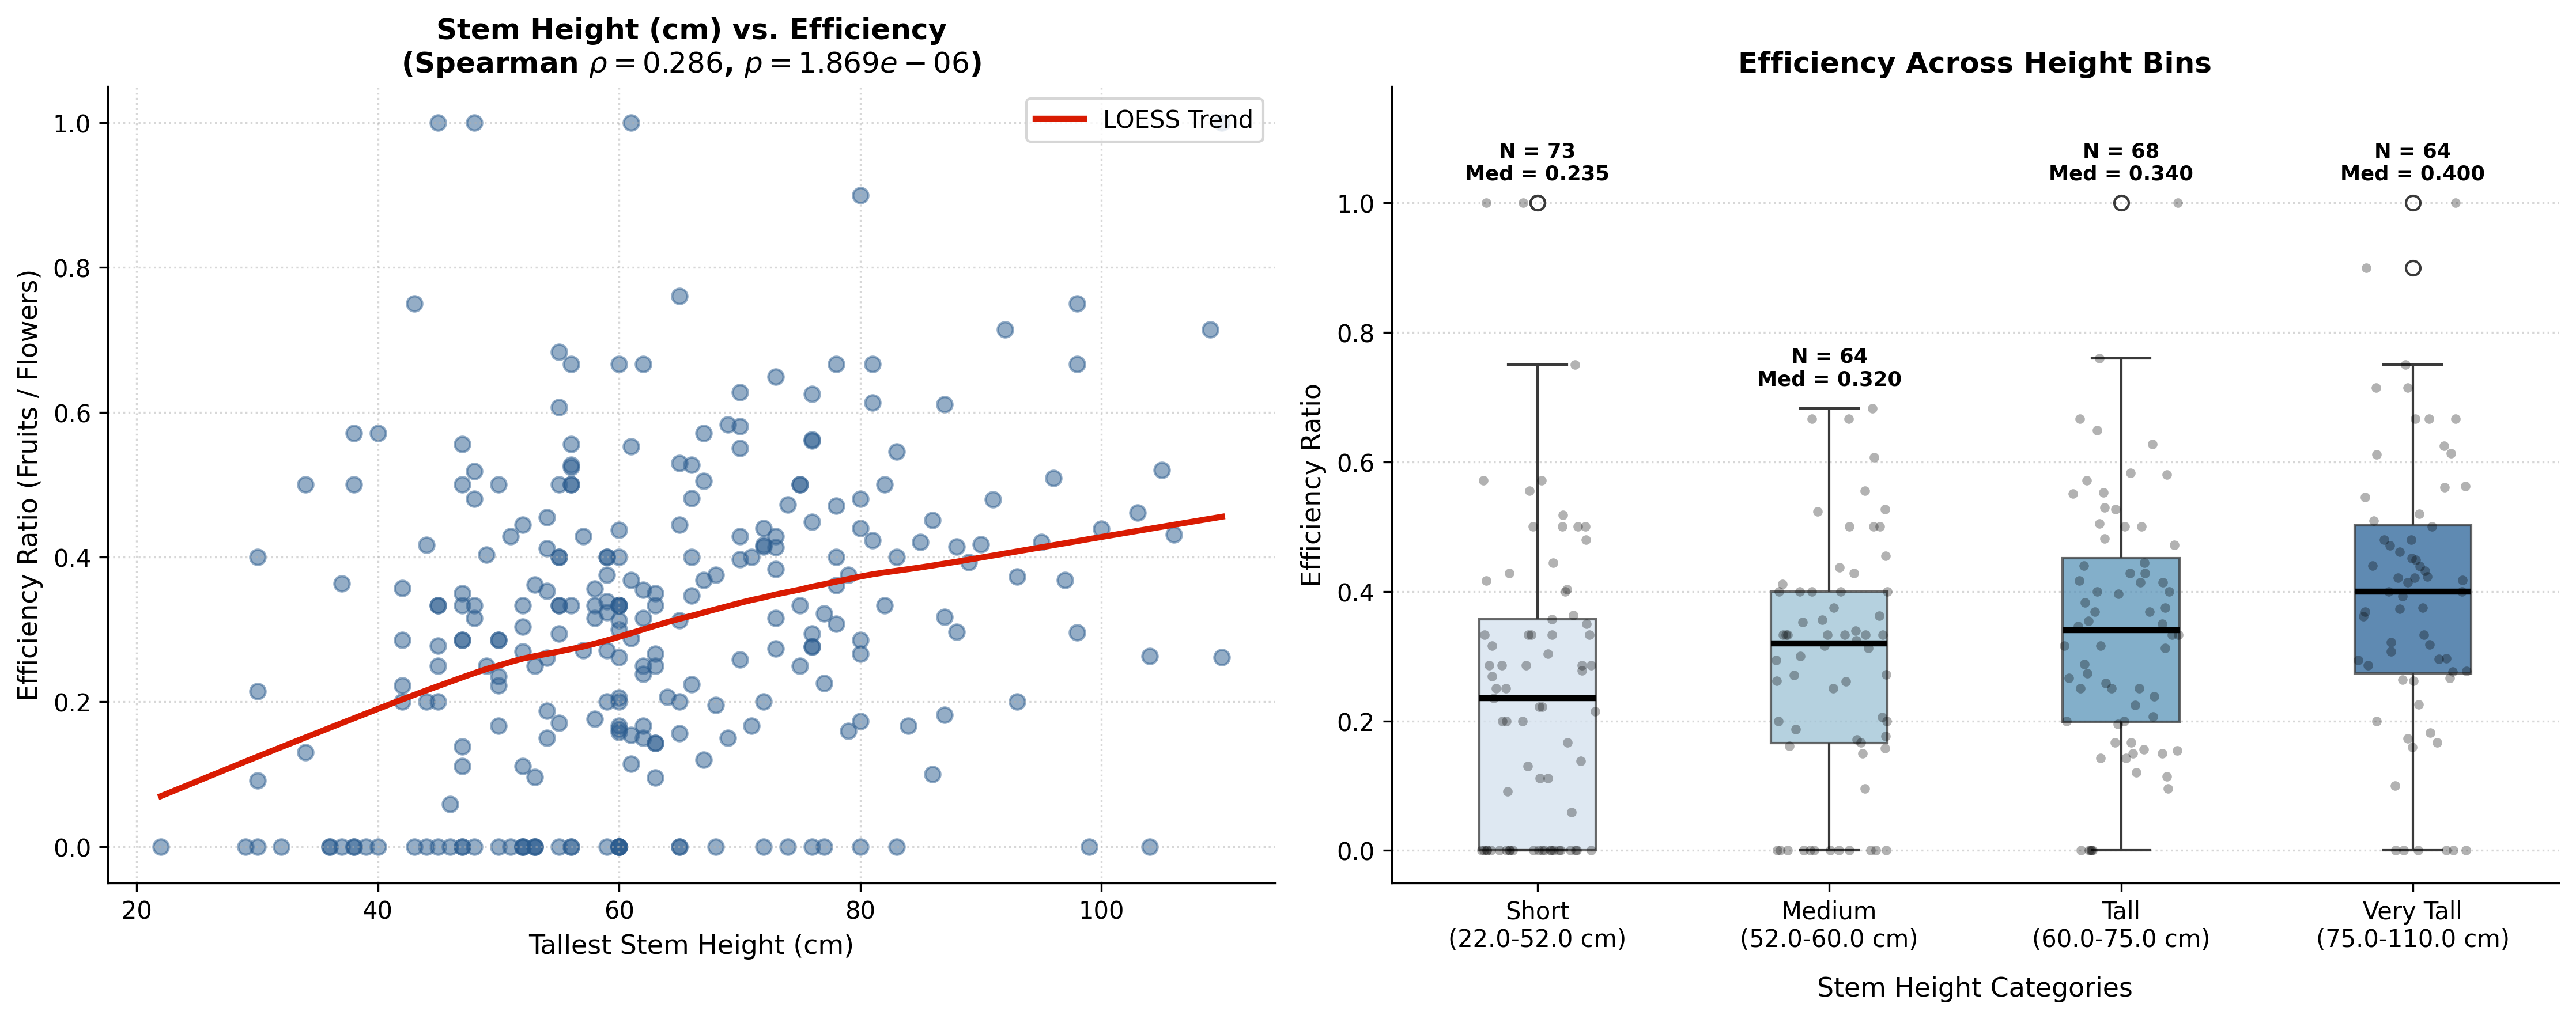

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# 1. LOAD DATA & DROP MISSING STEM HEIGHTS FIRST
df = pd.read_csv("FINAL_DATA_with_perennial_recurrence.csv")

# Filter out rows where Tallest.stem.height_y is missing/NaN
df_clean = df.dropna(subset=["Tallest.stem.height_y"]).copy()

# 2. AGGREGATE DATA BY PLANT
efficiency_df = (
    df_clean.groupby("PlantID", as_index=False)
    .agg(
        flower_total=("Estim.Flowers.Nr", "sum"),
        seed_max=("Estim.Fruits.Nr", "max"),
        stem_height=("Tallest.stem.height_y", "max"),
    )
    .dropna(subset=["stem_height", "flower_total", "seed_max"])
)

# Keep valid observations (height > 0, flower_total > 0)
efficiency_df = efficiency_df[
    (efficiency_df["flower_total"] > 0)
    & (efficiency_df["seed_max"] <= efficiency_df["flower_total"])
    & (efficiency_df["stem_height"] > 0)
].copy()

# Calculate Efficiency
efficiency_df["Efficiency"] = (
    efficiency_df["seed_max"] / efficiency_df["flower_total"]
)

# 3. CREATE Stem Height BINS (Quartiles) & EXTRACT CM RANGES
# Create 4 quartile-based bins
efficiency_df["height_bin_raw"], bin_edges = pd.qcut(
    efficiency_df["stem_height"],
    q=4,
    retbins=True,
    labels=["Short", "Medium", "Tall", "Very Tall"],
)

# Formulate explicit cm range labels based on actual data cutoffs
bin_labels = [
    f"Short\n({bin_edges[0]:.1f}-{bin_edges[1]:.1f} cm)",
    f"Medium\n({bin_edges[1]:.1f}-{bin_edges[2]:.1f} cm)",
    f"Tall\n({bin_edges[2]:.1f}-{bin_edges[3]:.1f} cm)",
    f"Very Tall\n({bin_edges[3]:.1f}-{bin_edges[4]:.1f} cm)",
]

# Map custom string labels with cm ranges
efficiency_df["height_bin_cm"] = pd.qcut(
    efficiency_df["stem_height"], q=4, labels=bin_labels
)

# 4. CORRELATION STATISTICAL TESTS
rho, p_val_spearman = stats.spearmanr(
    efficiency_df["stem_height"], efficiency_df["Efficiency"]
)

print("=== STEM HEIGHT VS EFFICIENCY SUMMARY ===")
print(f"Total plants with valid stem height: {len(efficiency_df)}")
print(f"Height Cutoffs (cm): {bin_edges.round(2)}")
print(f"Spearman rho: {rho:.4f} (p-value: {p_val_spearman:.4e})")
print("=========================================\n")

# 5. VISUALIZATION
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# --- PANEL 1: Continuous Scatter with LOESS Curve ---
sns.regplot(
    data=efficiency_df,
    x="stem_height",
    y="Efficiency",
    lowess=True,
    scatter_kws={"alpha": 0.5, "color": "#2b5c8f", "s": 40},
    line_kws={"color": "#d91b02", "linewidth": 2.5, "label": "LOESS Trend"},
    ax=ax1,
)

ax1.set_title(
    f"Stem Height (cm) vs. Efficiency\n(Spearman $\\rho = {rho:.3f}$, $p = {p_val_spearman:.3e}$)",
    fontsize=12,
    fontweight="bold",
)
ax1.set_xlabel("Tallest Stem Height (cm)", fontsize=11)
ax1.set_ylabel("Efficiency Ratio (Fruits / Flowers)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="upper right")

# --- PANEL 2: Binned Boxplot with cm Ranges ---
sns.boxplot(
    data=efficiency_df,
    x="height_bin_cm",
    y="Efficiency",
    palette="Blues",
    width=0.4,
    ax=ax2,
    boxprops=dict(alpha=0.75),
    medianprops=dict(color="black", linewidth=2.5),
)

sns.stripplot(
    data=efficiency_df,
    x="height_bin_cm",
    y="Efficiency",
    color="black",
    alpha=0.3,
    size=4,
    jitter=0.2,
    ax=ax2,
)

ax2.set_title(
    "Efficiency Across Height Bins",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Stem Height Categories", fontsize=11, labelpad=10)
ax2.set_ylabel("Efficiency Ratio", fontsize=11)
ax2.grid(axis="y", linestyle=":", alpha=0.5)

# Annotate sample sizes and medians per bin
for i, label in enumerate(bin_labels):
    group_data = efficiency_df[efficiency_df["height_bin_cm"] == label]["Efficiency"]
    n_obs = len(group_data)
    if n_obs > 0:
        med_val = group_data.median()
        max_val = group_data.max()
        ax2.text(
            i,
            max_val + (efficiency_df["Efficiency"].max() * 0.03),
            f"N = {n_obs}\nMed = {med_val:.3f}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
        )

ax2.set_ylim(top=efficiency_df["Efficiency"].max() * 1.18)

# Clean up layout
for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

TO DO: 
look at what happend to plant that have an efficiecy higher than 100%

**could you somehow quantative how significan the clustering is?**

compare space to effciency and see if it is correlated, is it clustered in a significant way? 

compare age and size (number of stems and high) comapre to the efficiency. 

look at flower color if you have that data



Look at this: number of fruits according to number of days (how many days they did flower, ranges of 3, 6, 9 days etc.) Plants with more flowering dates would have more fruits. 


CHECKED
- For plot 1, look into the data doip for countet fruits and try to understand why this dip is happening. Could it be that plants are missing, did people not find all plants, is it because number of stems is lower than before. Also look if it is related to certian plants or if it on avergage is less fruits per plant. 

CHECKED
- Look at the max fruits (y-axis) over the total flowers (x-axis) to look at the change of the ratio between them. 

- You can on the map color scale each ID depending of the number of fruits or the number of flowers it has. 

CHECKED
- make a plot that is ordered my the number of efficiency along the position of the plant on the map. So it will be plant along the map and you will be able to see if efficiency increase/decrease/stablelize along the core. 


- Make a plot that looks at the total number of stems at the end of the season against the efficiency to measure if larger plants have more frutis per flowers than smaller plants. 

CHECKED
- make a significant test (t-test or something else?) to see if the late bloomers are actually correct. 

CHECKED
- Don't replace but try a different measure: most amount of flowers for a date of the plant. (so date of peak flower). This is to look at the timing in a different way and to understand if late blowers have higher efficiency or not. 

maybe add a regression model adding more factors.

In [ ]:
import os
import pandas as pd


def locate_file(filename):
    if os.path.exists(filename):
        return filename
    for root, dirs, files in os.walk("."):
        if filename in files:
            return os.path.join(root, filename)
    for root, dirs, files in os.walk(".."):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Could not locate '{filename}' in directory tree.")


# 1. Load data
path_final = locate_file("FINAL_DATA_forJenny_IntensiveSurvey_filtered.csv")
path_2025 = locate_file("forJenny_IntensiveSurvey2025.csv")

final_df = pd.read_csv(path_final)
survey_2025_df = pd.read_csv(path_2025)

# Strip spaces
final_df.columns = final_df.columns.str.strip()
survey_2025_df.columns = survey_2025_df.columns.str.strip()


# 2. Case-insensitive column matcher
def find_best_col(df, target_str):
    for col in df.columns:
        # Match ignoring dots, underscores, spaces, and case
        clean_col = col.lower().replace(".", "").replace("_", "").replace(" ", "")
        clean_target = (
            target_str.lower().replace(".", "").replace("_", "").replace(" ", "")
        )
        if clean_target in clean_col:
            return col
    return None


plant_col = find_best_col(survey_2025_df, "PlantID") or "PlantID"
flw_col = find_best_col(survey_2025_df, "Flowering.stems")
frt_col = find_best_col(survey_2025_df, "Fruiting.stems")
hgt_col = find_best_col(survey_2025_df, "Tallest.stem.height")
col_col = find_best_col(survey_2025_df, "FlowerColour")
alive_col = find_best_col(survey_2025_df, "FirstAlive")

# Print found columns for verification
print("Matched target columns in survey file:")
print(
    f"  PlantID: {plant_col}\n  Flowering Stems: {flw_col}\n  Fruiting Stems: {frt_col}"
)
print(f"  Tallest Height: {hgt_col}\n  Color: {col_col}\n  FirstAlive: {alive_col}\n")

# 3. Create mapping to standardize names
column_mapping = {
    plant_col: "PlantID",
    flw_col: "Flowering.stems.Nr",
    frt_col: "Fruiting.stems.Nr",
    hgt_col: "Tallest.stem.height",
    col_col: "FlowerColour",
    alive_col: "FirstAlive",
}
# Filter out any None values
column_mapping = {k: v for k, v in column_mapping.items() if k is not None}

# Extract and rename
traits_df = survey_2025_df[list(column_mapping.keys())].copy()
traits_df = traits_df.rename(columns=column_mapping)

# 4. Standardize PlantID as clean strings
final_df["PlantID"] = final_df["PlantID"].astype(str).str.strip()
traits_df["PlantID"] = traits_df["PlantID"].astype(str).str.strip()

# 5. Convert numeric columns
numeric_cols = [
    c
    for c in [
        "Flowering.stems.Nr",
        "Fruiting.stems.Nr",
        "Tallest.stem.height",
    ]
    if c in traits_df.columns
]
for col in numeric_cols:
    traits_df[col] = pd.to_numeric(traits_df[col], errors="coerce")

# Build aggregation dictionary dynamically
agg_dict = {}
for c in numeric_cols:
    agg_dict[c] = "max"
if "FlowerColour" in traits_df.columns:
    agg_dict["FlowerColour"] = "first"
if "FirstAlive" in traits_df.columns:
    agg_dict["FirstAlive"] = "first"

# Aggregate per plant
traits_aggregated = traits_df.groupby("PlantID", as_index=False).agg(agg_dict)

# 6. Merge onto master dataset
merged_df = pd.merge(final_df, traits_aggregated, on="PlantID", how="left")

# 7. Print summary and save
print("Success! Merged dataset shape:", merged_df.shape)
added_cols = [c for c in agg_dict.keys() if c in merged_df.columns]
print("\nSample of newly added traits:")
print(merged_df[["PlantID"] + added_cols].head())

merged_df.to_csv("FINAL_DATA_with_plant_traits.csv", index=False)
print("\nSaved file to: 'FINAL_DATA_with_plant_traits.csv'")

Matched target columns in survey file:
  PlantID: PlantID
  Flowering Stems: Flowering.stems.Nr
  Fruiting Stems: Fruiting.stems.Nr
  Tallest Height: Tallest.stem.height
  Color: FlowerColour
  FirstAlive: FirstAlive

Success! Merged dataset shape: (4397, 34)

Sample of newly added traits:
  PlantID
0  PE0008
1  PE0071
2  PE0526
3  PE0529
4  PE0547

Saved file to: 'FINAL_DATA_with_plant_traits.csv'


In [ ]:
import pandas as pd

# Load your newly created dataset
df = pd.read_csv("../data/processed/FINAL_DATA_with_plant_traits.csv")

# Print non-null counts and summary for the newly added columns
trait_cols = [
    "Flowering.stems.Nr",
    "Fruiting.stems.Nr",
    "Tallest.stem.height",
    "FlowerColour",
    "FirstAlive",
]

print("=== MERGED TRAITS DATA COMPLETENESS ===")
for col in trait_cols:
    if col in df.columns:
        valid_count = df[col].notna().sum()
        pct = (valid_count / len(df)) * 100
        print(f"{col:20s}: {valid_count:4d} / {len(df)} non-null ({pct:.1f}%)")
    else:
        print(f"{col:20s}: MISSING FROM CSV")

=== MERGED TRAITS DATA COMPLETENESS ===
Flowering.stems.Nr  : MISSING FROM CSV
Fruiting.stems.Nr   : MISSING FROM CSV
Tallest.stem.height : MISSING FROM CSV
FlowerColour        : MISSING FROM CSV
FirstAlive          : MISSING FROM CSV


In [ ]:
import pandas as pd

df = pd.read_csv("FINAL_DATA_with_plant_traits.csv")

print("=== EXACT COLUMNS IN FINAL_DATA_with_plant_traits.csv ===")
for i, col in enumerate(df.columns):
    print(f"{i}: '{col}'")

=== EXACT COLUMNS IN FINAL_DATA_with_plant_traits.csv ===
0: 'Unnamed: 0'
1: 'PlantID'
2: 'end'
3: 'Plant.ID'
4: 'Confirm_Plant.ID'
5: 'Type.of.sampling'
6: 'Estim.Flowers.Nr'
7: 'Estim.Fruits.Nr'
8: 'Total.plant.height'
9: 'Flowering.stems.Nr_x'
10: 'Fruiting.stems.Nr_x'
11: 'Comments.x'
12: 'Photo'
13: 'Photo_URL'
14: 'X_id'
15: 'X_uuid'
16: 'X_submitted_by'
17: 'Latitude.x'
18: 'Longitude.x'
19: 'Estim.Flowers.No'
20: 'Tallest.stem.height_x'
21: 'Comments.y'
22: 'Latitude.y'
23: 'Longitude.y'
24: 'FlowerColour_x'
25: 'Red'
26: 'Yellow'
27: 'Venation'
28: 'FirstAlive_x'
29: 'Flowering.stems.Nr_y'
30: 'Fruiting.stems.Nr_y'
31: 'Tallest.stem.height_y'
32: 'FlowerColour_y'
33: 'FirstAlive_y'


In [ ]:
import pandas as pd

# 1. Load the merged file
df = pd.read_csv("../data/processed/FINAL_DATA_with_plant_traits.csv")

# 2. Combine _x and _y columns to prioritize valid trait data
traits = [
    "Flowering.stems.Nr",
    "Fruiting.stems.Nr",
    "Tallest.stem.height",
    "FlowerColour",
    "FirstAlive",
]

for trait in traits:
    col_x = f"{trait}_x"
    col_y = f"{trait}_y"

    if col_x in df.columns and col_y in df.columns:
        # Combine: keep _x value, but if missing/NaN, fill with _y
        df[trait] = df[col_x].combine_first(df[col_y])
        # Drop the temporary _x and _y columns
        df = df.drop(columns=[col_x, col_y])
    elif col_x in df.columns:
        df = df.rename(columns={col_x: trait})
    elif col_y in df.columns:
        df = df.rename(columns={col_y: trait})

# 3. Print clean completeness counts
print("=== CLEANED TRAIT COMPLETENESS ===")
for trait in traits:
    valid = df[trait].notna().sum()
    pct = (valid / len(df)) * 100
    print(f"{trait:22s}: {valid:4d} / {len(df)} non-null ({pct:.1f}%)")

# 4. Save clean master file
df.to_csv("FINAL_DATA_with_plant_traits_clean.csv", index=False)
print("\nSaved clean master file as 'FINAL_DATA_with_plant_traits_clean.csv'!")

=== CLEANED TRAIT COMPLETENESS ===
Flowering.stems.Nr    : 2697 / 4397 non-null (61.3%)
Fruiting.stems.Nr     : 2697 / 4397 non-null (61.3%)
Tallest.stem.height   : 4397 / 4397 non-null (100.0%)
FlowerColour          :    1 / 4397 non-null (0.0%)
FirstAlive            : 3079 / 4397 non-null (70.0%)

Saved clean master file as 'FINAL_DATA_with_plant_traits_clean.csv'!
